In [3]:
# Import the libraries and locate the folder containing the cell categories.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Find the inner dataset folder containing the category folders.
dataset_folders = [
    path
    for path in Path("/kaggle/input").rglob("PBC_dataset_normal_DIB")
    if path.is_dir() and (path / "basophil").is_dir()
]

if not dataset_folders:
    raise FileNotFoundError(
        "Could not find the folder containing the blood-cell categories."
    )

# Store the correct dataset location.
DATA_DIR = dataset_folders[0]

print("Dataset location:", DATA_DIR)

# Display the category folders to confirm the location is correct.
print("\nCategory folders:")
for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name)

Dataset location: /kaggle/input/datasets/orvile/microscopic-peripheral-blood-cell-images/A dataset for microscopic peripheral blood cell images for development of automatic recognition systems/PBC_dataset_normal_DIB/PBC_dataset_normal_DIB

Category folders:
basophil
eosinophil
erythroblast
ig
lymphocyte
monocyte
neutrophil
platelet


In [4]:
# Create a table of image paths and labels, then count the images.

# Each folder name represents a cell category.
CLASS_NAMES = [
    "basophil",
    "eosinophil",
    "erythroblast",
    "ig",             # Immature granulocytes
    "lymphocyte",
    "monocyte",
    "neutrophil",
    "platelet",
]

image_records = []

for label in CLASS_NAMES:
    # Build the path to the category folder.
    category_folder = DATA_DIR / label

    if not category_folder.is_dir():
        raise FileNotFoundError(
            f"Missing category folder: {category_folder}"
        )

    # Collect image files, including any inside subfolders.
    image_files = sorted(
        path
        for path in category_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    if not image_files:
        raise ValueError(f"No images found in: {category_folder}")

    # Save each image's location and its category.
    for image_path in image_files:
        image_records.append({
            "filepath": str(image_path),
            "label": label,
        })

# Convert the records into a table with one row per image.
df = pd.DataFrame(image_records)

print(f"Total images: {len(df):,}")
print(f"Number of categories: {df['label'].nunique()}")

# Count the images in each category.
category_counts = (
    df["label"]
    .value_counts()
    .rename_axis("Cell type")
    .reset_index(name="Number of images")
)

display(category_counts)

# Preview the first five rows.
display(df.head())

Total images: 17,093
Number of categories: 8


,Cell type,Number of images
0,neutrophil,3330
1,eosinophil,3117
2,ig,2895
3,platelet,2348
4,erythroblast,1551
5,monocyte,1420
6,basophil,1218
7,lymphocyte,1214


,filepath,label
0,/kaggle/input/datasets/orvile/microscopic-peri...,basophil
1,/kaggle/input/datasets/orvile/microscopic-peri...,basophil
2,/kaggle/input/datasets/orvile/microscopic-peri...,basophil
3,/kaggle/input/datasets/orvile/microscopic-peri...,basophil
4,/kaggle/input/datasets/orvile/microscopic-peri...,basophil


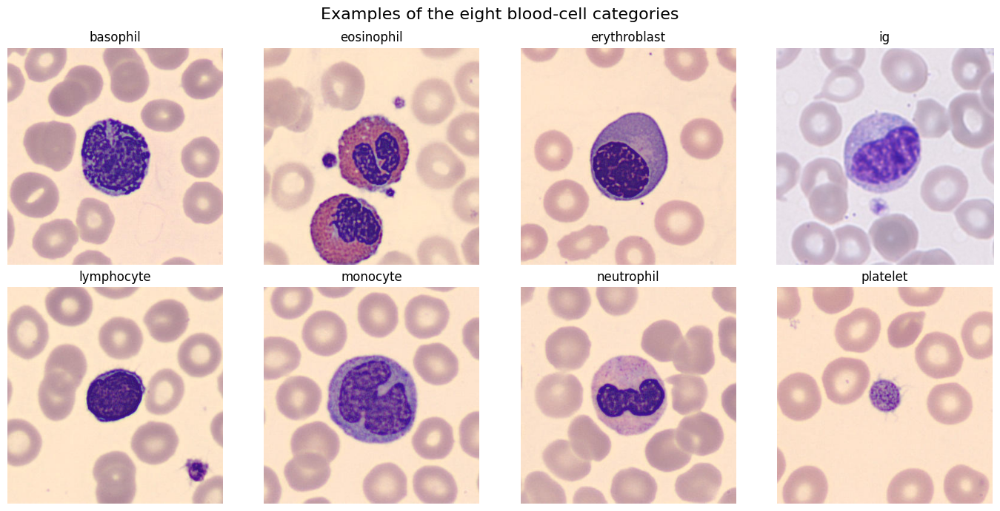

In [5]:
# Display one image from each of the eight categories.

# Set up a grid with two rows and four columns.
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, label in zip(axes.flat, CLASS_NAMES):
    # Select the images belonging to this category.
    category_images = df[df["label"] == label]

    # Choose a repeatable random example.
    example = category_images.sample(
        n=1, random_state=42
    ).iloc[0]

    # Open the image and display it in RGB color.
    with Image.open(example["filepath"]) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(label)
    ax.axis("off")

fig.suptitle("Examples of the eight blood-cell categories", fontsize=16)

# Adjust spacing and display the images.
plt.tight_layout()
plt.show()

In [6]:
# Check image integrity, dimensions, color modes, and exact duplicates.

import hashlib
from collections import Counter
from tqdm.auto import tqdm

image_checks = []
unreadable_images = []

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Checking images"
):
    try:
        # Verify the file structure before loading the image.
        with Image.open(row.filepath) as image:
            image.verify()

        # Reopen the file after verification and load its pixels.
        with Image.open(row.filepath) as image:
            image.load()

            width, height = image.size
            original_mode = image.mode
            rgb_image = image.convert("RGB")

            # Include dimensions in the hash to distinguish image shapes.
            # Identical RGB pixels and dimensions produce the same hash.
            hasher = hashlib.sha256()
            hasher.update(f"{width}x{height}:RGB:".encode())
            hasher.update(rgb_image.tobytes())

        image_checks.append({
            "filepath": row.filepath,
            "label": row.label,
            "width": width,
            "height": height,
            "mode": original_mode,
            "pixel_hash": hasher.hexdigest(),
        })

    except (OSError, ValueError, SyntaxError) as error:
        # Record files that could not be read without stopping the scan.
        unreadable_images.append({
            "filepath": row.filepath,
            "label": row.label,
            "error": str(error),
        })

checked_df = pd.DataFrame(image_checks)
unreadable_df = pd.DataFrame(unreadable_images)

if checked_df.empty:
    raise ValueError("No readable images were found.")

# Include every member of each duplicate group.
duplicate_images = checked_df[
    checked_df.duplicated(subset="pixel_hash", keep=False)
].sort_values("pixel_hash")

# Check whether identical images have different category labels.
labels_per_hash = checked_df.groupby("pixel_hash")["label"].nunique()
conflicting_hashes = labels_per_hash[labels_per_hash > 1].index

conflicting_images = checked_df[
    checked_df["pixel_hash"].isin(conflicting_hashes)
].sort_values("pixel_hash")

print(f"Files checked: {len(df):,}")
print(f"Readable images: {len(checked_df):,}")
print(f"Unreadable images: {len(unreadable_df):,}")
print(f"Duplicate groups: {duplicate_images['pixel_hash'].nunique():,}")
print(
    "Extra copies with identical pixels:",
    f"{checked_df.duplicated(subset='pixel_hash').sum():,}"
)
print(f"Groups with conflicting labels: {len(conflicting_hashes):,}")

# Summarize image dimensions.
print("\nImage dimensions:")
display(
    checked_df.groupby(["width", "height"])
    .size()
    .reset_index(name="Number of images")
    .sort_values("Number of images", ascending=False)
)

# RGB means three color channels; L means grayscale.
print("\nImage color modes:")
display(
    checked_df["mode"]
    .value_counts()
    .rename_axis("Mode")
    .reset_index(name="Number of images")
)

if not unreadable_df.empty:
    print("\nUnreadable files:")
    display(unreadable_df)

if not duplicate_images.empty:
    print("\nDuplicate images — first 20 records:")
    display(duplicate_images[["filepath", "label", "pixel_hash"]].head(20))

if not conflicting_images.empty:
    print("\nIdentical images with conflicting labels:")
    display(conflicting_images[["filepath", "label", "pixel_hash"]])

# Save the complete reports without changing the original dataset.
report_dir = Path("/kaggle/working/data_checks")
report_dir.mkdir(parents=True, exist_ok=True)

checked_df.to_csv(report_dir / "image_inventory.csv", index=False)
unreadable_df.to_csv(report_dir / "unreadable_images.csv", index=False)
duplicate_images.to_csv(report_dir / "duplicate_images.csv", index=False)
conflicting_images.to_csv(report_dir / "conflicting_labels.csv", index=False)

print("\nReports saved to:", report_dir)

Checking images:   0%|          | 0/17093 [00:00<?, ?it/s]

Files checked: 17,093
Readable images: 17,092
Unreadable images: 1
Duplicate groups: 17
Extra copies with identical pixels: 17
Groups with conflicting labels: 1

Image dimensions:


,width,height,Number of images
3,360,363,16639
6,366,369,250
1,360,360,198
2,360,361,2
0,359,360,1
4,361,360,1
5,362,360,1



Image color modes:


,Mode,Number of images
0,RGB,17092


...


Duplicate images — first 20 records:


,filepath,label,pixel_hash
10073,/kaggle/input/datasets/orvile/microscopic-peri...,monocyte,1d9f6b062064d2c57aee791741f0f4e558df2fe69dde42...
11408,/kaggle/input/datasets/orvile/microscopic-peri...,monocyte,1d9f6b062064d2c57aee791741f0f4e558df2fe69dde42...
154,/kaggle/input/datasets/orvile/microscopic-peri...,basophil,2403d5f7c3c98d5c3fc476b11d53d720e82554e6ea0f7e...
922,/kaggle/input/datasets/orvile/microscopic-peri...,basophil,2403d5f7c3c98d5c3fc476b11d53d720e82554e6ea0f7e...
11587,/kaggle/input/datasets/orvile/microscopic-peri...,neutrophil,35be4cbf5e8d107df7c2885ec6edb2fc45c7c6364d32af...
1628,/kaggle/input/datasets/orvile/microscopic-peri...,eosinophil,35be4cbf5e8d107df7c2885ec6edb2fc45c7c6364d32af...
8612,/kaggle/input/datasets/orvile/microscopic-peri...,ig,46642974c4b3361626a6b17e2438480193bfbd1e509704...
8480,/kaggle/input/datasets/orvile/microscopic-peri...,ig,46642974c4b3361626a6b17e2438480193bfbd1e509704...
4310,/kaggle/input/datasets/orvile/microscopic-peri...,eosinophil,51ade048b696cf613444340e7a1d87de9918108cd47ca5...
4131,/kaggle/input/datasets/orvile/microscopic-peri...,eosinophil,51ade048b696cf613444340e7a1d87de9918108cd47ca5...



Identical images with conflicting labels:


,filepath,label,pixel_hash
1628,/kaggle/input/datasets/orvile/microscopic-peri...,eosinophil,35be4cbf5e8d107df7c2885ec6edb2fc45c7c6364d32af...
11587,/kaggle/input/datasets/orvile/microscopic-peri...,neutrophil,35be4cbf5e8d107df7c2885ec6edb2fc45c7c6364d32af...



Reports saved to: /kaggle/working/data_checks


In [8]:
# Clean the image table by excluding unreadable files and duplicate issues.

# checked_df already contains only images that opened successfully.
# Find identical images assigned to different categories.
labels_per_hash = checked_df.groupby("pixel_hash")["label"].nunique()
conflict_hashes = labels_per_hash[labels_per_hash > 1].index

# Set aside all copies with conflicting labels.
conflict_mask = checked_df["pixel_hash"].isin(conflict_hashes)
conflict_df = checked_df.loc[conflict_mask].copy()
consistent_df = checked_df.loc[~conflict_mask].copy()

# Sort by filepath so the same copy is kept each time.
consistent_df = consistent_df.sort_values("filepath")

# Mark extra copies of images that have matching labels.
duplicate_mask = consistent_df.duplicated(
    subset="pixel_hash",
    keep="first"
)

removed_duplicates = consistent_df.loc[duplicate_mask].copy()

# Create the clean table used for the next steps.
clean_df = (
    consistent_df.loc[~duplicate_mask]
    .copy()
    .reset_index(drop=True)
)

# Confirm that all eight categories remain and no exact duplicates remain.
assert set(clean_df["label"]) == set(CLASS_NAMES)
assert clean_df["pixel_hash"].is_unique

print(f"Original image files: {len(df):,}")
print(f"Unreadable files excluded: {len(unreadable_df):,}")
print(f"Conflicting-label images excluded: {len(conflict_df):,}")
print(f"Extra duplicate copies excluded: {len(removed_duplicates):,}")
print(f"Clean images remaining: {len(clean_df):,}")

# Compare the original and cleaned category counts.
category_summary = pd.DataFrame({
    "Original files": df["label"].value_counts(),
    "Clean images": clean_df["label"].value_counts(),
}).reindex(CLASS_NAMES)

category_summary["Excluded"] = (
    category_summary["Original files"]
    - category_summary["Clean images"]
)

display(category_summary)

# Save the clean inventory and exclusion records.
output_dir = Path("/kaggle/working/data_checks")
output_dir.mkdir(parents=True, exist_ok=True)

clean_df.to_csv(
    output_dir / "clean_image_inventory.csv", index=False
)
conflict_df.to_csv(
    output_dir / "excluded_label_conflicts.csv", index=False
)
removed_duplicates.to_csv(
    output_dir / "excluded_duplicate_copies.csv", index=False
)
unreadable_df.to_csv(
    output_dir / "excluded_unreadable_files.csv", index=False
)

print("\nTables saved to:", output_dir)

Original image files: 17,093
Unreadable files excluded: 1
Conflicting-label images excluded: 2
Extra duplicate copies excluded: 16
Clean images remaining: 17,074


,Original files,Clean images,Excluded
label,,,
basophil,1218,1212,6
eosinophil,3117,3110,7
erythroblast,1551,1551,0
ig,2895,2892,3
lymphocyte,1214,1214,0
monocyte,1420,1419,1
neutrophil,3330,3328,2
platelet,2348,2348,0



Tables saved to: /kaggle/working/data_checks


In [9]:
# Set a fixed random seed and split the data into development and test sets.

import random
import numpy as np
from sklearn.model_selection import train_test_split

# Keep the split and NumPy/Python random operations repeatable.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Preserve approximately the same category proportions in both sets.
development_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["label"],
    random_state=SEED,
)

# Reset row numbers after splitting.
development_df = development_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Check that no files or exact duplicate images appear in both sets.
assert set(development_df["filepath"]).isdisjoint(test_df["filepath"])
assert set(development_df["pixel_hash"]).isdisjoint(test_df["pixel_hash"])
assert len(development_df) + len(test_df) == len(clean_df)

# Confirm that every category is represented.
assert set(development_df["label"]) == set(CLASS_NAMES)
assert set(test_df["label"]) == set(CLASS_NAMES)

print(f"Development images: {len(development_df):,}")
print(f"Test images: {len(test_df):,}")

# Compare category counts and proportions.
split_summary = pd.DataFrame({
    "Development": development_df["label"].value_counts(),
    "Test": test_df["label"].value_counts(),
}).reindex(CLASS_NAMES)

split_summary["Development %"] = (
    split_summary["Development"] / len(development_df) * 100
).round(2)

split_summary["Test %"] = (
    split_summary["Test"] / len(test_df) * 100
).round(2)

display(split_summary)

# Save the split so all models use the same development and test images.
split_dir = Path("/kaggle/working/splits")
split_dir.mkdir(parents=True, exist_ok=True)

development_df.to_csv(split_dir / "development.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("\nSplit tables saved to:", split_dir)

Development images: 13,659
Test images: 3,415


,Development,Test,Development %,Test %
label,,,,
basophil,970,242,7.10,7.09
eosinophil,2488,622,18.22,18.21
erythroblast,1241,310,9.09,9.08
ig,2314,578,16.94,16.93
lymphocyte,971,243,7.11,7.12
monocyte,1135,284,8.31,8.32
neutrophil,2662,666,19.49,19.50
platelet,1878,470,13.75,13.76



Split tables saved to: /kaggle/working/splits


In [10]:
# Split the development data into training and validation sets.

# Reserve 20% of the development set for validation.
train_df, validation_df = train_test_split(
    development_df,
    test_size=0.20,
    stratify=development_df["label"],
    random_state=SEED,
)

# Reset row numbers for easier indexing.
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

# Check that no exact image content overlaps between the three sets.
train_hashes = set(train_df["pixel_hash"])
validation_hashes = set(validation_df["pixel_hash"])
test_hashes = set(test_df["pixel_hash"])

assert train_hashes.isdisjoint(validation_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert validation_hashes.isdisjoint(test_hashes)

# Confirm that every image is accounted for.
assert (
    len(train_df) + len(validation_df) + len(test_df)
    == len(clean_df)
)

# Confirm that all eight categories appear in every set.
for subset in [train_df, validation_df, test_df]:
    assert set(subset["label"]) == set(CLASS_NAMES)

# Show the size of each set as a percentage of the cleaned dataset.
split_sizes = pd.DataFrame({
    "Set": ["Training", "Validation", "Test"],
    "Images": [len(train_df), len(validation_df), len(test_df)],
})

split_sizes["Percentage of total"] = (
    split_sizes["Images"] / len(clean_df) * 100
).round(2)

display(split_sizes)

# Check the number of images per category in each set.
category_counts = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": validation_df["label"].value_counts(),
    "Test": test_df["label"].value_counts(),
}).reindex(CLASS_NAMES)

display(category_counts)

# Save the training and validation inventories.
# The existing test split remains unchanged.
split_dir = Path("/kaggle/working/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "training.csv", index=False)
validation_df.to_csv(split_dir / "validation.csv", index=False)

print("Training and validation tables saved to:", split_dir)

,Set,Images,Percentage of total
0,Training,10927,64.0
1,Validation,2732,16.0
2,Test,3415,20.0


,Training,Validation,Test
label,,,
basophil,776,194,242
eosinophil,1990,498,622
erythroblast,993,248,310
ig,1851,463,578
lymphocyte,777,194,243
monocyte,908,227,284
neutrophil,2130,532,666
platelet,1502,376,470


Training and validation tables saved to: /kaggle/working/splits


In [11]:
# Define color, texture, and edge features for each image.

import numpy as np
from skimage.color import rgb2hsv, rgb2gray
from skimage.feature import hog, local_binary_pattern

# Use consistent dimensions so every image produces the same feature count.
IMAGE_SIZE = (128, 128)

def extract_features(filepath):
    # Open the image, convert to RGB, and resize.
    with Image.open(filepath) as image:
        image = image.convert("RGB")
        image = image.resize(IMAGE_SIZE, Image.Resampling.LANCZOS)

        # Convert pixel values from 0–255 to 0–1.
        rgb = np.asarray(image, dtype=np.float32) / 255.0

    features = []
    names = []

    # Measure the average and variation of each color channel.
    for index, channel_name in enumerate(["red", "green", "blue"]):
        channel = rgb[:, :, index]

        features.extend([channel.mean(), channel.std()])
        names.extend([
            f"{channel_name}_mean",
            f"{channel_name}_std",
        ])

    # HSV separates color into hue, saturation, and brightness.
    hsv = rgb2hsv(rgb)

    for index, channel_name in enumerate(
        ["hue", "saturation", "brightness"]
    ):
        # Count pixels in 16 intervals for each channel.
        histogram, _ = np.histogram(
            hsv[:, :, index],
            bins=16,
            range=(0, 1),
        )

        # Express the counts as proportions of the image.
        histogram = histogram.astype(np.float32)
        histogram /= histogram.sum()

        features.extend(histogram)
        names.extend([
            f"{channel_name}_bin_{i}" for i in range(16)
        ])

    # Use grayscale pixels to measure texture and edges.
    gray = rgb2gray(rgb)
    gray_uint8 = np.round(gray * 255).astype(np.uint8)

    # Local Binary Patterns describe small light-and-dark texture patterns.
    lbp = local_binary_pattern(
        gray_uint8,
        P=8,
        R=1,
        method="uniform",
    )

    texture_histogram, _ = np.histogram(
        lbp,
        bins=np.arange(11),
    )

    texture_histogram = texture_histogram.astype(np.float32)
    texture_histogram /= texture_histogram.sum()

    features.extend(texture_histogram)
    names.extend([f"texture_bin_{i}" for i in range(10)])

    # HOG summarizes edge directions in different parts of the image.
    edge_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True,
    )

    features.extend(edge_features)
    names.extend([
        f"edge_feature_{i}" for i in range(len(edge_features))
    ])

    return np.asarray(features, dtype=np.float32), names


# Test extraction on one training image.
sample_path = train_df.iloc[0]["filepath"]
sample_features, feature_names = extract_features(sample_path)

# Check that the feature values contain no missing or infinite values.
assert np.isfinite(sample_features).all()

print("Features per image:", len(sample_features))
print("All feature values are finite:", np.isfinite(sample_features).all())

# Display the first six features: RGB averages and standard deviations.
display(pd.DataFrame({
    "Feature": feature_names[:6],
    "Value": sample_features[:6],
}))

Features per image: 1828
All feature values are finite: True


,Feature,Value
0,red_mean,0.870859
1,red_std,0.168951
2,green_mean,0.735534
3,green_std,0.210398
4,blue_mean,0.724733
5,blue_std,0.076155


In [ ]:
# Traditional models such as SVM and Random Forest require numerical inputs.
# Extract color, texture, and edge measurements to represent each image.
# Flattened pixels are another option, but these features summarize visual patterns.
# CNNs will use image pixel arrays directly and learn their own features.

In [12]:
# Build numerical feature tables for the training and validation images.

from tqdm.auto import tqdm

# Each image becomes one row of color, texture, and edge measurements.
# These tables will be used by the traditional machine-learning models.
def build_feature_table(image_table, description):
    feature_rows = []

    # Preserve the image order so features stay aligned with their labels.
    for filepath in tqdm(
        image_table["filepath"],
        total=len(image_table),
        desc=description,
    ):
        features, names = extract_features(filepath)

        # Confirm that every image produces the same feature definitions.
        assert names == feature_names
        feature_rows.append(features)

    return pd.DataFrame(
        np.stack(feature_rows),
        columns=feature_names,
    )


# Extract features without fitting a model or learning from either set.
X_train = build_feature_table(train_df, "Training features")
X_validation = build_feature_table(
    validation_df, "Validation features"
)

# Store the correct cell categories separately from the input features.
y_train = train_df["label"].reset_index(drop=True)
y_validation = validation_df["label"].reset_index(drop=True)

# Check for missing or infinite feature values and mismatched row counts.
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_validation.to_numpy()).all()
assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)

print("Training feature table:", X_train.shape)
print("Validation feature table:", X_validation.shape)

# Preview the first six features for five training images.
display(X_train.iloc[:5, :6])

# Save features alongside their image paths and labels.
feature_dir = Path("/kaggle/working/features")
feature_dir.mkdir(parents=True, exist_ok=True)

for name, features, inventory in [
    ("training", X_train, train_df),
    ("validation", X_validation, validation_df),
]:
    saved_table = features.copy()
    saved_table.insert(0, "label", inventory["label"].to_numpy())
    saved_table.insert(0, "filepath", inventory["filepath"].to_numpy())

    saved_table.to_csv(
        feature_dir / f"{name}_features.csv.gz",
        index=False,
        compression="gzip",
    )

print("\nFeature tables saved to:", feature_dir)

Training features:   0%|          | 0/10927 [00:00<?, ?it/s]

Validation features:   0%|          | 0/2732 [00:00<?, ?it/s]

Training feature table: (10927, 1828)
Validation feature table: (2732, 1828)


,red_mean,red_std,green_mean,green_std,blue_mean,blue_std
0,0.870859,0.168951,0.735534,0.210398,0.724733,0.076155
1,0.898276,0.159878,0.771618,0.182215,0.735517,0.073957
2,0.843686,0.203883,0.717469,0.224699,0.710051,0.096474
3,0.875362,0.171093,0.748233,0.204071,0.723989,0.085548
4,0.871372,0.153031,0.723446,0.200098,0.713529,0.073938



Feature tables saved to: /kaggle/working/features


In [17]:
# Scale features using training data and apply the same transformation to validation.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Features have different ranges and amounts of variation.
# Scaling prevents large numerical scales from dominating distances or penalties.
# It does not determine which features are most useful.

# Scaling is useful for Logistic Regression, SVM, KNN, and an MLP neural network.
# Tree-based models such as Decision Tree, Random Forest, Extra Trees,
# and XGBoost generally do not need this scaling.
# Image CNNs will use their own pixel preprocessing instead.

# StandardScaler subtracts each training feature's mean and divides by its
# standard deviation. Nonconstant training features then have mean 0 and std 1.
preprocessing = Pipeline([
    ("scaler", StandardScaler()),
])

# Learn the scaling parameters from training data only.
# Using validation or test data here would leak information.
X_train_scaled = preprocessing.fit_transform(X_train)

# Apply those same parameters to validation data without fitting again.
# Validation features do not have to end up with mean 0 and std 1.
X_validation_scaled = preprocessing.transform(X_validation)

# Confirm that scaling produced no missing or infinite values.
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_validation_scaled).all()

# Scaling changes feature values, not the number of rows or columns.
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_validation_scaled.shape)

# Inspect the first six features to check that scaling worked.
scaling_summary = pd.DataFrame({
    "Feature": X_train.columns[:6],
    "Original training mean": X_train.iloc[:, :6].mean().to_numpy(),
    "Scaled training mean": X_train_scaled[:, :6].mean(axis=0),
    "Scaled training std": X_train_scaled[:, :6].std(axis=0),
})

display(scaling_summary)

# During cross-validation, use the original unscaled features in a complete
# pipeline containing preprocessing and the classifier. This fits scaling
# separately within each training fold and prevents leakage between folds.

Scaled training shape: (10927, 1828)
Scaled validation shape: (2732, 1828)


,Feature,Original training mean,Scaled training mean,Scaled training std
0,red_mean,0.873707,-9.783873e-09,0.999999
1,red_std,0.152402,6.813051e-09,1.000000
2,green_mean,0.748610,1.063329e-08,0.999999
3,green_std,0.179558,4.963872e-09,1.000000
4,blue_mean,0.721639,-5.992102e-09,0.999999
5,blue_std,0.075384,-1.636441e-11,0.999998


Original features: 1828
Constant features removed: 0
Selected features: 300
Selected training shape: (10927, 300)
Selected validation shape: (2732, 300)


,Feature,ANOVA F-score,Selected
3,green_std,5055.324918,True
28,saturation_bin_6,4617.340102,True
29,saturation_bin_7,4391.961876,True
1,red_std,4173.613266,True
30,saturation_bin_8,2401.639625,True
32,saturation_bin_10,2383.629188,True
34,saturation_bin_12,2335.685538,True
33,saturation_bin_11,2329.551958,True
36,saturation_bin_14,2222.455084,True
35,saturation_bin_13,2125.632906,True


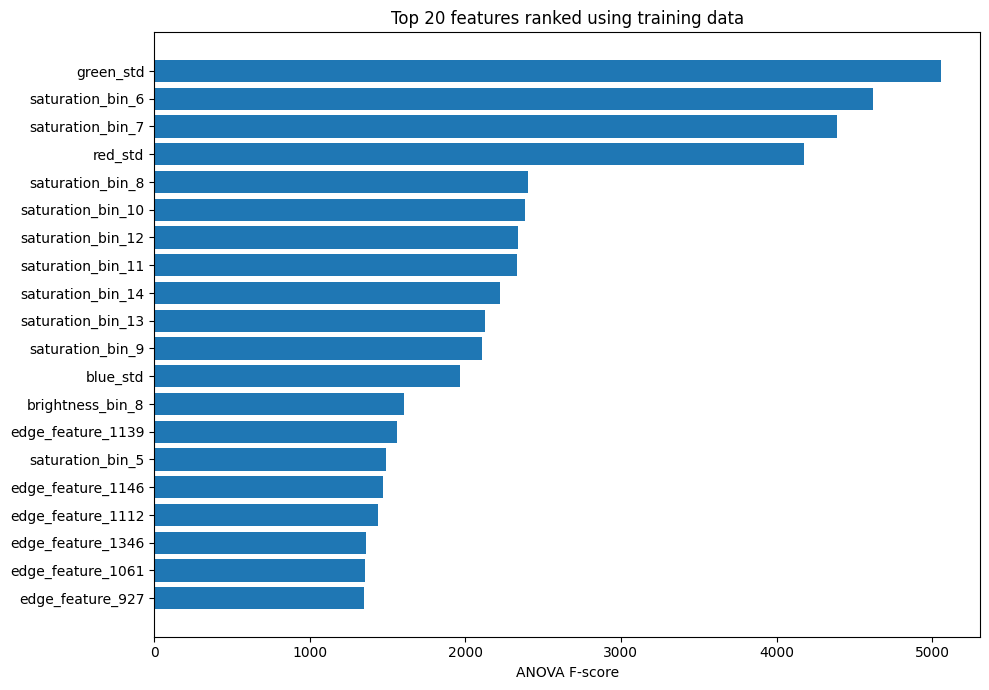

In [18]:
# Select features that help distinguish cell categories using training data only.

from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif

# Start with 300 features to reduce model input size.
# This number will be evaluated later rather than assumed to be optimal.
N_FEATURES = 300

# Remove constant features, then rank the remaining features using ANOVA.
# Higher F-scores indicate stronger differences between category means
# relative to the variation within categories.
feature_selection = Pipeline([
    ("remove_constant", VarianceThreshold(threshold=0.0)),
    ("select", SelectKBest(score_func=f_classif, k=N_FEATURES)),
])

# Learn which features to keep from training features and training labels only.
X_train_selected = feature_selection.fit_transform(
    X_train_scaled,
    y_train,
)

# Keep exactly the same feature columns in the validation set.
# Validation labels are not used to select features.
X_validation_selected = feature_selection.transform(
    X_validation_scaled
)

# Recover the names of features remaining after the constant-feature check.
nonconstant_mask = (
    feature_selection.named_steps["remove_constant"].get_support()
)

nonconstant_names = np.asarray(X_train.columns)[nonconstant_mask]

# Find which of those features were selected.
selector = feature_selection.named_steps["select"]
selected_mask = selector.get_support()
selected_feature_names = nonconstant_names[selected_mask]

# Confirm that the selected tables contain valid values.
assert np.isfinite(X_train_selected).all()
assert np.isfinite(X_validation_selected).all()
assert X_train_selected.shape[1] == N_FEATURES
assert X_validation_selected.shape[1] == N_FEATURES

print("Original features:", X_train.shape[1])
print("Constant features removed:", (~nonconstant_mask).sum())
print("Selected features:", len(selected_feature_names))
print("Selected training shape:", X_train_selected.shape)
print("Selected validation shape:", X_validation_selected.shape)

# Record training-based scores for all nonconstant features.
feature_ranking = pd.DataFrame({
    "Feature": nonconstant_names,
    "ANOVA F-score": selector.scores_,
    "Selected": selected_mask,
}).sort_values("ANOVA F-score", ascending=False)

display(feature_ranking.head(20))

# Plot the highest-scoring features.
# These are individual feature-association scores, not model importance scores.
top_features = feature_ranking.head(20).sort_values("ANOVA F-score")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_features["Feature"], top_features["ANOVA F-score"])
ax.set_xlabel("ANOVA F-score")
ax.set_title("Top 20 features ranked using training data")
plt.tight_layout()
plt.show()

# Save the ranking and the selected feature names in their column order.
selection_dir = Path("/kaggle/working/features")
selection_dir.mkdir(parents=True, exist_ok=True)

feature_ranking.to_csv(
    selection_dir / "training_feature_ranking.csv",
    index=False,
)

pd.DataFrame({"Feature": selected_feature_names}).to_csv(
    selection_dir / "selected_feature_names.csv",
    index=False,
)

Training time: 10.4 seconds


,Set,Accuracy,Macro F1
0,Training,0.9551,0.9525
1,Validation,0.9008,0.8903


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844



Validation classification report:
              precision    recall  f1-score   support

    basophil      0.854     0.876     0.865       194
  eosinophil      0.990     0.974     0.982       498
erythroblast      0.922     0.903     0.912       248
          ig      0.790     0.803     0.797       463
  lymphocyte      0.887     0.887     0.887       194
    monocyte      0.787     0.749     0.767       227
  neutrophil      0.913     0.930     0.922       532
    platelet      0.989     0.992     0.991       376

    accuracy                          0.901      2732
   macro avg      0.891     0.889     0.890      2732
weighted avg      0.901     0.901     0.901      2732



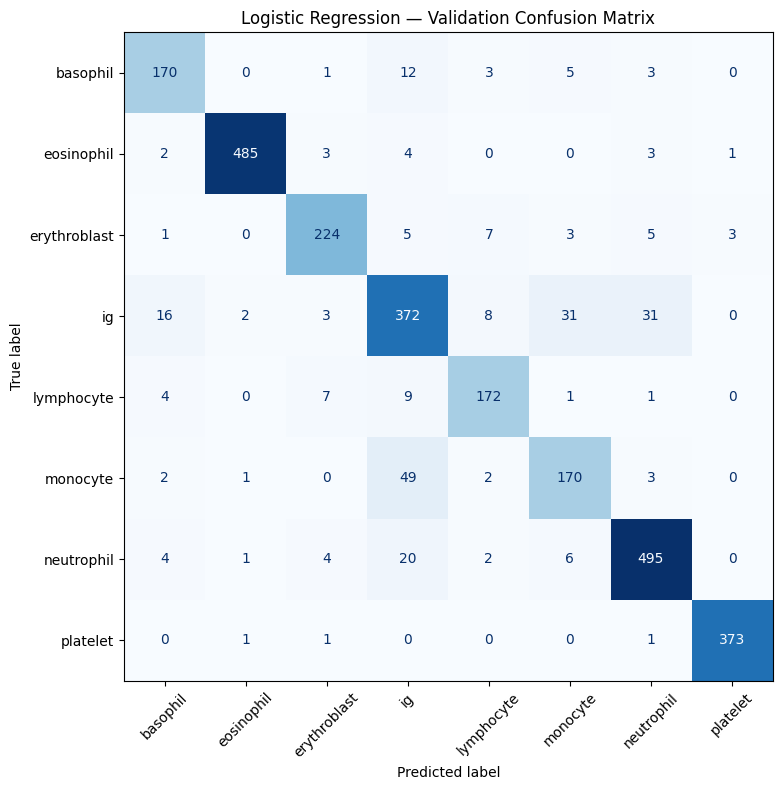

In [19]:
# Train a Logistic Regression baseline and evaluate it on validation images.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from time import perf_counter

# Use fixed settings for the first baseline.
# More iterations give the optimizer additional time to converge.
logistic_model = LogisticRegression(
    max_iter=3000,
    solver="lbfgs",
    C=1.0,
    random_state=SEED,
)

# Learn the relationship between selected features and cell categories.
start_time = perf_counter()
logistic_model.fit(X_train_selected, y_train)
training_seconds = perf_counter() - start_time

# Predict categories for training and validation images.
train_predictions = logistic_model.predict(X_train_selected)
validation_predictions = logistic_model.predict(X_validation_selected)

# Class probabilities are needed to calculate multiclass ROC AUC.
validation_probabilities = logistic_model.predict_proba(
    X_validation_selected
)

# Compare training and validation performance to look for overfitting.
# Macro F1 gives equal weight to each cell category.
performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, train_predictions),
        accuracy_score(y_validation, validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, train_predictions, average="macro"),
        f1_score(y_validation, validation_predictions, average="macro"),
    ],
})

print(f"Training time: {training_seconds:.1f} seconds")
display(performance.round(4))

# Store validation metrics for comparison with later models.
logistic_result = {
    "Model": "Logistic Regression",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": roc_auc_score(
        y_validation,
        validation_probabilities,
        labels=logistic_model.classes_,
        multi_class="ovr",
        average="macro",
    ),
    "Training seconds": training_seconds,
}

display(pd.DataFrame([logistic_result]).round(4))

# Show performance separately for each cell category.
print("\nValidation classification report:")
print(classification_report(
    y_validation,
    validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

# Rows show the true categories; columns show predicted categories.
# Correct predictions appear on the diagonal.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Save metrics and predictions for later comparisons.
results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

pd.DataFrame([logistic_result]).to_csv(
    results_dir / "logistic_regression_baseline_metrics.csv",
    index=False,
)

prediction_table = validation_df[["filepath", "label"]].copy()
prediction_table["prediction"] = validation_predictions

# Probability columns follow the class order used by the model.
for index, category in enumerate(logistic_model.classes_):
    prediction_table[f"probability_{category}"] = (
        validation_probabilities[:, index]
    )

prediction_table.to_csv(
    results_dir / "logistic_regression_validation_predictions.csv",
    index=False,
)

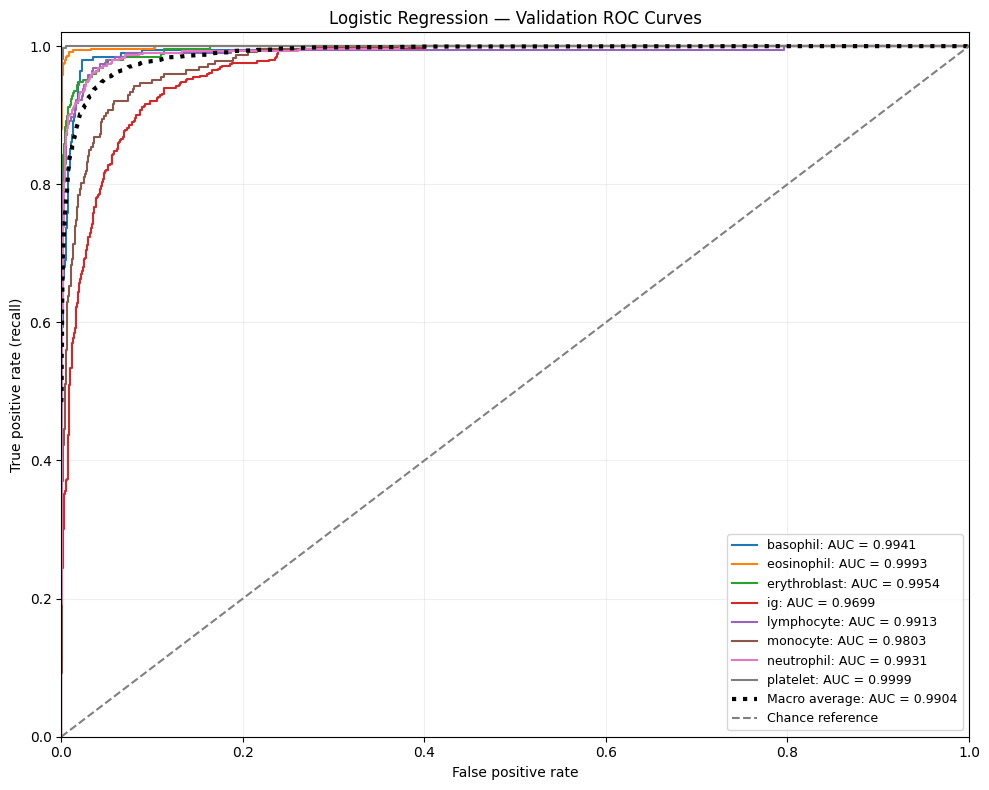

,Category,Validation AUC
0,basophil,0.9941
1,eosinophil,0.9993
2,erythroblast,0.9954
3,ig,0.9699
4,lymphocyte,0.9913
5,monocyte,0.9803
6,neutrophil,0.9931
7,platelet,0.9999


Validation macro AUC: 0.9904


In [20]:
# Plot one-vs-rest ROC curves for Logistic Regression on validation data.

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Convert each label into eight binary indicators.
# Match the column order to the model's probability columns.
classes = logistic_model.classes_

y_validation_binary = label_binarize(
    y_validation,
    classes=classes,
)

# Get the predicted probability for each category.
validation_probabilities = logistic_model.predict_proba(
    X_validation_selected
)

fig, ax = plt.subplots(figsize=(10, 8))

class_auc_records = []
class_curves = []

for index, category in enumerate(classes):
    # Treat this category as positive and all other categories as negative.
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_validation_binary[:, index],
        validation_probabilities[:, index],
    )

    category_auc = auc(false_positive_rate, true_positive_rate)

    class_curves.append((false_positive_rate, true_positive_rate))
    class_auc_records.append({
        "Category": category,
        "Validation AUC": category_auc,
    })

    ax.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=1.5,
        label=f"{category}: AUC = {category_auc:.4f}",
    )

# Interpolate the curves onto shared false-positive-rate coordinates.
# Give each category equal weight in the macro-average curve.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in class_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in class_curves
], axis=0)

# Report the mean of the individual category AUCs.
macro_auc = np.mean([
    record["Validation AUC"] for record in class_auc_records
])

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {macro_auc:.4f}",
)

# Random ranking has an expected AUC of 0.5.
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Logistic Regression — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

# Save the figure and per-category AUC values.
results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    results_dir / "logistic_regression_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

auc_table = pd.DataFrame(class_auc_records)
display(auc_table.round(4))
print(f"Validation macro AUC: {macro_auc:.4f}")

auc_table.to_csv(
    results_dir / "logistic_regression_validation_auc.csv",
    index=False,
)

Training time: 4.0 seconds


,Set,Accuracy,Macro F1
0,Training,0.9688,0.9674
1,Validation,0.9140,0.9051


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808



RBF SVM validation classification report:
              precision    recall  f1-score   support

    basophil      0.916     0.902     0.909       194
  eosinophil      0.990     0.982     0.986       498
erythroblast      0.921     0.895     0.908       248
          ig      0.797     0.840     0.818       463
  lymphocyte      0.896     0.887     0.891       194
    monocyte      0.851     0.758     0.802       227
  neutrophil      0.922     0.953     0.937       532
    platelet      0.992     0.987     0.989       376

    accuracy                          0.914      2732
   macro avg      0.911     0.900     0.905      2732
weighted avg      0.915     0.914     0.914      2732



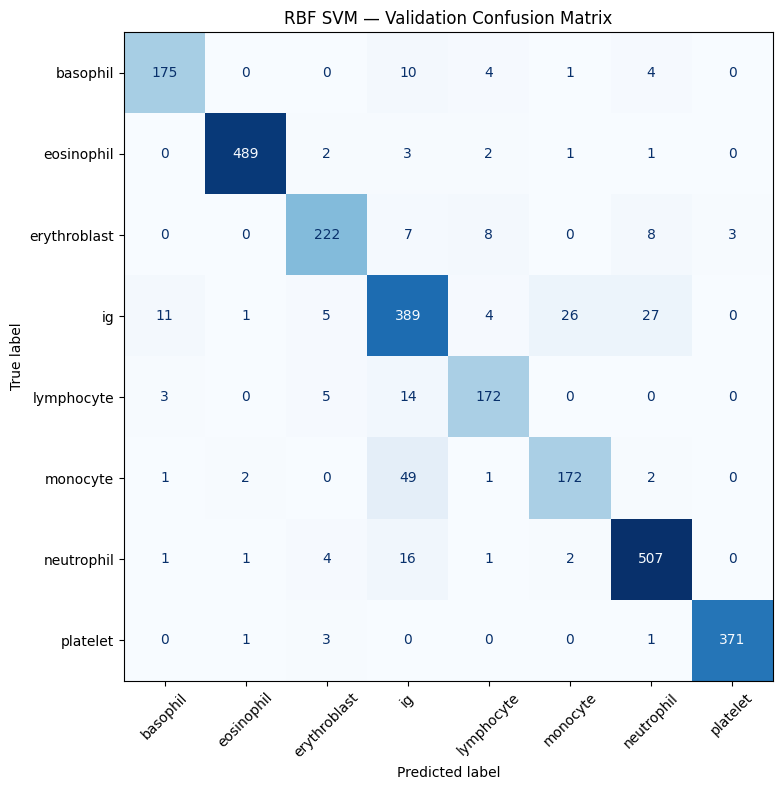

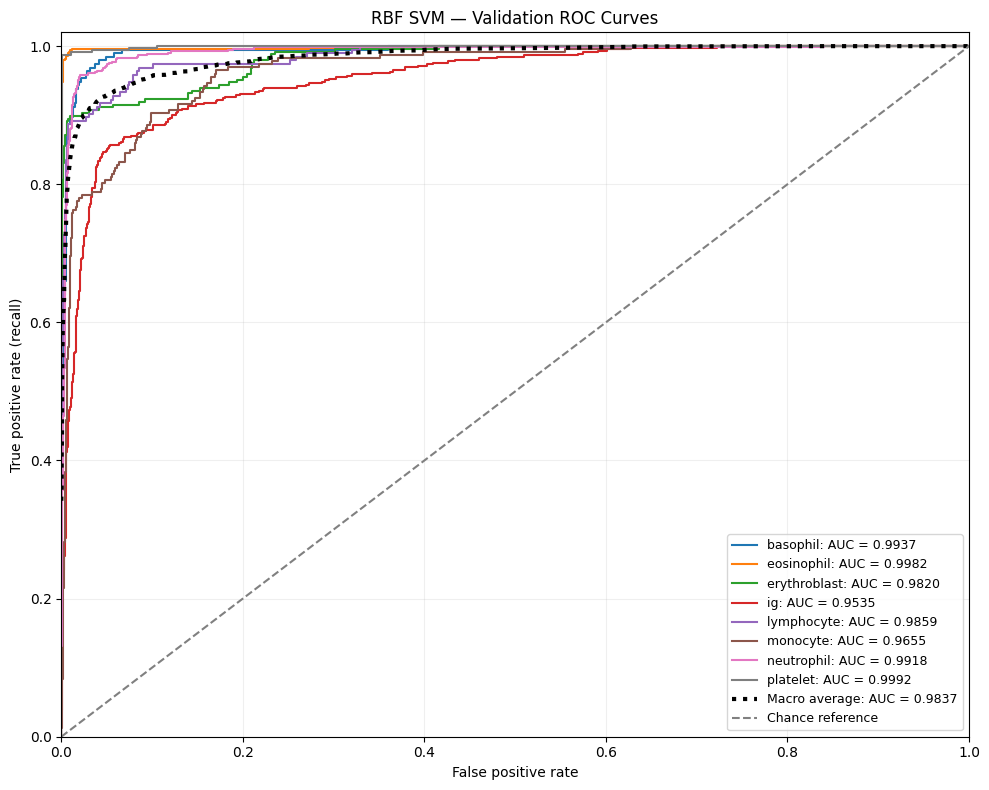

In [22]:
# Train an RBF SVM and compare it with the Logistic Regression baseline.

from sklearn.svm import SVC

# The RBF kernel allows nonlinear decision boundaries.
# C controls the penalty for training errors.
# gamma controls how locally each training example influences the boundary.
# These are fixed baseline settings; tuning comes later.
rbf_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=False,
    decision_function_shape="ovr",
    random_state=SEED,
)

# Train using the same selected and scaled features as Logistic Regression.
start_time = perf_counter()
rbf_model.fit(X_train_selected, y_train)
rbf_training_seconds = perf_counter() - start_time

# Predict categories for training and validation images.
rbf_train_predictions = rbf_model.predict(X_train_selected)
rbf_validation_predictions = rbf_model.predict(X_validation_selected)

# Decision scores measure relative support for each category.
# They are not probabilities, but they can be used to calculate ROC curves.
rbf_validation_scores = rbf_model.decision_function(
    X_validation_selected
)

# Align binary category labels with the model's score columns.
rbf_binary_labels = label_binarize(
    y_validation,
    classes=rbf_model.classes_,
)

# Calculate one-vs-rest AUC separately for each category.
rbf_class_aucs = [
    roc_auc_score(
        rbf_binary_labels[:, index],
        rbf_validation_scores[:, index],
    )
    for index in range(len(rbf_model.classes_))
]

# Compare training and validation scores to check the performance gap.
rbf_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, rbf_train_predictions),
        accuracy_score(y_validation, rbf_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, rbf_train_predictions, average="macro"),
        f1_score(
            y_validation,
            rbf_validation_predictions,
            average="macro",
        ),
    ],
})

print(f"Training time: {rbf_training_seconds:.1f} seconds")
display(rbf_performance.round(4))

# Store the same metrics used for the first baseline.
rbf_result = {
    "Model": "SVM — RBF",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, rbf_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        rbf_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        rbf_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        rbf_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(rbf_class_aucs),
    "Training seconds": rbf_training_seconds,
}

# Compare both models on the same validation set.
baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
])

display(baseline_comparison.round(4))

print("\nRBF SVM validation classification report:")
print(classification_report(
    y_validation,
    rbf_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

# Display correct predictions and category mix-ups.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    rbf_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("RBF SVM — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Plot a ROC curve for each category versus all other categories.
fig, ax = plt.subplots(figsize=(10, 8))
rbf_curves = []

for index, category in enumerate(rbf_model.classes_):
    fpr, tpr, _ = roc_curve(
        rbf_binary_labels[:, index],
        rbf_validation_scores[:, index],
    )

    rbf_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {rbf_class_aucs[index]:.4f}",
    )

# Construct the macro-average curve with equal weight per category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in rbf_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in rbf_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(rbf_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("RBF SVM — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

# Save the ROC figure and model comparison.
results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    results_dir / "rbf_svm_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

# Save predictions and decision scores for later comparisons.
rbf_prediction_table = validation_df[["filepath", "label"]].copy()
rbf_prediction_table["prediction"] = rbf_validation_predictions

for index, category in enumerate(rbf_model.classes_):
    rbf_prediction_table[f"score_{category}"] = (
        rbf_validation_scores[:, index]
    )

rbf_prediction_table.to_csv(
    results_dir / "rbf_svm_validation_predictions.csv",
    index=False,
)

Training polynomial SVM...
Training finished in 2.9 seconds.


,Set,Accuracy,Macro F1
0,Training,0.9962,0.9962
1,Validation,0.9250,0.9181


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412



Polynomial SVM validation classification report:
              precision    recall  f1-score   support

    basophil      0.905     0.928     0.916       194
  eosinophil      0.990     0.984     0.987       498
erythroblast      0.944     0.887     0.915       248
          ig      0.820     0.875     0.846       463
  lymphocyte      0.935     0.892     0.913       194
    monocyte      0.868     0.811     0.838       227
  neutrophil      0.935     0.944     0.939       532
    platelet      0.989     0.992     0.991       376

    accuracy                          0.925      2732
   macro avg      0.923     0.914     0.918      2732
weighted avg      0.926     0.925     0.925      2732



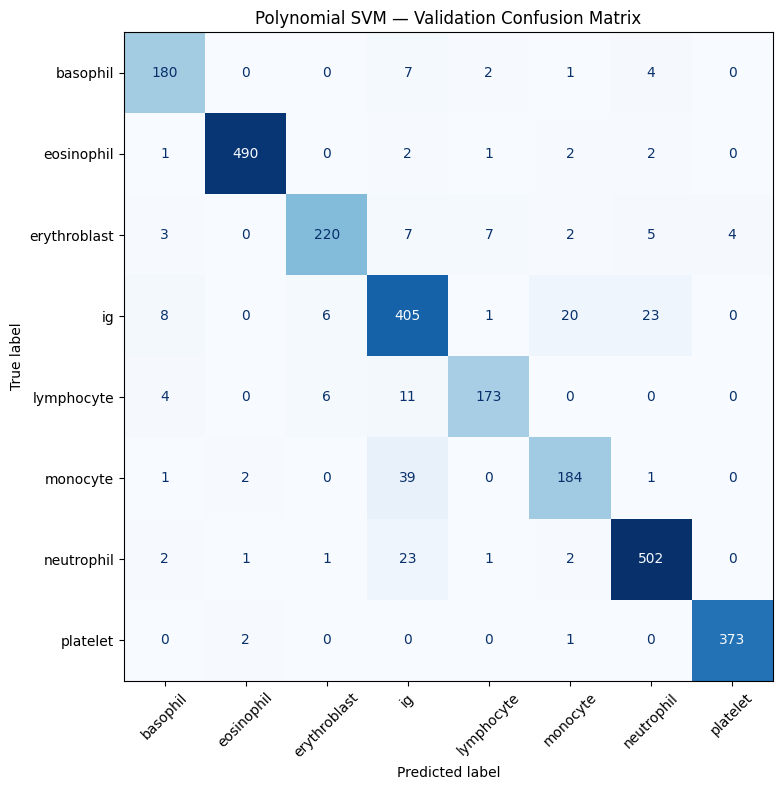

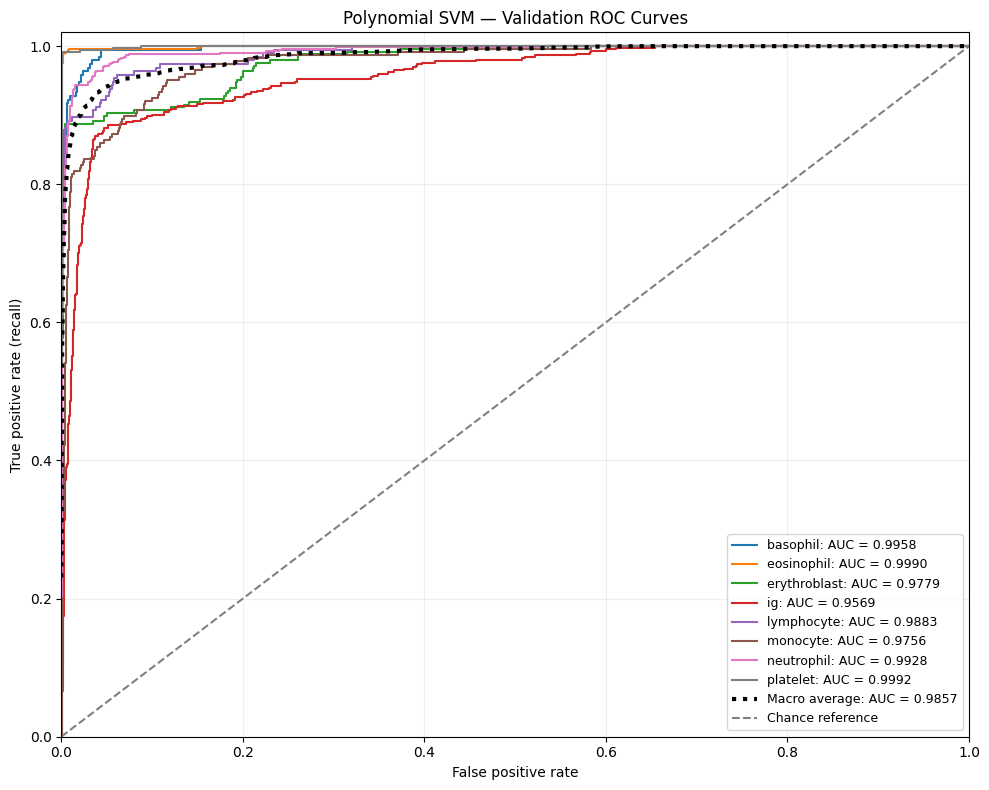

In [23]:
# Train a polynomial SVM and compare it with the previous baselines.

from sklearn.svm import SVC
from time import perf_counter

# A degree-3 polynomial kernel captures nonlinear feature interactions.
# These are initial settings; tuning will happen later using development data.
poly_model = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma="scale",
    coef0=1.0,
    probability=False,
    decision_function_shape="ovr",
    random_state=42,
)

# Train on the same selected features used by the previous models.
print("Training polynomial SVM...", flush=True)

start_time = perf_counter()
poly_model.fit(X_train_selected, y_train)
poly_training_seconds = perf_counter() - start_time

print(f"Training finished in {poly_training_seconds:.1f} seconds.")

# Predict categories for training and validation images.
poly_train_predictions = poly_model.predict(X_train_selected)
poly_validation_predictions = poly_model.predict(X_validation_selected)

# Decision scores are used for ROC curves; they are not probabilities.
poly_validation_scores = poly_model.decision_function(
    X_validation_selected
)

# Match the binary category indicators to the score-column order.
poly_binary_labels = label_binarize(
    y_validation,
    classes=poly_model.classes_,
)

# Calculate one-versus-rest AUC for each category.
poly_class_aucs = [
    roc_auc_score(
        poly_binary_labels[:, index],
        poly_validation_scores[:, index],
    )
    for index in range(len(poly_model.classes_))
]

# Compare training and validation performance.
poly_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, poly_train_predictions),
        accuracy_score(y_validation, poly_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, poly_train_predictions, average="macro"),
        f1_score(
            y_validation,
            poly_validation_predictions,
            average="macro",
        ),
    ],
})

display(poly_performance.round(4))

# Record validation metrics using the same definitions as previous models.
poly_result = {
    "Model": "SVM — Polynomial degree 3",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, poly_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        poly_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        poly_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        poly_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(poly_class_aucs),
    "Training seconds": poly_training_seconds,
}

# Compare all three baselines on the same validation images.
baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
])

display(baseline_comparison.round(4))

print("\nPolynomial SVM validation classification report:")
print(classification_report(
    y_validation,
    poly_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Show correct predictions on the diagonal and mistakes elsewhere.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    poly_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Polynomial SVM — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "polynomial_svm_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# Plot each category against all other categories combined.
fig, ax = plt.subplots(figsize=(10, 8))
poly_curves = []

for index, category in enumerate(poly_model.classes_):
    fpr, tpr, _ = roc_curve(
        poly_binary_labels[:, index],
        poly_validation_scores[:, index],
    )

    poly_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {poly_class_aucs[index]:.4f}",
    )

# Average the category curves on shared horizontal coordinates.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in poly_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in poly_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(poly_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Polynomial SVM — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "polynomial_svm_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# Save the comparison and per-category AUC scores.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": poly_model.classes_,
    "Validation AUC": poly_class_aucs,
}).to_csv(
    results_dir / "polynomial_svm_validation_auc.csv",
    index=False,
)

# Save predictions and scores for later combined comparisons.
poly_prediction_table = validation_df[["filepath", "label"]].copy()
poly_prediction_table["prediction"] = poly_validation_predictions

for index, category in enumerate(poly_model.classes_):
    poly_prediction_table[f"score_{category}"] = (
        poly_validation_scores[:, index]
    )

poly_prediction_table.to_csv(
    results_dir / "polynomial_svm_validation_predictions.csv",
    index=False,
)

Training linear SVM...
Training finished in 6.7 seconds.


,Set,Accuracy,Macro F1
0,Training,0.9432,0.9385
1,Validation,0.9030,0.8954


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816



Linear SVM validation classification report:
              precision    recall  f1-score   support

    basophil      0.850     0.902     0.875       194
  eosinophil      0.982     0.970     0.976       498
erythroblast      0.949     0.903     0.926       248
          ig      0.786     0.786     0.786       463
  lymphocyte      0.915     0.892     0.903       194
    monocyte      0.801     0.762     0.781       227
  neutrophil      0.908     0.944     0.925       532
    platelet      0.989     0.992     0.991       376

    accuracy                          0.903      2732
   macro avg      0.897     0.894     0.895      2732
weighted avg      0.903     0.903     0.903      2732



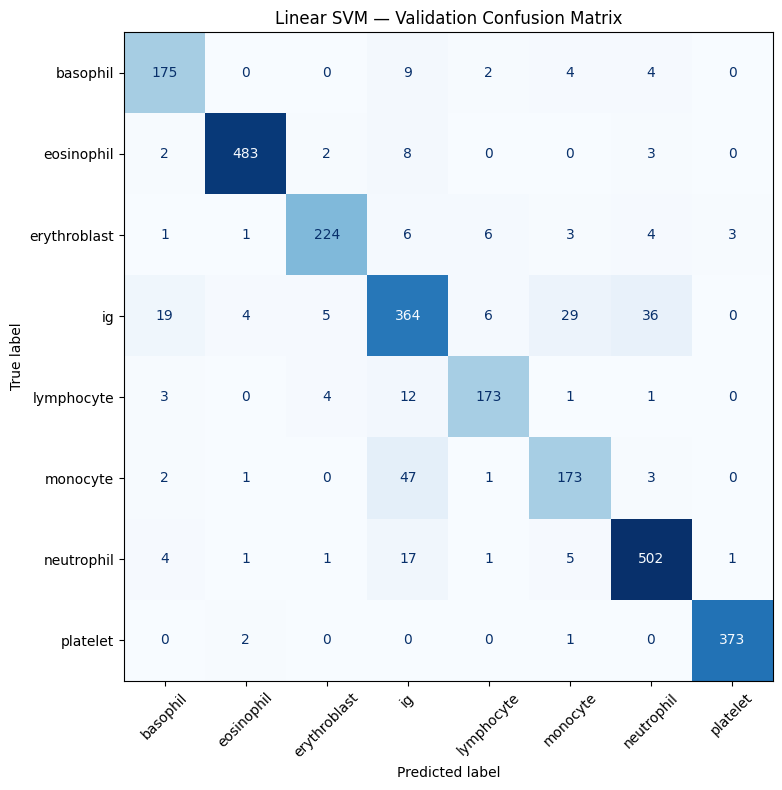

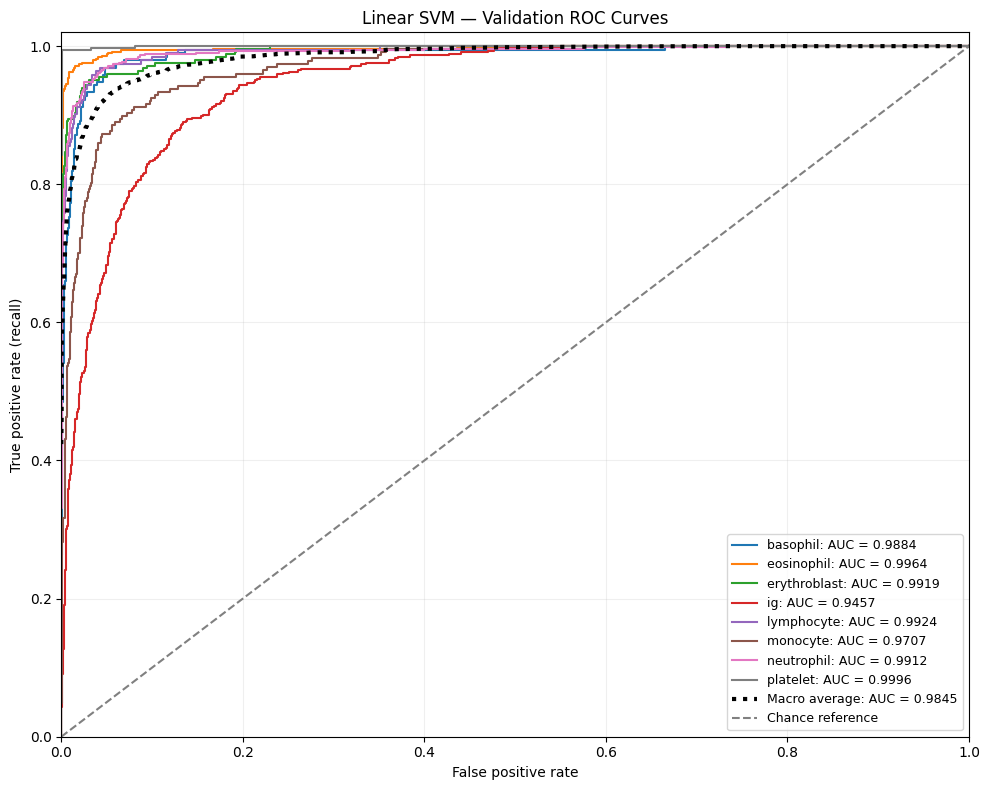

In [24]:
# Train a linear SVM and compare it with the previous baselines.

from sklearn.svm import LinearSVC
from time import perf_counter

# LinearSVC trains a linear classifier for each category versus the rest.
# It uses a different solver from the kernel-based SVC models.
# These are fixed baseline settings; tuning comes later.
linear_model = LinearSVC(
    C=1.0,
    dual=False,
    max_iter=10000,
    random_state=42,
)

print("Training linear SVM...", flush=True)

start_time = perf_counter()
linear_model.fit(X_train_selected, y_train)
linear_training_seconds = perf_counter() - start_time

print(f"Training finished in {linear_training_seconds:.1f} seconds.")

# Predict categories and obtain validation decision scores.
linear_train_predictions = linear_model.predict(X_train_selected)
linear_validation_predictions = linear_model.predict(
    X_validation_selected
)
linear_validation_scores = linear_model.decision_function(
    X_validation_selected
)

# Align the binary category indicators with the score columns.
linear_binary_labels = label_binarize(
    y_validation,
    classes=linear_model.classes_,
)

# Calculate AUC for each category versus all other categories.
# Decision scores measure support for a category, not probability.
linear_class_aucs = [
    roc_auc_score(
        linear_binary_labels[:, index],
        linear_validation_scores[:, index],
    )
    for index in range(len(linear_model.classes_))
]

# Compare training and validation performance.
linear_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, linear_train_predictions),
        accuracy_score(y_validation, linear_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, linear_train_predictions, average="macro"),
        f1_score(
            y_validation,
            linear_validation_predictions,
            average="macro",
        ),
    ],
})

display(linear_performance.round(4))

# Record the same validation metrics as the previous models.
linear_result = {
    "Model": "SVM — Linear",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, linear_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        linear_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        linear_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        linear_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(linear_class_aucs),
    "Training seconds": linear_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
])

display(baseline_comparison.round(4))

print("\nLinear SVM validation classification report:")
print(classification_report(
    y_validation,
    linear_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Display the confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    linear_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Linear SVM — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "linear_svm_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot one ROC curve per category.
fig, ax = plt.subplots(figsize=(10, 8))
linear_curves = []

for index, category in enumerate(linear_model.classes_):
    fpr, tpr, _ = roc_curve(
        linear_binary_labels[:, index],
        linear_validation_scores[:, index],
    )

    linear_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {linear_class_aucs[index]:.4f}",
    )

# Average the curves with equal weight for each category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in linear_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in linear_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(linear_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Linear SVM — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "linear_svm_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics and predictions for later comparisons.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": linear_model.classes_,
    "Validation AUC": linear_class_aucs,
}).to_csv(
    results_dir / "linear_svm_validation_auc.csv",
    index=False,
)

linear_prediction_table = validation_df[["filepath", "label"]].copy()
linear_prediction_table["prediction"] = linear_validation_predictions

for index, category in enumerate(linear_model.classes_):
    linear_prediction_table[f"score_{category}"] = (
        linear_validation_scores[:, index]
    )

linear_prediction_table.to_csv(
    results_dir / "linear_svm_validation_predictions.csv",
    index=False,
)

Training Random Forest...
Training finished in 13.2 seconds.


,Set,Accuracy,Macro F1
0,Training,0.9995,0.9997
1,Validation,0.9081,0.9001


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844



Random Forest validation classification report:
              precision    recall  f1-score   support

    basophil      0.901     0.840     0.869       194
  eosinophil      0.996     0.976     0.986       498
erythroblast      0.969     0.879     0.922       248
          ig      0.743     0.849     0.792       463
  lymphocyte      0.887     0.933     0.910       194
    monocyte      0.914     0.705     0.796       227
  neutrophil      0.912     0.957     0.934       532
    platelet      0.997     0.987     0.992       376

    accuracy                          0.908      2732
   macro avg      0.915     0.891     0.900      2732
weighted avg      0.913     0.908     0.909      2732



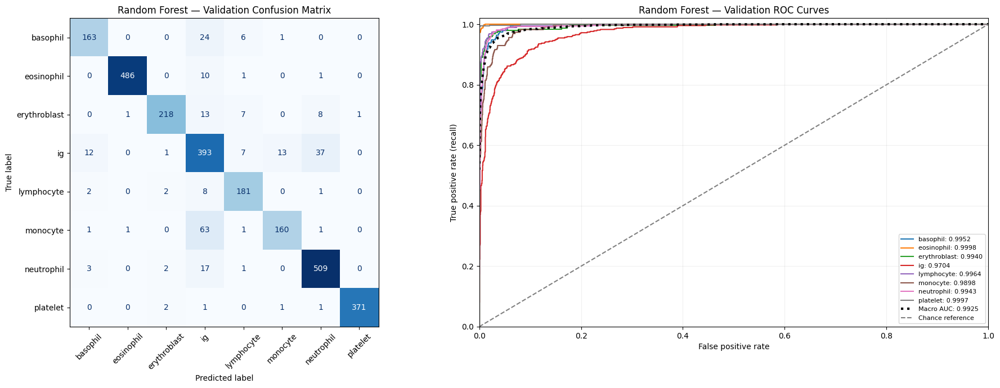

In [25]:
# Train a Random Forest and evaluate it on the same validation set.

from sklearn.ensemble import RandomForestClassifier
from time import perf_counter

# Bootstrap sampling and random feature subsets make the trees different.
# Averaging their predictions can reduce the instability of a single tree.
# These are fixed baseline settings rather than tuned parameters.
forest_model = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    bootstrap=True,
    n_jobs=-1,
    random_state=42,
)

print("Training Random Forest...", flush=True)

start_time = perf_counter()
forest_model.fit(X_train_selected, y_train)
forest_training_seconds = perf_counter() - start_time

print(f"Training finished in {forest_training_seconds:.1f} seconds.")

# Predict categories for training and validation images.
forest_train_predictions = forest_model.predict(X_train_selected)
forest_validation_predictions = forest_model.predict(
    X_validation_selected
)

# Probabilities are used to calculate one-versus-rest ROC curves.
forest_validation_probabilities = forest_model.predict_proba(
    X_validation_selected
)

forest_binary_labels = label_binarize(
    y_validation,
    classes=forest_model.classes_,
)

forest_class_aucs = [
    roc_auc_score(
        forest_binary_labels[:, index],
        forest_validation_probabilities[:, index],
    )
    for index in range(len(forest_model.classes_))
]

# Compare training and validation performance.
forest_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, forest_train_predictions),
        accuracy_score(y_validation, forest_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, forest_train_predictions, average="macro"),
        f1_score(
            y_validation,
            forest_validation_predictions,
            average="macro",
        ),
    ],
})

display(forest_performance.round(4))

# Record the same metrics used for the other models.
forest_result = {
    "Model": "Random Forest",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, forest_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        forest_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        forest_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        forest_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(forest_class_aucs),
    "Training seconds": forest_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nRandom Forest validation classification report:")
print(classification_report(
    y_validation,
    forest_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

# Display the confusion matrix and ROC curves side by side.
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    forest_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=axes[0],
)

axes[0].set_title("Random Forest — Validation Confusion Matrix")

forest_curves = []

for index, category in enumerate(forest_model.classes_):
    fpr, tpr, _ = roc_curve(
        forest_binary_labels[:, index],
        forest_validation_probabilities[:, index],
    )

    forest_curves.append((fpr, tpr))

    axes[1].plot(
        fpr,
        tpr,
        label=f"{category}: {forest_class_aucs[index]:.4f}",
    )

# Average the category curves with equal weight per category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in forest_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in forest_curves
], axis=0)

axes[1].plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro AUC: {np.mean(forest_class_aucs):.4f}",
)

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

axes[1].set(
    title="Random Forest — Validation ROC Curves",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(alpha=0.2)

plt.tight_layout()

# Save the plots, comparison table, and predictions.
results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    results_dir / "random_forest_validation_plots.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

forest_prediction_table = validation_df[["filepath", "label"]].copy()
forest_prediction_table["prediction"] = forest_validation_predictions

for index, category in enumerate(forest_model.classes_):
    forest_prediction_table[f"probability_{category}"] = (
        forest_validation_probabilities[:, index]
    )

forest_prediction_table.to_csv(
    results_dir / "random_forest_validation_predictions.csv",
    index=False,
)

Training XGBoost...
Training finished in 19.7 seconds.


,Set,Accuracy,Macro F1
0,Training,1.000,1.0000
1,Validation,0.948,0.9445


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844



XGBoost validation classification report:
              precision    recall  f1-score   support

    basophil      0.927     0.912     0.919       194
  eosinophil      0.994     0.988     0.991       498
erythroblast      0.987     0.944     0.965       248
          ig      0.857     0.905     0.880       463
  lymphocyte      0.969     0.959     0.964       194
    monocyte      0.923     0.846     0.883       227
  neutrophil      0.947     0.972     0.959       532
    platelet      0.997     0.992     0.995       376

    accuracy                          0.948      2732
   macro avg      0.950     0.940     0.944      2732
weighted avg      0.949     0.948     0.948      2732



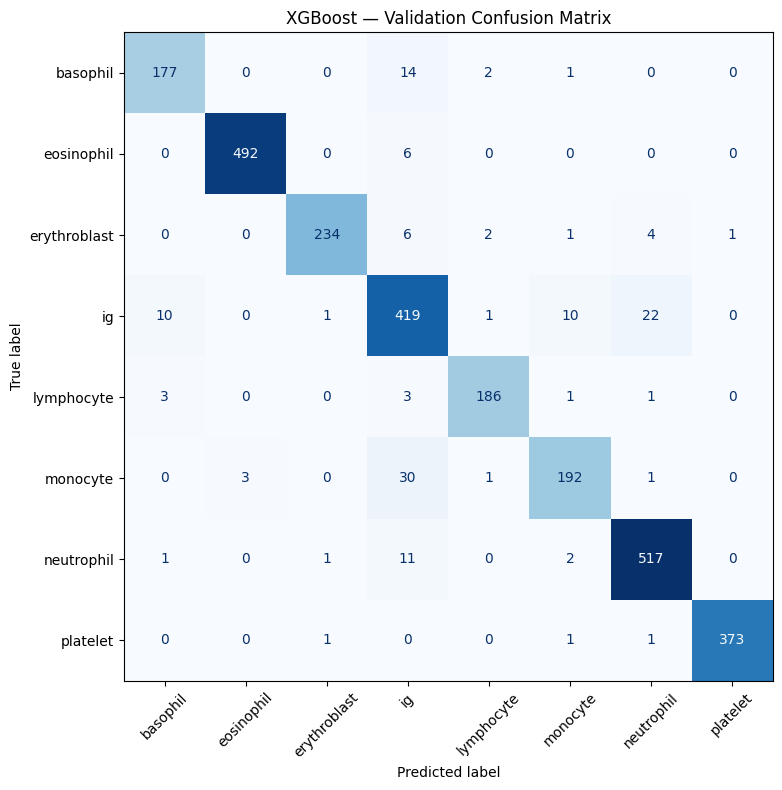

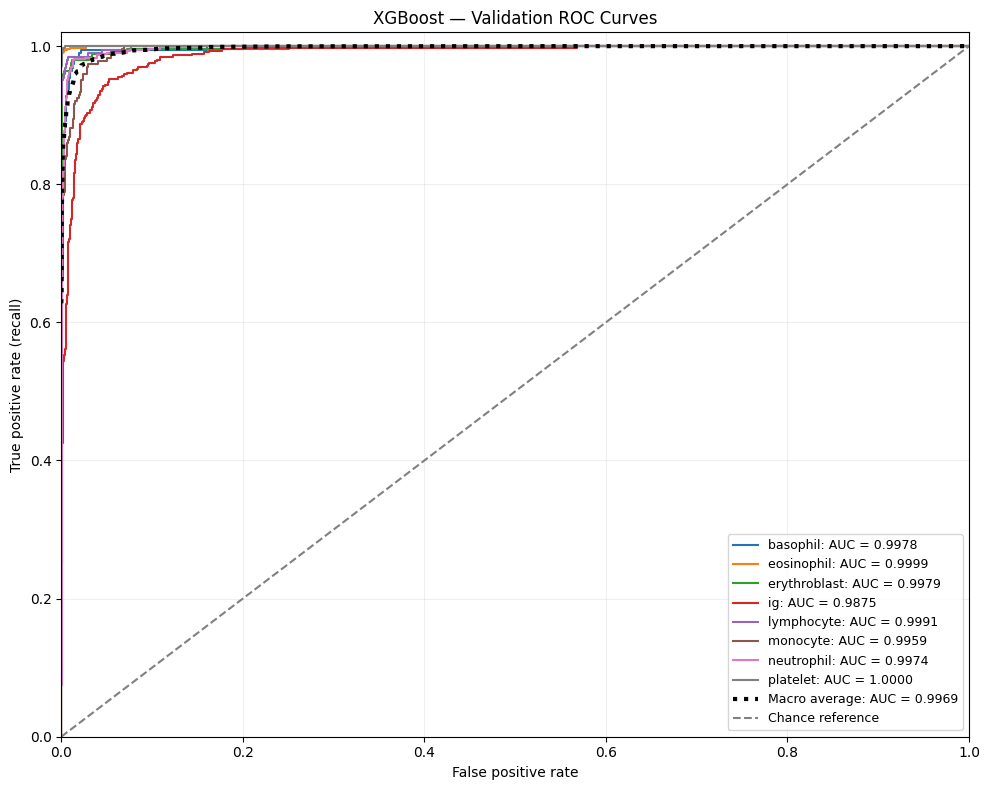

In [26]:
# Train an XGBoost baseline and compare it with the previous models.

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from time import perf_counter

# XGBoost requires numerical category labels.
# Learn the category-to-number mapping from training labels only.
xgb_label_encoder = LabelEncoder()
y_train_encoded = xgb_label_encoder.fit_transform(y_train)

# Use fixed baseline settings without validation-based early stopping.
# Each boosting round adds trees to improve the current predictions.
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(xgb_label_encoder.classes_),
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    eval_metric="mlogloss",
    n_jobs=2,
    random_state=42,
)

print("Training XGBoost...", flush=True)

start_time = perf_counter()
xgb_model.fit(X_train_selected, y_train_encoded)
xgb_training_seconds = perf_counter() - start_time

print(f"Training finished in {xgb_training_seconds:.1f} seconds.")

# Convert predicted numerical labels back to cell-category names.
xgb_train_predictions = xgb_label_encoder.inverse_transform(
    xgb_model.predict(X_train_selected).astype(int)
)

xgb_validation_predictions = xgb_label_encoder.inverse_transform(
    xgb_model.predict(X_validation_selected).astype(int)
)

# Probability columns follow the encoded category order.
xgb_validation_probabilities = xgb_model.predict_proba(
    X_validation_selected
)

xgb_classes = xgb_label_encoder.classes_

xgb_binary_labels = label_binarize(
    y_validation,
    classes=xgb_classes,
)

# Calculate one-versus-rest AUC for each category.
xgb_class_aucs = [
    roc_auc_score(
        xgb_binary_labels[:, index],
        xgb_validation_probabilities[:, index],
    )
    for index in range(len(xgb_classes))
]

# Compare training and validation scores to inspect overfitting.
xgb_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, xgb_train_predictions),
        accuracy_score(y_validation, xgb_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, xgb_train_predictions, average="macro"),
        f1_score(
            y_validation,
            xgb_validation_predictions,
            average="macro",
        ),
    ],
})

display(xgb_performance.round(4))

# Store the same validation metrics used for the previous models.
xgb_result = {
    "Model": "XGBoost",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, xgb_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        xgb_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        xgb_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        xgb_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(xgb_class_aucs),
    "Training seconds": xgb_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nXGBoost validation classification report:")
print(classification_report(
    y_validation,
    xgb_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Show which categories are confused with each other.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    xgb_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("XGBoost — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "xgboost_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot ROC curves for each category versus all other categories.
fig, ax = plt.subplots(figsize=(10, 8))
xgb_curves = []

for index, category in enumerate(xgb_classes):
    fpr, tpr, _ = roc_curve(
        xgb_binary_labels[:, index],
        xgb_validation_probabilities[:, index],
    )

    xgb_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {xgb_class_aucs[index]:.4f}",
    )

# Construct a macro-average curve with equal weight for each category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in xgb_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in xgb_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(xgb_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("XGBoost — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "xgboost_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save the comparison table and category-level AUC values.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": xgb_classes,
    "Validation AUC": xgb_class_aucs,
}).to_csv(
    results_dir / "xgboost_validation_auc.csv",
    index=False,
)

# Save predictions and probabilities for later combined comparisons.
xgb_prediction_table = validation_df[["filepath", "label"]].copy()
xgb_prediction_table["prediction"] = xgb_validation_predictions

for index, category in enumerate(xgb_classes):
    xgb_prediction_table[f"probability_{category}"] = (
        xgb_validation_probabilities[:, index]
    )

xgb_prediction_table.to_csv(
    results_dir / "xgboost_validation_predictions.csv",
    index=False,
)

Fitting KNN...
Calculating training predictions...
Calculating validation predictions...
Fitting time: 0.01 seconds
Validation prediction time: 0.29 seconds


,Set,Accuracy,Macro F1
0,Training,0.8298,0.8179
1,Validation,0.7423,0.7192


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
6,KNN — 5 neighbors,300,0.7423,0.7603,0.7088,0.7192,0.9313,0.0108



KNN validation classification report:
              precision    recall  f1-score   support

    basophil      0.656     0.727     0.689       194
  eosinophil      0.829     0.855     0.842       498
erythroblast      0.884     0.524     0.658       248
          ig      0.513     0.797     0.624       463
  lymphocyte      0.747     0.701     0.723       194
    monocyte      0.650     0.392     0.489       227
  neutrophil      0.874     0.690     0.771       532
    platelet      0.930     0.984     0.956       376

    accuracy                          0.742      2732
   macro avg      0.760     0.709     0.719      2732
weighted avg      0.770     0.742     0.742      2732



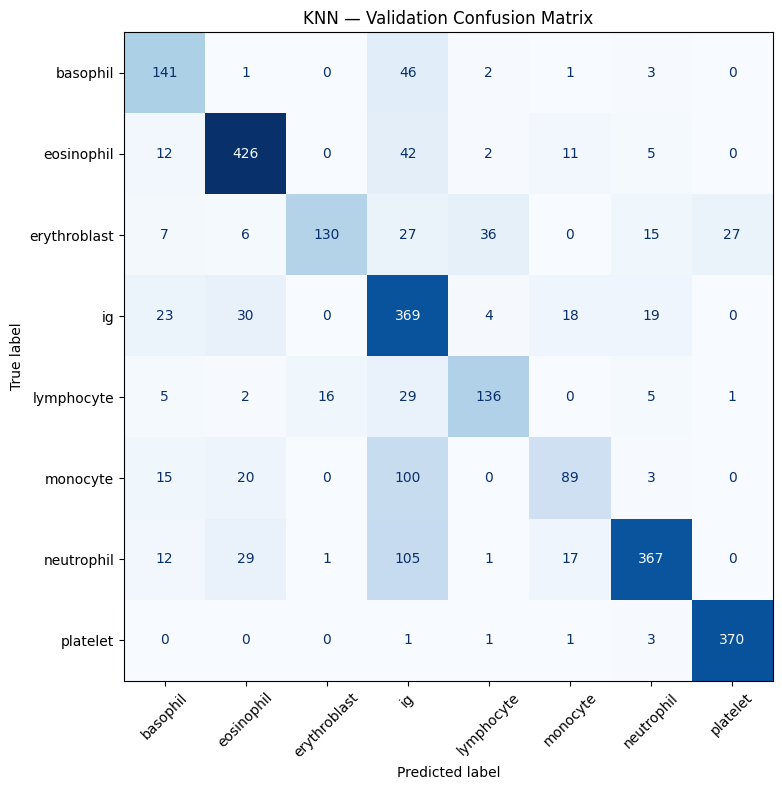

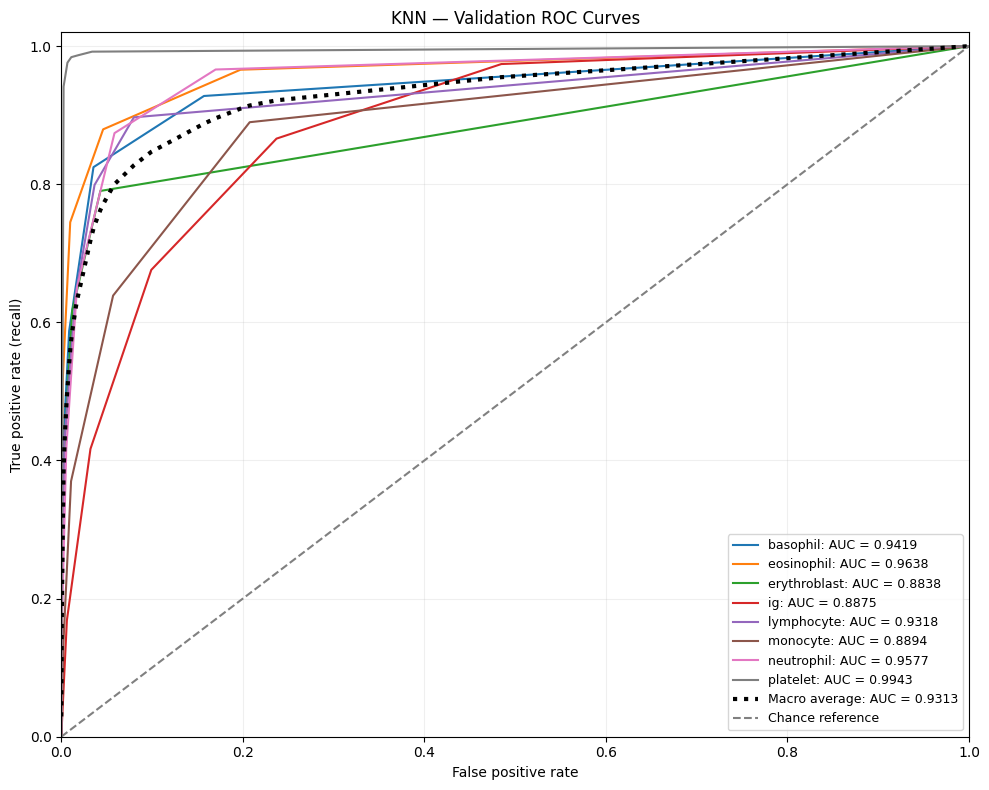

In [27]:
# Train a KNN baseline and compare it with the previous models.

from sklearn.neighbors import KNeighborsClassifier
from time import perf_counter

# Use five neighbors and give each neighbor an equal vote.
# Euclidean distance measures closeness between scaled feature vectors.
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1,
)

print("Fitting KNN...", flush=True)

start_time = perf_counter()
knn_model.fit(X_train_selected, y_train)
knn_training_seconds = perf_counter() - start_time

# Training predictions include each image among its own nearest neighbors.
# Training scores can therefore be optimistic and are only descriptive.
print("Calculating training predictions...", flush=True)
knn_train_predictions = knn_model.predict(X_train_selected)

# Calculate validation probabilities from neighbor vote proportions.
print("Calculating validation predictions...", flush=True)

start_time = perf_counter()
knn_validation_probabilities = knn_model.predict_proba(
    X_validation_selected
)
knn_prediction_seconds = perf_counter() - start_time

# Choose the category with the largest vote proportion.
knn_validation_predictions = knn_model.classes_[
    np.argmax(knn_validation_probabilities, axis=1)
]

knn_binary_labels = label_binarize(
    y_validation,
    classes=knn_model.classes_,
)

# Calculate one-versus-rest AUC for each category.
knn_class_aucs = [
    roc_auc_score(
        knn_binary_labels[:, index],
        knn_validation_probabilities[:, index],
    )
    for index in range(len(knn_model.classes_))
]

print(f"Fitting time: {knn_training_seconds:.2f} seconds")
print(f"Validation prediction time: {knn_prediction_seconds:.2f} seconds")

knn_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, knn_train_predictions),
        accuracy_score(y_validation, knn_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, knn_train_predictions, average="macro"),
        f1_score(
            y_validation,
            knn_validation_predictions,
            average="macro",
        ),
    ],
})

display(knn_performance.round(4))

# Record the same metrics used for the other baselines.
knn_result = {
    "Model": "KNN — 5 neighbors",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, knn_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        knn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        knn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        knn_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(knn_class_aucs),
    "Training seconds": knn_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
    knn_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nKNN validation classification report:")
print(classification_report(
    y_validation,
    knn_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Display correct predictions and category mix-ups.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    knn_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("KNN — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "knn_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot ROC curves using neighbor vote proportions.
fig, ax = plt.subplots(figsize=(10, 8))
knn_curves = []

for index, category in enumerate(knn_model.classes_):
    fpr, tpr, _ = roc_curve(
        knn_binary_labels[:, index],
        knn_validation_probabilities[:, index],
    )

    knn_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {knn_class_aucs[index]:.4f}",
    )

shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in knn_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in knn_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(knn_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("KNN — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "knn_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics and predictions for later comparisons.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": knn_model.classes_,
    "Validation AUC": knn_class_aucs,
}).to_csv(
    results_dir / "knn_validation_auc.csv",
    index=False,
)

knn_prediction_table = validation_df[["filepath", "label"]].copy()
knn_prediction_table["prediction"] = knn_validation_predictions

for index, category in enumerate(knn_model.classes_):
    knn_prediction_table[f"probability_{category}"] = (
        knn_validation_probabilities[:, index]
    )

knn_prediction_table.to_csv(
    results_dir / "knn_validation_predictions.csv",
    index=False,
)

Training Decision Tree...
Training time: 6.21 seconds
Tree depth: 36
Number of leaves: 600


,Set,Accuracy,Macro F1
0,Training,0.9778,0.9746
1,Validation,0.8499,0.8281


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
7,Decision Tree,300,0.8499,0.8300,0.8274,0.8281,0.9112,6.2139
6,KNN — 5 neighbors,300,0.7423,0.7603,0.7088,0.7192,0.9313,0.0108



Decision Tree validation classification report:
              precision    recall  f1-score   support

    basophil      0.700     0.747     0.723       194
  eosinophil      0.949     0.962     0.955       498
erythroblast      0.839     0.859     0.849       248
          ig      0.719     0.728     0.723       463
  lymphocyte      0.826     0.809     0.818       194
    monocyte      0.730     0.630     0.676       227
  neutrophil      0.891     0.895     0.893       532
    platelet      0.987     0.989     0.988       376

    accuracy                          0.850      2732
   macro avg      0.830     0.827     0.828      2732
weighted avg      0.849     0.850     0.849      2732



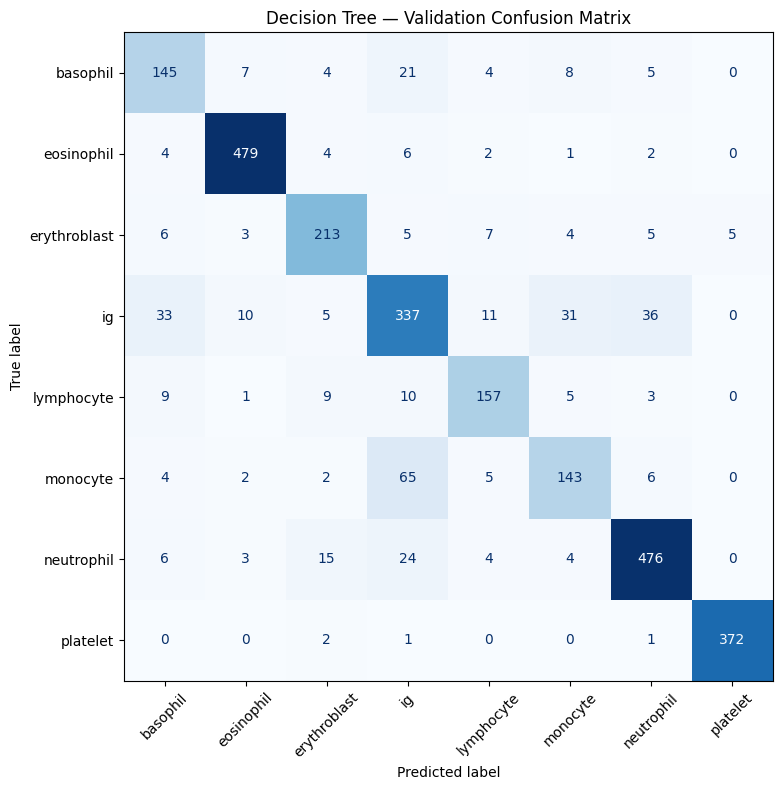

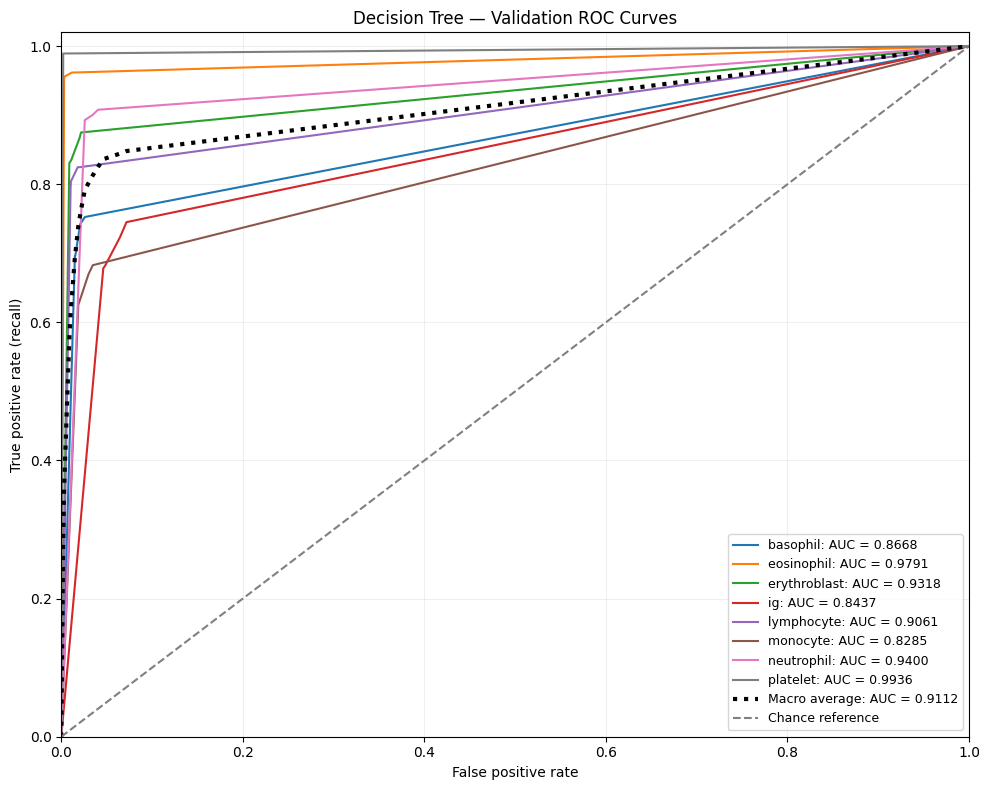

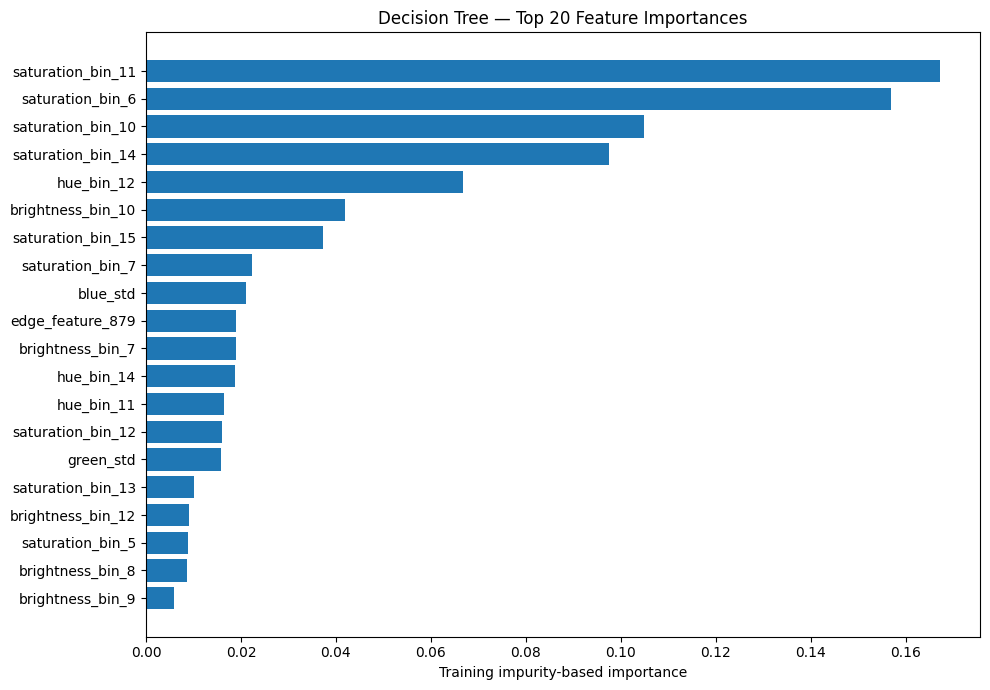

In [28]:
# Train a Decision Tree and compare it with the previous baselines.

from sklearn.tree import DecisionTreeClassifier
from time import perf_counter

# Require at least two training examples per leaf.
# Leave depth unrestricted for this baseline; tuning comes later.
tree_model = DecisionTreeClassifier(
    min_samples_leaf=2,
    random_state=42,
)

print("Training Decision Tree...", flush=True)

start_time = perf_counter()
tree_model.fit(X_train_selected, y_train)
tree_training_seconds = perf_counter() - start_time

# Predict categories and validation probabilities.
tree_train_predictions = tree_model.predict(X_train_selected)
tree_validation_predictions = tree_model.predict(
    X_validation_selected
)
tree_validation_probabilities = tree_model.predict_proba(
    X_validation_selected
)

# Match category indicators to the probability columns.
tree_binary_labels = label_binarize(
    y_validation,
    classes=tree_model.classes_,
)

tree_class_aucs = [
    roc_auc_score(
        tree_binary_labels[:, index],
        tree_validation_probabilities[:, index],
    )
    for index in range(len(tree_model.classes_))
]

print(f"Training time: {tree_training_seconds:.2f} seconds")
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())

# Compare training and validation performance.
tree_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, tree_train_predictions),
        accuracy_score(y_validation, tree_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, tree_train_predictions, average="macro"),
        f1_score(
            y_validation,
            tree_validation_predictions,
            average="macro",
        ),
    ],
})

display(tree_performance.round(4))

# Record the same metrics used for the other models.
tree_result = {
    "Model": "Decision Tree",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, tree_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        tree_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        tree_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        tree_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(tree_class_aucs),
    "Training seconds": tree_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
    knn_result,
    tree_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nDecision Tree validation classification report:")
print(classification_report(
    y_validation,
    tree_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Plot the confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    tree_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Decision Tree — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "decision_tree_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot each category against all other categories.
fig, ax = plt.subplots(figsize=(10, 8))
tree_curves = []

for index, category in enumerate(tree_model.classes_):
    fpr, tpr, _ = roc_curve(
        tree_binary_labels[:, index],
        tree_validation_probabilities[:, index],
    )

    tree_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {tree_class_aucs[index]:.4f}",
    )

# Average the curves with equal weight for each category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in tree_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in tree_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(tree_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Decision Tree — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "decision_tree_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Rank features by their contribution to reducing impurity during training.
# These are training-based importance scores, not causal explanations.
tree_importance = pd.DataFrame({
    "Feature": selected_feature_names,
    "Importance": tree_model.feature_importances_,
}).sort_values("Importance", ascending=False)

top_importance = tree_importance.head(20).sort_values("Importance")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_importance["Feature"], top_importance["Importance"])
ax.set_xlabel("Training impurity-based importance")
ax.set_title("Decision Tree — Top 20 Feature Importances")
plt.tight_layout()

fig.savefig(
    results_dir / "decision_tree_feature_importance.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics, feature importance, and validation predictions.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

tree_importance.to_csv(
    results_dir / "decision_tree_feature_importance.csv",
    index=False,
)

pd.DataFrame({
    "Category": tree_model.classes_,
    "Validation AUC": tree_class_aucs,
}).to_csv(
    results_dir / "decision_tree_validation_auc.csv",
    index=False,
)

tree_prediction_table = validation_df[["filepath", "label"]].copy()
tree_prediction_table["prediction"] = tree_validation_predictions

for index, category in enumerate(tree_model.classes_):
    tree_prediction_table[f"probability_{category}"] = (
        tree_validation_probabilities[:, index]
    )

tree_prediction_table.to_csv(
    results_dir / "decision_tree_validation_predictions.csv",
    index=False,
)

Training bagging classifier...
Training finished in 192.1 seconds.


,Set,Accuracy,Macro F1
0,Training,0.9973,0.9974
1,Validation,0.9206,0.9111


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
7,Decision Tree,300,0.8499,0.8300,0.8274,0.8281,0.9112,6.2139
6,KNN — 5 neighbors,300,0.7423,0.7603,0.7088,0.7192,0.9313,0.0108



Bagging validation classification report:
              precision    recall  f1-score   support

    basophil      0.844     0.866     0.855       194
  eosinophil      0.992     0.982     0.987       498
erythroblast      0.943     0.927     0.935       248
          ig      0.807     0.840     0.823       463
  lymphocyte      0.903     0.912     0.908       194
    monocyte      0.904     0.784     0.840       227
  neutrophil      0.934     0.964     0.949       532
    platelet      0.997     0.987     0.992       376

    accuracy                          0.921      2732
   macro avg      0.916     0.908     0.911      2732
weighted avg      0.922     0.921     0.921      2732



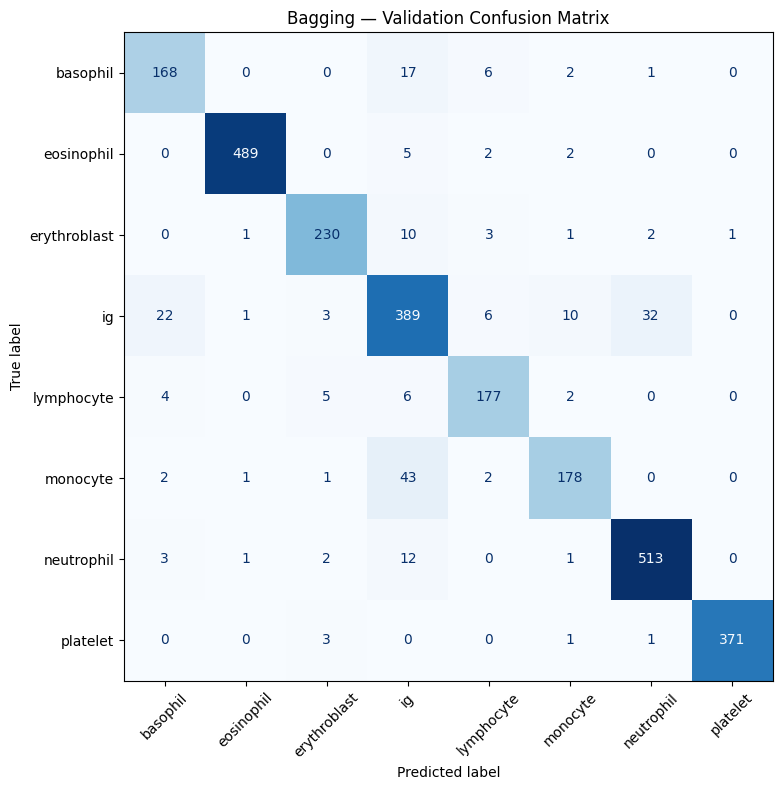

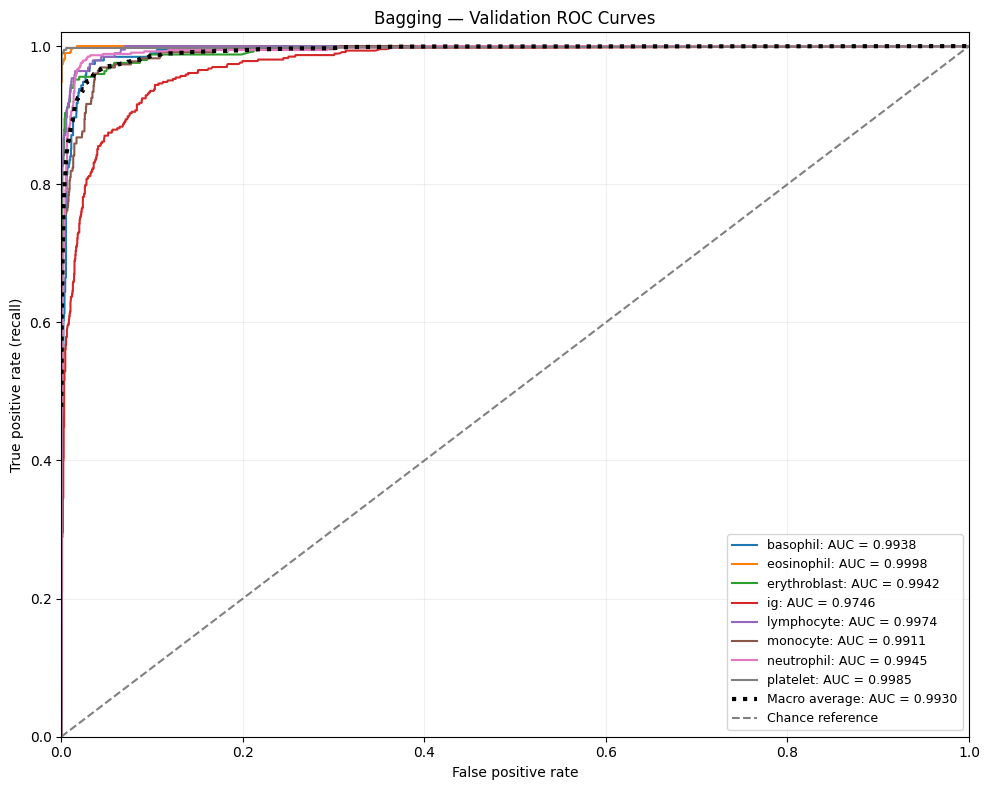

In [29]:
# Train a bagging ensemble of decision trees and evaluate validation performance.

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from time import perf_counter

# Each tree uses the same settings as the single-tree baseline.
# Bootstrap samples contain repeated training images and omit some others.
# All selected features are available to each tree.
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        min_samples_leaf=2,
        random_state=42,
    ),
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    bootstrap_features=False,
    n_jobs=2,
    random_state=42,
)

print("Training bagging classifier...", flush=True)

start_time = perf_counter()
bagging_model.fit(X_train_selected, y_train)
bagging_training_seconds = perf_counter() - start_time

print(f"Training finished in {bagging_training_seconds:.1f} seconds.")

# Predict categories and calculate validation probabilities.
bagging_train_predictions = bagging_model.predict(X_train_selected)
bagging_validation_probabilities = bagging_model.predict_proba(
    X_validation_selected
)

bagging_validation_predictions = bagging_model.classes_[
    np.argmax(bagging_validation_probabilities, axis=1)
]

# Align category indicators with the probability columns.
bagging_binary_labels = label_binarize(
    y_validation,
    classes=bagging_model.classes_,
)

bagging_class_aucs = [
    roc_auc_score(
        bagging_binary_labels[:, index],
        bagging_validation_probabilities[:, index],
    )
    for index in range(len(bagging_model.classes_))
]

# Compare training and validation scores.
bagging_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, bagging_train_predictions),
        accuracy_score(y_validation, bagging_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, bagging_train_predictions, average="macro"),
        f1_score(
            y_validation,
            bagging_validation_predictions,
            average="macro",
        ),
    ],
})

display(bagging_performance.round(4))

# Store the same metrics used for the previous baselines.
bagging_result = {
    "Model": "Bagging — Decision Trees",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, bagging_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        bagging_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        bagging_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        bagging_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(bagging_class_aucs),
    "Training seconds": bagging_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
    knn_result,
    tree_result,
    bagging_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nBagging validation classification report:")
print(classification_report(
    y_validation,
    bagging_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Plot correct predictions and category mix-ups.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    bagging_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Bagging — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "bagging_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot ROC curves for each category versus the remaining categories.
fig, ax = plt.subplots(figsize=(10, 8))
bagging_curves = []

for index, category in enumerate(bagging_model.classes_):
    fpr, tpr, _ = roc_curve(
        bagging_binary_labels[:, index],
        bagging_validation_probabilities[:, index],
    )

    bagging_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {bagging_class_aucs[index]:.4f}",
    )

# Construct an equally weighted average of the category curves.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in bagging_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in bagging_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(bagging_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Bagging — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "bagging_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save the comparison, category AUCs, and predictions.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": bagging_model.classes_,
    "Validation AUC": bagging_class_aucs,
}).to_csv(
    results_dir / "bagging_validation_auc.csv",
    index=False,
)

bagging_prediction_table = validation_df[["filepath", "label"]].copy()
bagging_prediction_table["prediction"] = bagging_validation_predictions

for index, category in enumerate(bagging_model.classes_):
    bagging_prediction_table[f"probability_{category}"] = (
        bagging_validation_probabilities[:, index]
    )

bagging_prediction_table.to_csv(
    results_dir / "bagging_validation_predictions.csv",
    index=False,
)

Training Extra Trees...
Training finished in 3.4 seconds.


,Set,Accuracy,Macro F1
0,Training,1.0000,1.0000
1,Validation,0.8902,0.8764


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
9,Extra Trees,300,0.8902,0.9012,0.8612,0.8764,0.9892,3.4418
7,Decision Tree,300,0.8499,0.8300,0.8274,0.8281,0.9112,6.2139
6,KNN — 5 neighbors,300,0.7423,0.7603,0.7088,0.7192,0.9313,0.0108



Extra Trees validation classification report:
              precision    recall  f1-score   support

    basophil      0.920     0.768     0.837       194
  eosinophil      0.994     0.974     0.984       498
erythroblast      0.967     0.835     0.896       248
          ig      0.711     0.836     0.769       463
  lymphocyte      0.867     0.876     0.872       194
    monocyte      0.879     0.639     0.740       227
  neutrophil      0.879     0.970     0.922       532
    platelet      0.992     0.992     0.992       376

    accuracy                          0.890      2732
   macro avg      0.901     0.861     0.876      2732
weighted avg      0.897     0.890     0.890      2732



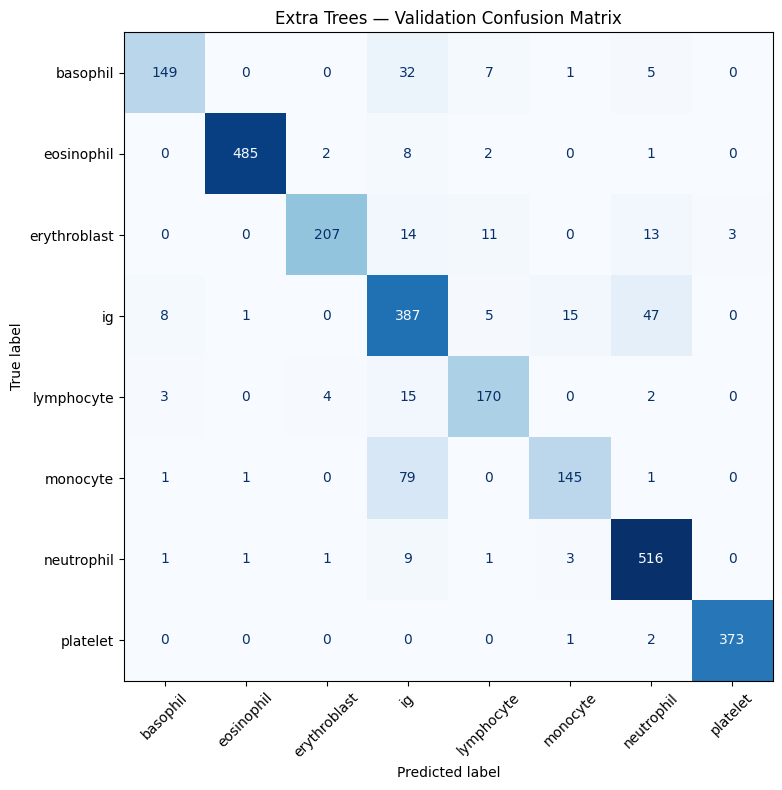

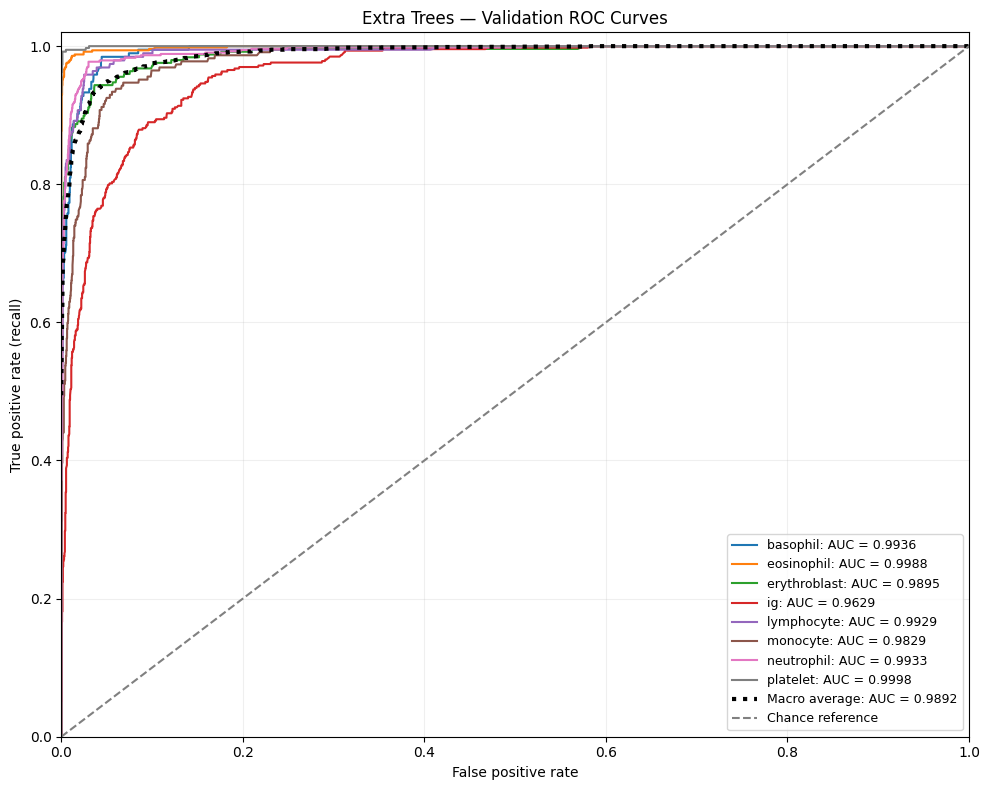

In [30]:
# Train Extra Trees and compare it with the previous baselines.

from sklearn.ensemble import ExtraTreesClassifier
from time import perf_counter

# Random feature subsets and randomized thresholds produce diverse trees.
# Bootstrap is disabled, so each tree receives the full training set.
extra_model = ExtraTreesClassifier(
    n_estimators=200,
    max_features="sqrt",
    min_samples_leaf=2,
    bootstrap=False,
    n_jobs=2,
    random_state=42,
)

print("Training Extra Trees...", flush=True)

start_time = perf_counter()
extra_model.fit(X_train_selected, y_train)
extra_training_seconds = perf_counter() - start_time

print(f"Training finished in {extra_training_seconds:.1f} seconds.")

# Predict categories and validation probabilities.
extra_train_predictions = extra_model.predict(X_train_selected)
extra_validation_probabilities = extra_model.predict_proba(
    X_validation_selected
)
extra_validation_predictions = extra_model.classes_[
    np.argmax(extra_validation_probabilities, axis=1)
]

# Align category indicators with the probability columns.
extra_binary_labels = label_binarize(
    y_validation,
    classes=extra_model.classes_,
)

extra_class_aucs = [
    roc_auc_score(
        extra_binary_labels[:, index],
        extra_validation_probabilities[:, index],
    )
    for index in range(len(extra_model.classes_))
]

# Compare training and validation performance.
extra_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, extra_train_predictions),
        accuracy_score(y_validation, extra_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, extra_train_predictions, average="macro"),
        f1_score(
            y_validation,
            extra_validation_predictions,
            average="macro",
        ),
    ],
})

display(extra_performance.round(4))

# Record the same metrics used for the previous baselines.
extra_result = {
    "Model": "Extra Trees",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, extra_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        extra_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        extra_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        extra_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(extra_class_aucs),
    "Training seconds": extra_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
    knn_result,
    tree_result,
    bagging_result,
    extra_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nExtra Trees validation classification report:")
print(classification_report(
    y_validation,
    extra_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Display category-level prediction errors.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    extra_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("Extra Trees — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "extra_trees_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot each category against all remaining categories.
fig, ax = plt.subplots(figsize=(10, 8))
extra_curves = []

for index, category in enumerate(extra_model.classes_):
    fpr, tpr, _ = roc_curve(
        extra_binary_labels[:, index],
        extra_validation_probabilities[:, index],
    )

    extra_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {extra_class_aucs[index]:.4f}",
    )

# Average the category curves with equal weight per category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in extra_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in extra_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(extra_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("Extra Trees — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "extra_trees_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics and predictions for later comparisons.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": extra_model.classes_,
    "Validation AUC": extra_class_aucs,
}).to_csv(
    results_dir / "extra_trees_validation_auc.csv",
    index=False,
)

extra_prediction_table = validation_df[["filepath", "label"]].copy()
extra_prediction_table["prediction"] = extra_validation_predictions

for index, category in enumerate(extra_model.classes_):
    extra_prediction_table[f"probability_{category}"] = (
        extra_validation_probabilities[:, index]
    )

extra_prediction_table.to_csv(
    results_dir / "extra_trees_validation_predictions.csv",
    index=False,
)

Training AdaBoost...
Training finished in 144.4 seconds.


,Set,Accuracy,Macro F1
0,Training,0.9004,0.8954
1,Validation,0.8887,0.8800


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
10,AdaBoost,300,0.8887,0.8864,0.8750,0.8800,0.9789,144.4257
9,Extra Trees,300,0.8902,0.9012,0.8612,0.8764,0.9892,3.4418
7,Decision Tree,300,0.8499,0.8300,0.8274,0.8281,0.9112,6.2139



AdaBoost validation classification report:
              precision    recall  f1-score   support

    basophil      0.890     0.830     0.859       194
  eosinophil      0.992     0.974     0.983       498
erythroblast      0.961     0.887     0.922       248
          ig      0.718     0.758     0.737       463
  lymphocyte      0.935     0.892     0.913       194
    monocyte      0.669     0.731     0.699       227
  neutrophil      0.930     0.944     0.937       532
    platelet      0.997     0.984     0.991       376

    accuracy                          0.889      2732
   macro avg      0.886     0.875     0.880      2732
weighted avg      0.893     0.889     0.890      2732



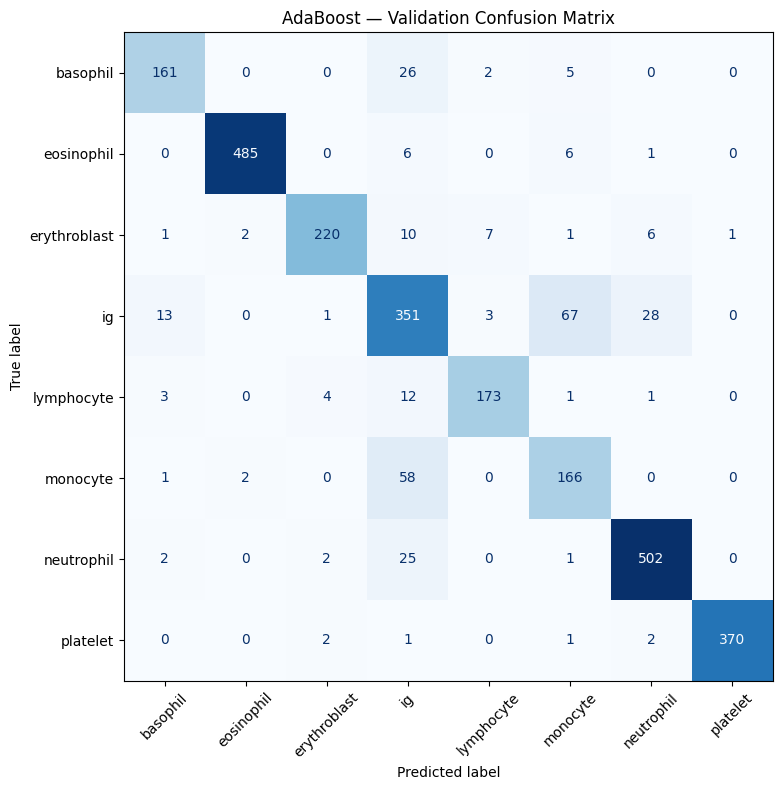

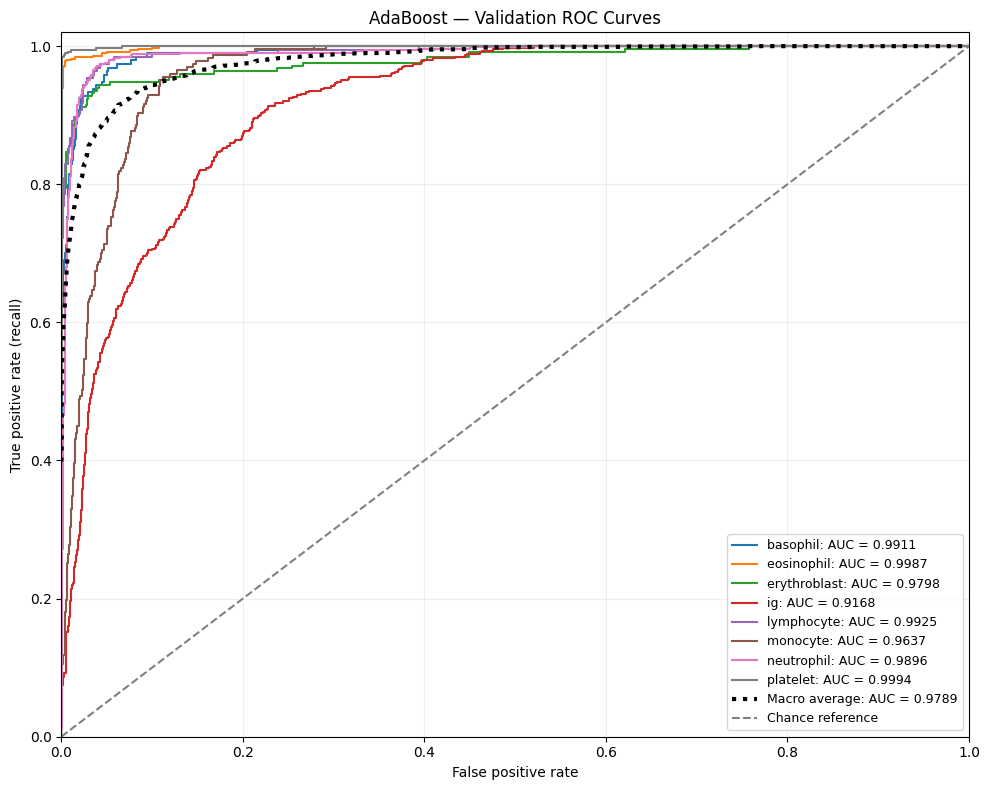

In [31]:
# Train AdaBoost and compare it with the previous baselines.

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from time import perf_counter

# Shallow trees provide the individual learners.
# Later trees focus more on examples misclassified by earlier learners.
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=2,
        random_state=42,
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42,
)

print("Training AdaBoost...", flush=True)

start_time = perf_counter()
ada_model.fit(X_train_selected, y_train)
ada_training_seconds = perf_counter() - start_time

print(f"Training finished in {ada_training_seconds:.1f} seconds.")

# Predict cell categories for training and validation images.
ada_train_predictions = ada_model.predict(X_train_selected)
ada_validation_predictions = ada_model.predict(
    X_validation_selected
)

# Decision scores provide category rankings for ROC analysis.
# They are not probabilities.
ada_validation_scores = ada_model.decision_function(
    X_validation_selected
)

ada_binary_labels = label_binarize(
    y_validation,
    classes=ada_model.classes_,
)

ada_class_aucs = [
    roc_auc_score(
        ada_binary_labels[:, index],
        ada_validation_scores[:, index],
    )
    for index in range(len(ada_model.classes_))
]

# Compare training and validation performance.
ada_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, ada_train_predictions),
        accuracy_score(y_validation, ada_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, ada_train_predictions, average="macro"),
        f1_score(
            y_validation,
            ada_validation_predictions,
            average="macro",
        ),
    ],
})

display(ada_performance.round(4))

# Record the same metrics used for the other baselines.
ada_result = {
    "Model": "AdaBoost",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, ada_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation,
        ada_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation,
        ada_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation,
        ada_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(ada_class_aucs),
    "Training seconds": ada_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result,
    rbf_result,
    poly_result,
    linear_result,
    forest_result,
    xgb_result,
    knn_result,
    tree_result,
    bagging_result,
    extra_result,
    ada_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nAdaBoost validation classification report:")
print(classification_report(
    y_validation,
    ada_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Display category-level prediction errors.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    ada_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("AdaBoost — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "adaboost_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot each category against all other categories.
fig, ax = plt.subplots(figsize=(10, 8))
ada_curves = []

for index, category in enumerate(ada_model.classes_):
    fpr, tpr, _ = roc_curve(
        ada_binary_labels[:, index],
        ada_validation_scores[:, index],
    )

    ada_curves.append((fpr, tpr))

    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {ada_class_aucs[index]:.4f}",
    )

# Average the category curves with equal weight per category.
shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in ada_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in ada_curves
], axis=0)

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {np.mean(ada_class_aucs):.4f}",
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance reference",
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("AdaBoost — Validation ROC Curves")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    results_dir / "adaboost_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics and predictions for later comparisons.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False,
)

pd.DataFrame({
    "Category": ada_model.classes_,
    "Validation AUC": ada_class_aucs,
}).to_csv(
    results_dir / "adaboost_validation_auc.csv",
    index=False,
)

ada_prediction_table = validation_df[["filepath", "label"]].copy()
ada_prediction_table["prediction"] = ada_validation_predictions

for index, category in enumerate(ada_model.classes_):
    ada_prediction_table[f"score_{category}"] = (
        ada_validation_scores[:, index]
    )

ada_prediction_table.to_csv(
    results_dir / "adaboost_validation_predictions.csv",
    index=False,
)

Training MLP...
Epoch   1 | training loss: 0.4379 | validation loss: 0.4903
Epoch   5 | training loss: 0.1280 | validation loss: 0.2758
Epoch  10 | training loss: 0.0432 | validation loss: 0.2851
Epoch  15 | training loss: 0.0229 | validation loss: 0.3506
Early stopping at epoch 18.

Best epoch: 6
Training and monitoring time: 4.3 seconds


,Set,Accuracy,Macro F1
0,Training,0.9699,0.9675
1,Validation,0.9063,0.8978


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
11,"MLP — 128, 64",300,0.9063,0.9063,0.8912,0.8978,0.9918,4.3353
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
10,AdaBoost,300,0.8887,0.8864,0.8750,0.8800,0.9789,144.4257
9,Extra Trees,300,0.8902,0.9012,0.8612,0.8764,0.9892,3.4418



MLP validation classification report:
              precision    recall  f1-score   support

    basophil      0.880     0.907     0.893       194
  eosinophil      0.982     0.986     0.984       498
erythroblast      0.956     0.883     0.918       248
          ig      0.777     0.819     0.797       463
  lymphocyte      0.916     0.845     0.879       194
    monocyte      0.850     0.749     0.796       227
  neutrophil      0.905     0.945     0.925       532
    platelet      0.984     0.995     0.989       376

    accuracy                          0.906      2732
   macro avg      0.906     0.891     0.898      2732
weighted avg      0.907     0.906     0.906      2732



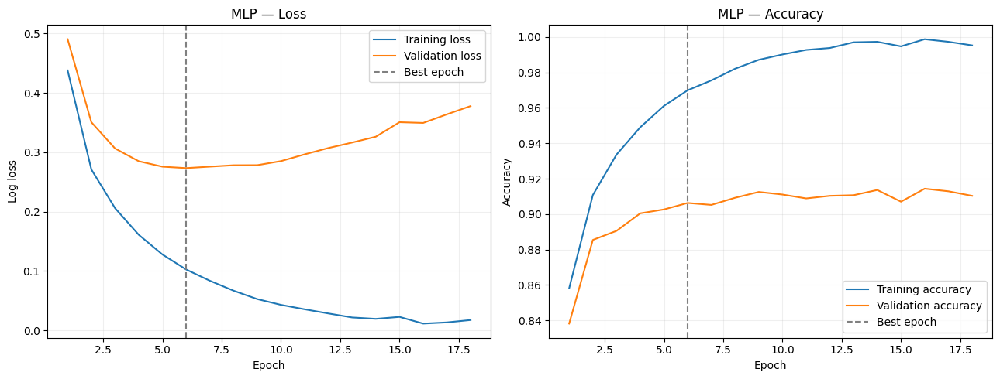

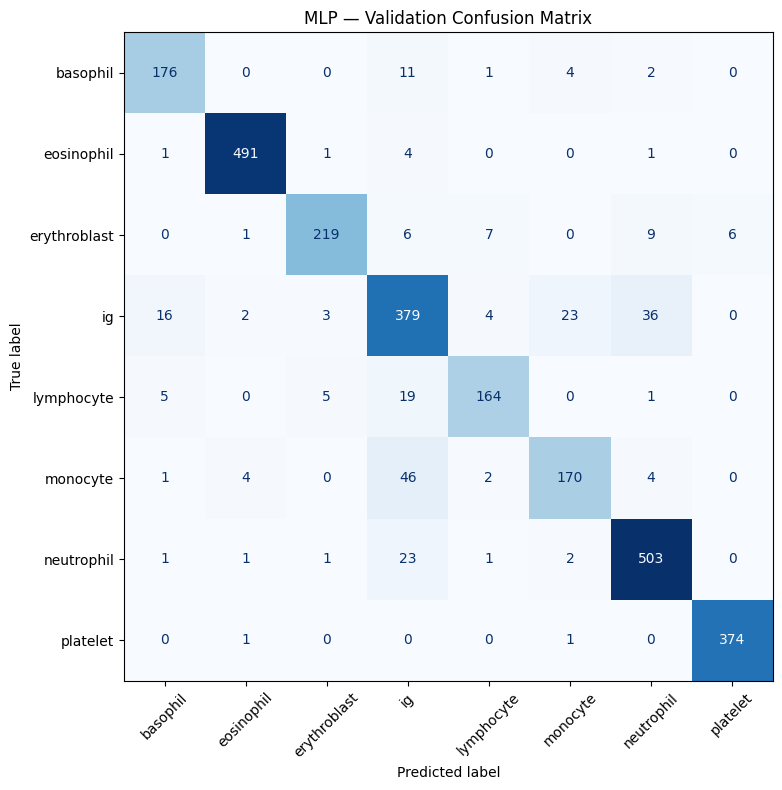

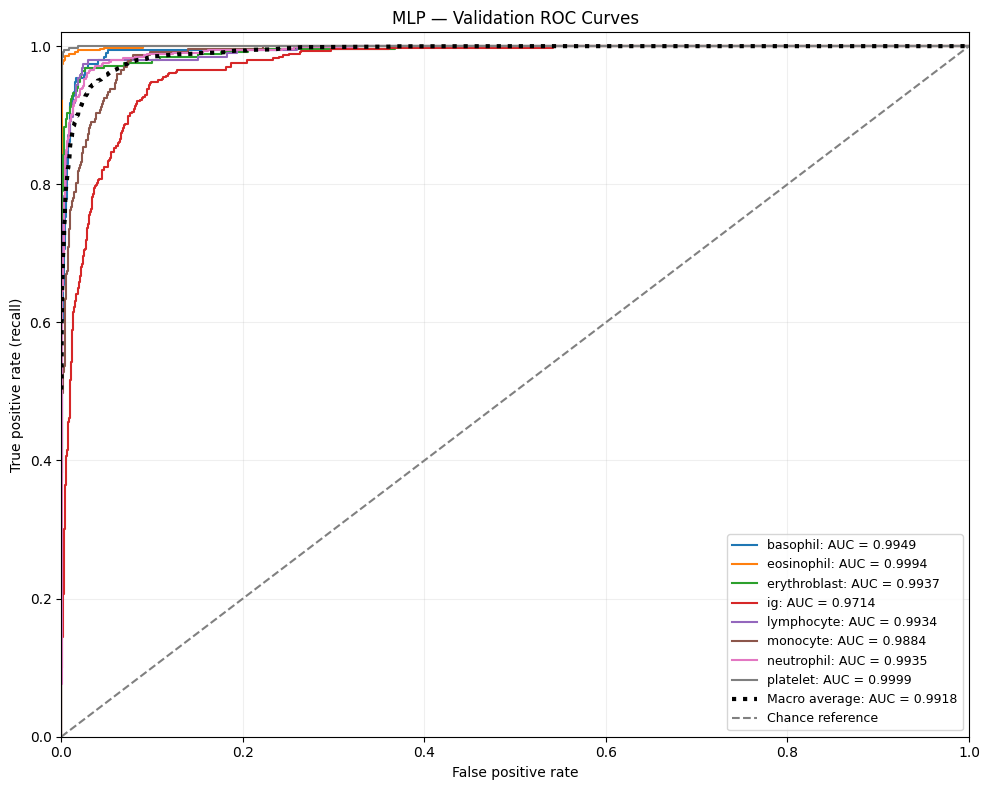

In [32]:
# Train an MLP on extracted features with validation-based early stopping.

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
from copy import deepcopy
from time import perf_counter

# Two hidden layers learn combinations of the extracted features.
# partial_fit lets us monitor the existing validation set after each epoch.
# Internal early stopping is disabled because validation is handled below.
mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=128,
    learning_rate_init=0.001,
    early_stopping=False,
    shuffle=True,
    random_state=42,
)

MAX_EPOCHS = 100
PATIENCE = 12
MIN_DELTA = 0.0001

mlp_classes = np.unique(y_train)
mlp_history_records = []
best_validation_loss = np.inf
best_mlp_model = None
best_epoch = 0
epochs_without_improvement = 0

print("Training MLP...", flush=True)
start_time = perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    # Update the network using training data only.
    mlp_model.partial_fit(
        X_train_selected,
        y_train,
        classes=mlp_classes,
    )

    # Evaluate both sets after the update.
    train_probabilities = mlp_model.predict_proba(X_train_selected)
    validation_probabilities = mlp_model.predict_proba(
        X_validation_selected
    )

    train_loss = log_loss(
        y_train, train_probabilities, labels=mlp_model.classes_
    )
    validation_loss = log_loss(
        y_validation,
        validation_probabilities,
        labels=mlp_model.classes_,
    )

    train_predictions = mlp_model.classes_[
        np.argmax(train_probabilities, axis=1)
    ]
    validation_predictions = mlp_model.classes_[
        np.argmax(validation_probabilities, axis=1)
    ]

    mlp_history_records.append({
        "Epoch": epoch,
        "Training loss": train_loss,
        "Validation loss": validation_loss,
        "Training accuracy": accuracy_score(y_train, train_predictions),
        "Validation accuracy": accuracy_score(
            y_validation, validation_predictions
        ),
    })

    # Keep a separate copy of the best network seen so far.
    if validation_loss < best_validation_loss - MIN_DELTA:
        best_validation_loss = validation_loss
        best_mlp_model = deepcopy(mlp_model)
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"training loss: {train_loss:.4f} | "
            f"validation loss: {validation_loss:.4f}",
            flush=True,
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

mlp_training_seconds = perf_counter() - start_time

# Restore the network from the best validation-loss epoch.
mlp_model = best_mlp_model
mlp_history = pd.DataFrame(mlp_history_records)

print(f"\nBest epoch: {best_epoch}")
print(f"Training and monitoring time: {mlp_training_seconds:.1f} seconds")

# Evaluate the restored model.
mlp_train_predictions = mlp_model.predict(X_train_selected)
mlp_validation_predictions = mlp_model.predict(X_validation_selected)
mlp_validation_probabilities = mlp_model.predict_proba(
    X_validation_selected
)

mlp_binary_labels = label_binarize(
    y_validation, classes=mlp_model.classes_
)

mlp_class_aucs = [
    roc_auc_score(
        mlp_binary_labels[:, index],
        mlp_validation_probabilities[:, index],
    )
    for index in range(len(mlp_model.classes_))
]

mlp_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, mlp_train_predictions),
        accuracy_score(y_validation, mlp_validation_predictions),
    ],
    "Macro F1": [
        f1_score(y_train, mlp_train_predictions, average="macro"),
        f1_score(
            y_validation, mlp_validation_predictions, average="macro"
        ),
    ],
})

display(mlp_performance.round(4))

mlp_result = {
    "Model": "MLP — 128, 64",
    "Features": X_train_selected.shape[1],
    "Validation accuracy": accuracy_score(
        y_validation, mlp_validation_predictions
    ),
    "Validation macro precision": precision_score(
        y_validation, mlp_validation_predictions,
        average="macro", zero_division=0,
    ),
    "Validation macro recall": recall_score(
        y_validation, mlp_validation_predictions,
        average="macro", zero_division=0,
    ),
    "Validation macro F1": f1_score(
        y_validation, mlp_validation_predictions, average="macro"
    ),
    "Validation macro AUC": np.mean(mlp_class_aucs),
    "Training seconds": mlp_training_seconds,
}

baseline_comparison = pd.DataFrame([
    logistic_result, rbf_result, poly_result, linear_result,
    forest_result, xgb_result, knn_result, tree_result,
    bagging_result, extra_result, ada_result, mlp_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nMLP validation classification report:")
print(classification_report(
    y_validation,
    mlp_validation_predictions,
    labels=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Plot learning curves to show how performance changes during training.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for column in ["Training loss", "Validation loss"]:
    axes[0].plot(mlp_history["Epoch"], mlp_history[column], label=column)

for column in ["Training accuracy", "Validation accuracy"]:
    axes[1].plot(mlp_history["Epoch"], mlp_history[column], label=column)

axes[0].set(title="MLP — Loss", xlabel="Epoch", ylabel="Log loss")
axes[1].set(title="MLP — Accuracy", xlabel="Epoch", ylabel="Accuracy")

for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(
    results_dir / "mlp_learning_curves.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

# Display the confusion matrix.
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    mlp_validation_predictions,
    labels=CLASS_NAMES,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)
ax.set_title("MLP — Validation Confusion Matrix")
plt.tight_layout()
fig.savefig(
    results_dir / "mlp_validation_confusion_matrix.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

# Plot category-level and macro-average ROC curves.
fig, ax = plt.subplots(figsize=(10, 8))
mlp_curves = []

for index, category in enumerate(mlp_model.classes_):
    fpr, tpr, _ = roc_curve(
        mlp_binary_labels[:, index],
        mlp_validation_probabilities[:, index],
    )
    mlp_curves.append((fpr, tpr))
    ax.plot(
        fpr, tpr,
        label=f"{category}: AUC = {mlp_class_aucs[index]:.4f}",
    )

shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in mlp_curves
]))
mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr) for fpr, tpr in mlp_curves
], axis=0)

ax.plot(
    shared_fpr, mean_tpr,
    color="black", linestyle=":", linewidth=3,
    label=f"Macro average: AUC = {np.mean(mlp_class_aucs):.4f}",
)
ax.plot(
    [0, 1], [0, 1],
    color="gray", linestyle="--", label="Chance reference",
)
ax.set(
    title="MLP — Validation ROC Curves",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1), ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(
    results_dir / "mlp_validation_roc.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

# Save results and aligned predictions for later comparisons.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv", index=False
)
mlp_history.to_csv(results_dir / "mlp_training_history.csv", index=False)

mlp_prediction_table = validation_df[["filepath", "label"]].copy()
mlp_prediction_table["prediction"] = mlp_validation_predictions

for index, category in enumerate(mlp_model.classes_):
    mlp_prediction_table[f"probability_{category}"] = (
        mlp_validation_probabilities[:, index]
    )

mlp_prediction_table.to_csv(
    results_dir / "mlp_validation_predictions.csv", index=False
)

TensorFlow version: 2.20.0
Available GPUs: []

Category mapping:
0: basophil
1: eosinophil
2: erythroblast
3: ig
4: lymphocyte
5: monocyte
6: neutrophil
7: platelet


2026-10-25 12:21:03.704894: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel range: 17.359987258911133 to 255.00006103515625


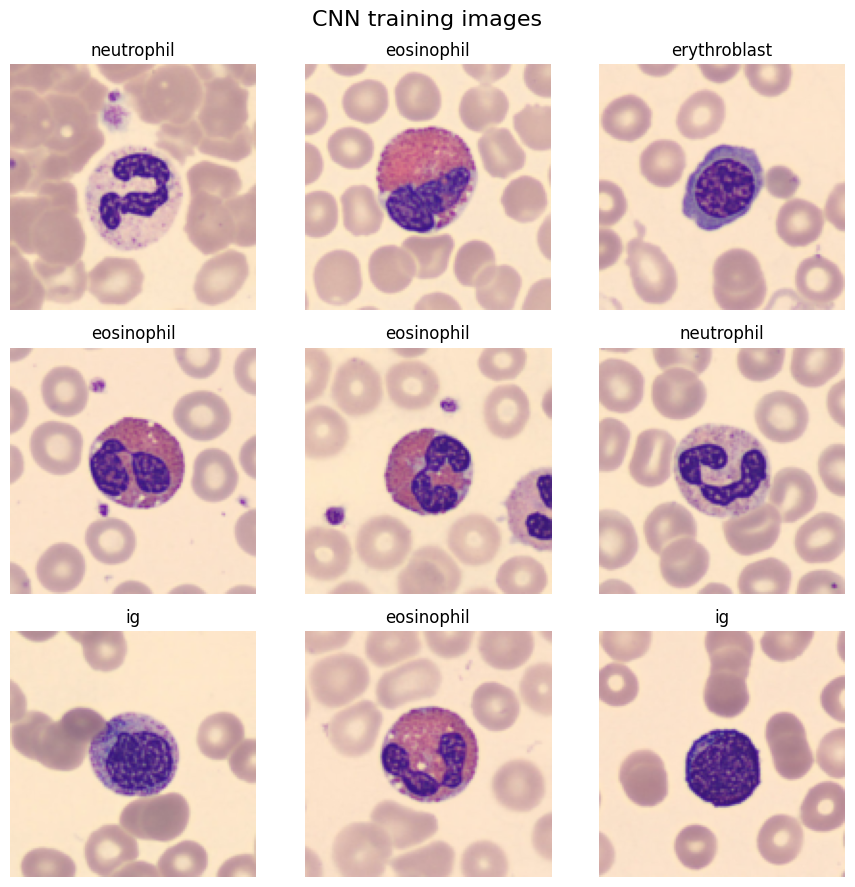

In [33]:
# Prepare training and validation image batches for the CNN.

import tensorflow as tf

# Set random seeds for TensorFlow, NumPy, and Python.
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

CNN_IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

# Use one consistent category-to-number mapping for both sets.
cnn_class_names = list(CLASS_NAMES)
cnn_label_to_id = {
    category: index
    for index, category in enumerate(cnn_class_names)
}

print("\nCategory mapping:")
for category, index in cnn_label_to_id.items():
    print(f"{index}: {category}")


def load_cnn_image(filepath, label):
    # Read and decode the image into three RGB channels.
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])

    # Resize every image to the same dimensions.
    # Keep pixels in the 0–255 range; the CNN will include a rescaling layer.
    image = tf.image.resize(
        image,
        CNN_IMAGE_SIZE,
        antialias=True,
    )

    return image, label


def make_cnn_dataset(image_table, training=False):
    # Convert category names into integer labels.
    label_ids = image_table["label"].map(cnn_label_to_id)

    if label_ids.isna().any():
        raise ValueError("An image has an unknown category label.")

    dataset = tf.data.Dataset.from_tensor_slices((
        image_table["filepath"].astype(str).to_numpy(),
        label_ids.to_numpy(dtype=np.int32),
    ))

    # Shuffle training paths before loading images to save memory.
    # Preserve validation order so predictions match validation_df.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_table),
            seed=42,
            reshuffle_each_iteration=True,
        )

    # Load images as needed instead of placing the entire dataset in memory.
    dataset = dataset.map(
        load_cnn_image,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True,
    )

    dataset = dataset.batch(BATCH_SIZE)

    # Prepare upcoming batches while the current batch is processed.
    return dataset.prefetch(tf.data.AUTOTUNE)


cnn_train_ds = make_cnn_dataset(train_df, training=True)
cnn_validation_ds = make_cnn_dataset(validation_df, training=False)

# Inspect one training batch to check image dimensions and labels.
sample_images, sample_labels = next(iter(cnn_train_ds))

print("\nImage batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(sample_images)),
    "to",
    float(tf.reduce_max(sample_images)),
)

# Display nine images with their correct labels.
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for index, ax in enumerate(axes.flat):
    # Divide by 255 only for displaying float-valued images correctly.
    display_image = np.clip(sample_images[index].numpy() / 255.0, 0, 1)
    label_id = int(sample_labels[index].numpy())

    ax.imshow(display_image)
    ax.set_title(cnn_class_names[label_id])
    ax.axis("off")

fig.suptitle("CNN training images", fontsize=16)
plt.tight_layout()
plt.show()

# Save the category mapping for interpreting future predictions.
pd.DataFrame({
    "Category": cnn_class_names,
    "Label ID": range(len(cnn_class_names)),
}).to_csv(
    split_dir / "cnn_category_mapping.csv",
    index=False,
)

All eight categories are present.
No duplicate paths or exact pixel duplicates in the training inventory.


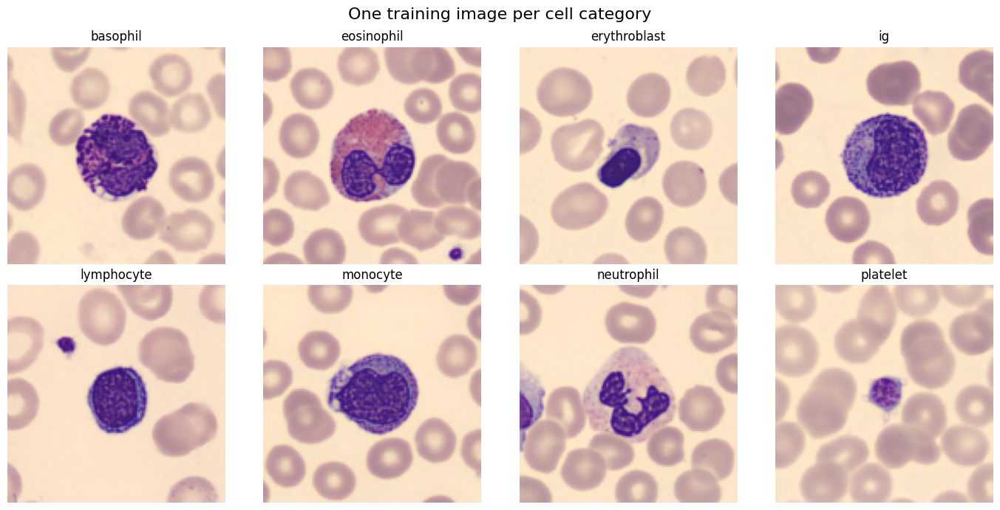

In [34]:
# Display one training image from each category and verify exact uniqueness.

# Confirm that all eight categories remain in the training set.
assert set(train_df["label"]) == set(cnn_class_names)

# Confirm that no repeated file paths or exact pixel duplicates remain.
assert train_df["filepath"].is_unique
assert train_df["pixel_hash"].is_unique

print("All eight categories are present.")
print("No duplicate paths or exact pixel duplicates in the training inventory.")

# Choose one image per category for this preview.
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, category in zip(axes.flat, cnn_class_names):
    example = train_df[
        train_df["label"] == category
    ].sample(n=1, random_state=42).iloc[0]

    # Use the same image-loading function as the CNN pipeline.
    image, _ = load_cnn_image(
        tf.constant(example["filepath"]),
        tf.constant(cnn_label_to_id[category]),
    )

    ax.imshow(np.clip(image.numpy() / 255.0, 0, 1))
    ax.set_title(category)
    ax.axis("off")

fig.suptitle("One training image per cell category", fontsize=16)
plt.tight_layout()
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,744 (4.09 MB)

 Trainable params: 1,072,744 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

Available GPUs: []
Training on all batches...
Epoch 1/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.3191 - loss: 1.7209
Epoch 1: val_loss improved from None to 0.90376, saving model to /kaggle/working/cnn/best_small_cnn.keras

Epoch 1: finished saving model to /kaggle/working/cnn/best_small_cnn.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 71s 203ms/step - accuracy: 0.4145 - loss: 1.4637 - val_accuracy: 0.6285 - val_loss: 0.9038
Epoch 2/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.6056 - loss: 1.0130
Epoch 2: val_loss improved from 0.90376 to 0.67294, saving model to /kaggle/working/cnn/best_small_cnn.keras

Epoch 2: finished saving model to /kaggle/working/cnn/best_small_cnn.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 70s 203ms/step - accuracy: 0.6295 - loss: 0.9507 - val_accuracy: 0.7335 - val_loss: 0.6729
Epoch 3/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.6657 - loss: 0.8402
Epoch 3: val_loss improved from 0.67294 to 0.46035, saving model to /kaggle/working

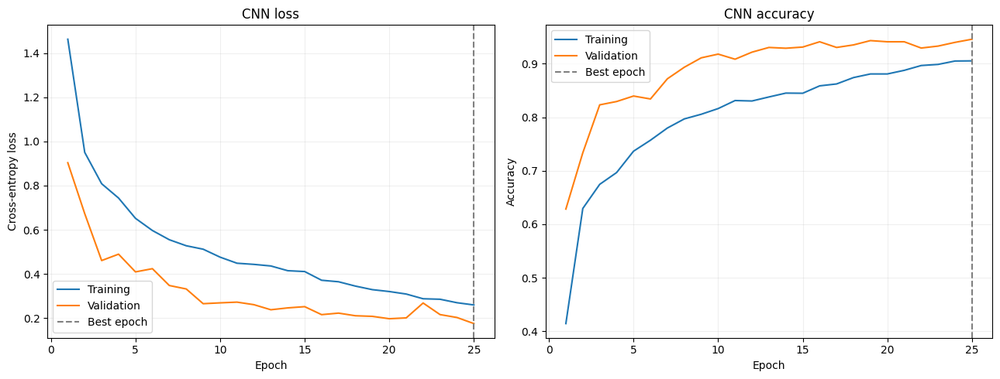

In [35]:
# Build a small CNN and train it on all training image batches.

from tensorflow.keras import layers, models
from time import perf_counter

tf.keras.utils.set_random_seed(42)

# Store training history and the best model during the run.
cnn_output_dir = Path("/kaggle/working/cnn")
cnn_output_dir.mkdir(parents=True, exist_ok=True)

# Learn image features directly from pixels.
# Rescaling converts pixel values from approximately 0–255 to 0–1.
cnn_model = models.Sequential([
    layers.Input(shape=(*CNN_IMAGE_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    # Apply random flips only during training.
    # Cell identity should not depend on its orientation in the image.
    layers.RandomFlip("horizontal_and_vertical", seed=42),

    # Convolutions learn local patterns; pooling reduces spatial dimensions.
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Preserve coarse spatial information for the classification layers.
    layers.Flatten(),
    layers.Dense(64, activation="relu"),

    # Dropout reduces reliance on individual hidden units during training.
    layers.Dropout(0.4, seed=42),

    # Produce one probability for each of the eight categories.
    layers.Dense(len(cnn_class_names), activation="softmax"),
])

# Integer category labels require sparse categorical cross-entropy.
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cnn_model.summary()

# Save the model whenever validation loss reaches a new minimum.
# Stop after five epochs without improvement and restore the best weights.
cnn_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(cnn_output_dir / "best_small_cnn.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(cnn_output_dir / "training_history.csv")
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Training on all batches...", flush=True)

start_time = perf_counter()

# Passing the complete datasets uses all images each epoch.
# Validation images do not update the model's weights.
cnn_history = cnn_model.fit(
    cnn_train_ds,
    validation_data=cnn_validation_ds,
    epochs=25,
    callbacks=cnn_callbacks,
    verbose=1,
)

cnn_training_seconds = perf_counter() - start_time

# Reload the checkpoint with the lowest validation loss.
cnn_model = tf.keras.models.load_model(
    cnn_output_dir / "best_small_cnn.keras"
)

cnn_history_df = pd.DataFrame(cnn_history.history)
cnn_history_df.insert(
    0, "epoch", range(1, len(cnn_history_df) + 1)
)

best_cnn_epoch = int(
    cnn_history_df.loc[cnn_history_df["val_loss"].idxmin(), "epoch"]
)

print(f"\nTraining and validation time: {cnn_training_seconds / 60:.1f} minutes")
print("Best epoch:", best_cnn_epoch)

# Plot learning curves to check improvement and overfitting.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    cnn_history_df["epoch"], cnn_history_df["loss"], label="Training"
)
axes[0].plot(
    cnn_history_df["epoch"], cnn_history_df["val_loss"], label="Validation"
)
axes[0].set(title="CNN loss", xlabel="Epoch", ylabel="Cross-entropy loss")

axes[1].plot(
    cnn_history_df["epoch"], cnn_history_df["accuracy"], label="Training"
)
axes[1].plot(
    cnn_history_df["epoch"], cnn_history_df["val_accuracy"],
    label="Validation",
)
axes[1].set(title="CNN accuracy", xlabel="Epoch", ylabel="Accuracy")

for ax in axes:
    ax.axvline(
        best_cnn_epoch, color="gray", linestyle="--", label="Best epoch"
    )
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(
    cnn_output_dir / "learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

Predicting training images...
342/342 ━━━━━━━━━━━━━━━━━━━━ 21s 63ms/step
Predicting validation images...
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step


,Set,Accuracy,Macro F1
0,Training,0.9688,0.9672
1,Validation,0.9458,0.9432


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
12,Small 2D CNN,128×128 RGB pixels,0.9458,0.9483,0.9388,0.9432,0.9970,1808.8622
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
11,"MLP — 128, 64",300,0.9063,0.9063,0.8912,0.8978,0.9918,4.3353
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844
10,AdaBoost,300,0.8887,0.8864,0.8750,0.8800,0.9789,144.4257



CNN validation classification report:
              precision    recall  f1-score   support

    basophil      0.952     0.928     0.940       194
  eosinophil      0.998     0.964     0.981       498
erythroblast      0.950     0.919     0.934       248
          ig      0.865     0.924     0.894       463
  lymphocyte      0.963     0.948     0.956       194
    monocyte      0.929     0.868     0.897       227
  neutrophil      0.940     0.964     0.952       532
    platelet      0.989     0.995     0.992       376

    accuracy                          0.946      2732
   macro avg      0.948     0.939     0.943      2732
weighted avg      0.947     0.946     0.946      2732



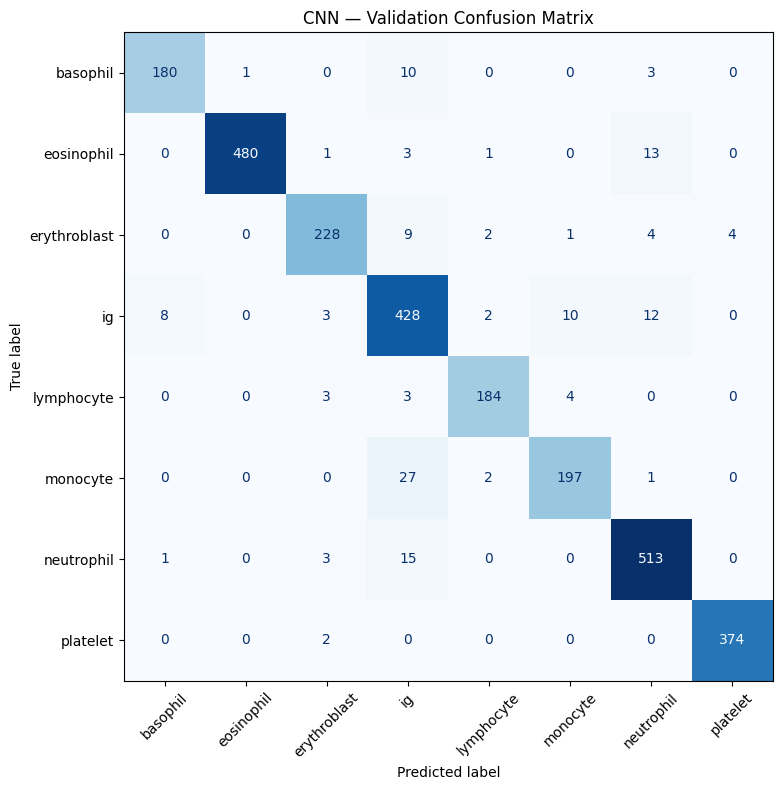

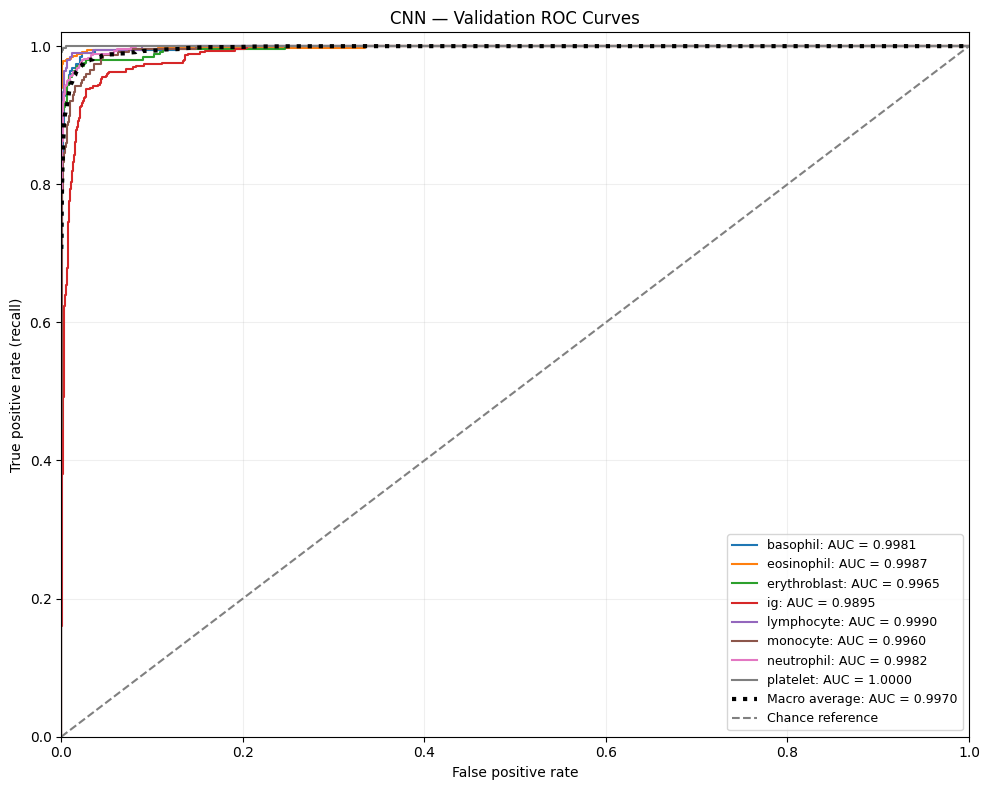

In [36]:
# Evaluate the saved CNN on training and validation images without retraining.

# Load the checkpoint with the lowest validation loss.
cnn_model = tf.keras.models.load_model(
    "/kaggle/working/cnn/best_small_cnn.keras"
)

# Preserve image order so predictions align with the table labels.
# predict() disables random flips and dropout automatically.
cnn_train_eval_ds = make_cnn_dataset(train_df, training=False)
cnn_validation_eval_ds = make_cnn_dataset(
    validation_df, training=False
)

print("Predicting training images...")
cnn_train_probabilities = cnn_model.predict(
    cnn_train_eval_ds, verbose=1
)

print("Predicting validation images...")
cnn_validation_probabilities = cnn_model.predict(
    cnn_validation_eval_ds, verbose=1
)

# Convert the highest-probability output into its category name.
cnn_classes = np.asarray(cnn_class_names)

cnn_train_predictions = cnn_classes[
    np.argmax(cnn_train_probabilities, axis=1)
]
cnn_validation_predictions = cnn_classes[
    np.argmax(cnn_validation_probabilities, axis=1)
]

# Read true labels in the same order as the prediction datasets.
cnn_train_labels = train_df["label"].to_numpy()
cnn_validation_labels = validation_df["label"].to_numpy()

assert len(cnn_validation_predictions) == len(cnn_validation_labels)
assert np.isfinite(cnn_validation_probabilities).all()

# Match each probability column to its category explicitly.
cnn_binary_labels = np.column_stack([
    (cnn_validation_labels == category).astype(int)
    for category in cnn_classes
])

cnn_class_aucs = [
    roc_auc_score(
        cnn_binary_labels[:, index],
        cnn_validation_probabilities[:, index],
    )
    for index in range(len(cnn_classes))
]

# Both sets are now evaluated using the same saved model in inference mode.
cnn_performance = pd.DataFrame({
    "Set": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(cnn_train_labels, cnn_train_predictions),
        accuracy_score(cnn_validation_labels, cnn_validation_predictions),
    ],
    "Macro F1": [
        f1_score(
            cnn_train_labels, cnn_train_predictions, average="macro"
        ),
        f1_score(
            cnn_validation_labels,
            cnn_validation_predictions,
            average="macro",
        ),
    ],
})

display(cnn_performance.round(4))

# The CNN uses pixels, so the 300-feature count does not apply.
cnn_result = {
    "Model": "Small 2D CNN",
    "Features": "128×128 RGB pixels",
    "Validation accuracy": accuracy_score(
        cnn_validation_labels, cnn_validation_predictions
    ),
    "Validation macro precision": precision_score(
        cnn_validation_labels,
        cnn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro recall": recall_score(
        cnn_validation_labels,
        cnn_validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "Validation macro F1": f1_score(
        cnn_validation_labels,
        cnn_validation_predictions,
        average="macro",
    ),
    "Validation macro AUC": np.mean(cnn_class_aucs),
    "Training seconds": cnn_training_seconds,
}

# Include every completed baseline in the comparison.
baseline_comparison = pd.DataFrame([
    logistic_result, rbf_result, poly_result, linear_result,
    forest_result, xgb_result, knn_result, tree_result,
    bagging_result, extra_result, ada_result, mlp_result,
    cnn_result,
])

display(
    baseline_comparison.sort_values(
        "Validation macro F1", ascending=False
    ).round(4)
)

print("\nCNN validation classification report:")
cnn_report = classification_report(
    cnn_validation_labels,
    cnn_validation_predictions,
    labels=cnn_class_names,
    digits=3,
    zero_division=0,
)
print(cnn_report)

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Display correct predictions and category mix-ups.
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    cnn_validation_labels,
    cnn_validation_predictions,
    labels=cnn_class_names,
    display_labels=cnn_class_names,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)

ax.set_title("CNN — Validation Confusion Matrix")
plt.tight_layout()

fig.savefig(
    results_dir / "cnn_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Plot one ROC curve per category versus all other categories.
fig, ax = plt.subplots(figsize=(10, 8))
cnn_curves = []

for index, category in enumerate(cnn_classes):
    fpr, tpr, _ = roc_curve(
        cnn_binary_labels[:, index],
        cnn_validation_probabilities[:, index],
    )
    cnn_curves.append((fpr, tpr))

    ax.plot(
        fpr, tpr,
        label=f"{category}: AUC = {cnn_class_aucs[index]:.4f}",
    )

shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in cnn_curves
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in cnn_curves
], axis=0)

ax.plot(
    shared_fpr, mean_tpr,
    color="black", linestyle=":", linewidth=3,
    label=f"Macro average: AUC = {np.mean(cnn_class_aucs):.4f}",
)
ax.plot(
    [0, 1], [0, 1],
    color="gray", linestyle="--", label="Chance reference",
)
ax.set(
    title="CNN — Validation ROC Curves",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(
    results_dir / "cnn_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save metrics, the classification report, and aligned predictions.
baseline_comparison.to_csv(
    results_dir / "baseline_comparison.csv", index=False
)
cnn_performance.to_csv(
    results_dir / "cnn_training_validation_metrics.csv", index=False
)
(results_dir / "cnn_classification_report.txt").write_text(
    cnn_report, encoding="utf-8"
)

pd.DataFrame({
    "Category": cnn_classes,
    "Validation AUC": cnn_class_aucs,
}).to_csv(
    results_dir / "cnn_validation_auc.csv", index=False
)

cnn_prediction_table = validation_df[["filepath", "label"]].copy()
cnn_prediction_table["prediction"] = cnn_validation_predictions

for index, category in enumerate(cnn_classes):
    cnn_prediction_table[f"probability_{category}"] = (
        cnn_validation_probabilities[:, index]
    )

cnn_prediction_table.to_csv(
    results_dir / "cnn_validation_predictions.csv", index=False
)

In [37]:
# Save fitted models and preprocessing so they can be reused without retraining.
from pathlib import Path
import joblib

model_dir = Path("/kaggle/working/models")
model_dir.mkdir(parents=True, exist_ok=True)

trained_models = {
    "logistic_regression": logistic_model,
    "svm_rbf": rbf_model,
    "svm_polynomial": poly_model,
    "svm_linear": linear_model,
    "random_forest": forest_model,
    "xgboost": xgb_model,
    "knn": knn_model,
    "decision_tree": tree_model,
    "bagging": bagging_model,
    "extra_trees": extra_model,
    "adaboost": ada_model,
    "mlp": mlp_model,
}

for name, model in trained_models.items():
    joblib.dump(model, model_dir / f"{name}.joblib", compress=3)
    print(f"Saved: {name}")

joblib.dump(
    {
        "preprocessing": preprocessing,
        "feature_selection": feature_selection,
        "feature_names": list(feature_names),
        "selected_feature_names": list(selected_feature_names),
        "class_names": list(CLASS_NAMES),
        "xgb_label_encoder": xgb_label_encoder,
    },
    model_dir / "preprocessing_and_labels.joblib",
    compress=3,
)

print("\nSaved preprocessing and category mappings.")
print("Model folder:", model_dir)

Saved: logistic_regression
Saved: svm_rbf
Saved: svm_polynomial
Saved: svm_linear
Saved: random_forest
Saved: xgboost
Saved: knn
Saved: decision_tree
Saved: bagging
Saved: extra_trees
Saved: adaboost
Saved: mlp

Saved preprocessing and category mappings.
Model folder: /kaggle/working/models


In [38]:
# Prepare MobileNetV2 using uploaded pretrained weights without an internet download.
import tensorflow as tf
from pathlib import Path

tf.keras.utils.set_random_seed(SEED)

transfer_dir = Path("/kaggle/working/transfer_learning")
transfer_dir.mkdir(parents=True, exist_ok=True)

# Locate the weights file in the attached Kaggle datasets.
weights_filename = (
    "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_128_no_top.h5"
)
weights_matches = sorted(
    Path("/kaggle/input").rglob(weights_filename)
)

if not weights_matches:
    raise FileNotFoundError(
        "Pretrained weights were not found. Attach the dataset containing "
        f"{weights_filename} to this notebook, then rerun this cell."
    )

weights_path = weights_matches[0]
print("Loading pretrained weights from:", weights_path)

# Load the pretrained image feature extractor from the local file.
transfer_base = tf.keras.applications.MobileNetV2(
    input_shape=(*CNN_IMAGE_SIZE, 3),
    include_top=False,
    weights=str(weights_path),
)

# Initially train only the new classification layer.
transfer_base.trainable = False

inputs = tf.keras.Input(shape=(*CNN_IMAGE_SIZE, 3))

x = tf.keras.layers.RandomFlip(
    "horizontal_and_vertical",
    seed=SEED,
)(inputs)

# Convert the existing 0–255 image pixels to the required -1–1 range.
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1,
)(x)

x = transfer_base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3, seed=SEED)(x)

outputs = tf.keras.layers.Dense(
    len(cnn_class_names),
    activation="softmax",
)(x)

transfer_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="mobilenetv2_blood_cells",
)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

transfer_model.summary()

print("\nAvailable GPUs:", tf.config.list_physical_devices("GPU"))
print("Categories:", cnn_class_names)
print("Ready for training on the existing training split.")

Loading pretrained weights from: /kaggle/input/datasets/reinanizam/mobilenetv2-pretrained-weights-128128/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_128_no_top.h5


Model: "mobilenetv2_blood_cells"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Available GPUs: []
Categories: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Ready for training on the existing training split.


Training the classification layer on all training batches...
Epoch 1/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.5992 - loss: 1.1315
Epoch 1: val_loss improved from None to 0.33908, saving model to /kaggle/working/transfer_learning/best_mobilenetv2_head.keras

Epoch 1: finished saving model to /kaggle/working/transfer_learning/best_mobilenetv2_head.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 78s 219ms/step - accuracy: 0.7447 - loss: 0.7282 - val_accuracy: 0.8909 - val_loss: 0.3391
Epoch 2/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.8613 - loss: 0.4077
Epoch 2: val_loss improved from 0.33908 to 0.26263, saving model to /kaggle/working/transfer_learning/best_mobilenetv2_head.keras

Epoch 2: finished saving model to /kaggle/working/transfer_learning/best_mobilenetv2_head.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 66s 192ms/step - accuracy: 0.8700 - loss: 0.3774 - val_accuracy: 0.9158 - val_loss: 0.2626
Epoch 3/25
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.8865

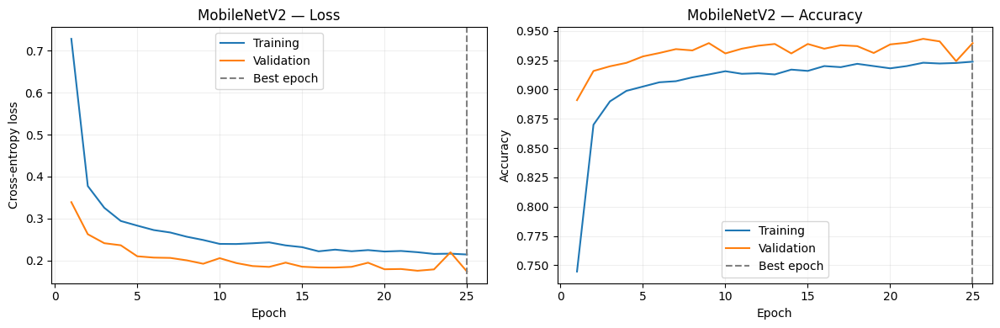

In [39]:
# Train the MobileNetV2 classification layer and save its best validation checkpoint.
from time import perf_counter
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

transfer_checkpoint = transfer_dir / "best_mobilenetv2_head.keras"

transfer_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(transfer_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(transfer_dir / "head_training_log.csv")
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

print("Training the classification layer on all training batches...")
start_time = perf_counter()

transfer_history = transfer_model.fit(
    cnn_train_ds,
    validation_data=cnn_validation_ds,
    epochs=25,
    callbacks=transfer_callbacks,
    verbose=1,
)

transfer_training_seconds = perf_counter() - start_time

# Load the saved model with the lowest validation loss.
transfer_model = tf.keras.models.load_model(
    str(transfer_checkpoint)
)

# Save the metrics recorded during training.
transfer_history_df = pd.DataFrame(transfer_history.history)
transfer_history_df.insert(
    0, "epoch", range(1, len(transfer_history_df) + 1)
)
transfer_history_df.to_csv(
    transfer_dir / "head_training_history.csv",
    index=False,
)

best_transfer_epoch = int(
    transfer_history_df.loc[
        transfer_history_df["val_loss"].idxmin(), "epoch"
    ]
)

print(
    f"\nTraining and validation time: "
    f"{transfer_training_seconds / 60:.1f} minutes"
)
print("Best epoch:", best_transfer_epoch)
print("Saved model:", transfer_checkpoint)

# Plot the learning curves and mark the best epoch.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title, ylabel in [
    (axes[0], "loss", "MobileNetV2 — Loss", "Cross-entropy loss"),
    (axes[1], "accuracy", "MobileNetV2 — Accuracy", "Accuracy"),
]:
    ax.plot(
        transfer_history_df["epoch"],
        transfer_history_df[metric],
        label="Training",
    )
    ax.plot(
        transfer_history_df["epoch"],
        transfer_history_df[f"val_{metric}"],
        label="Validation",
    )
    ax.axvline(
        best_transfer_epoch,
        color="gray",
        linestyle="--",
        label="Best epoch",
    )
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=ylabel,
    )
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    transfer_dir / "head_learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

Predicting training images...
342/342 ━━━━━━━━━━━━━━━━━━━━ 51s 147ms/step
Predicting validation images...
86/86 ━━━━━━━━━━━━━━━━━━━━ 12s 144ms/step

MobileNetV2 — frozen-base evaluation


,Set,Accuracy,Macro precision,Macro recall,Macro F1
0,Training,0.9530,0.9502,0.9483,0.9491
1,Validation,0.9396,0.9375,0.9329,0.9351



Validation classification report:

              precision    recall  f1-score   support

    basophil     0.9326    0.9278    0.9302       194
  eosinophil     0.9918    0.9759    0.9838       498
erythroblast     0.9512    0.9435    0.9474       248
          ig     0.8745    0.8877    0.8810       463
  lymphocyte     0.9227    0.9227    0.9227       194
    monocyte     0.9032    0.8634    0.8829       227
  neutrophil     0.9295    0.9662    0.9475       532
    platelet     0.9946    0.9761    0.9852       376

    accuracy                         0.9396      2732
   macro avg     0.9375    0.9329    0.9351      2732
weighted avg     0.9400    0.9396    0.9397      2732



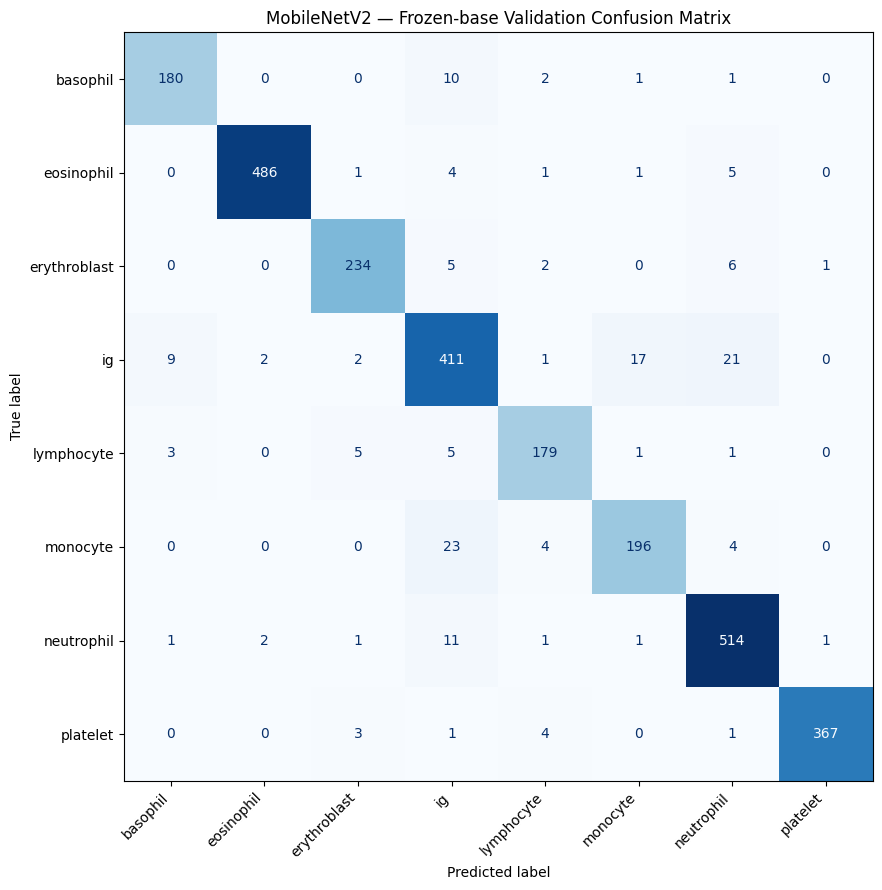

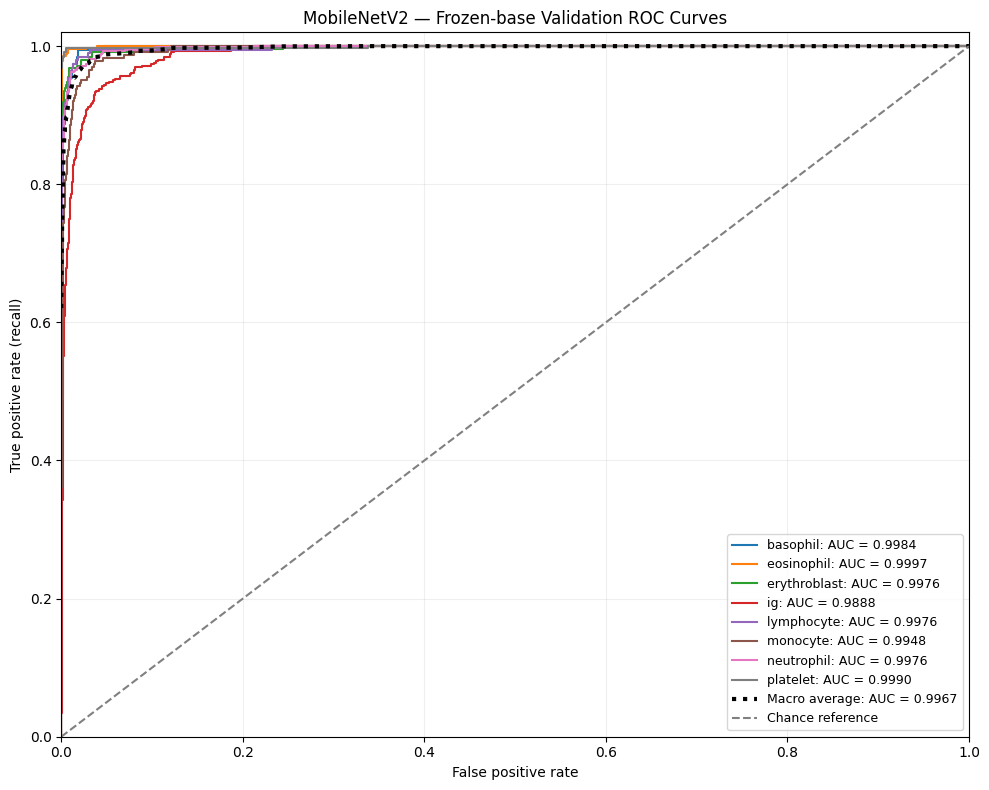


Updated model comparison:


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
5,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
12,Small 2D CNN,128×128 RGB pixels,0.9458,0.9483,0.9388,0.9432,0.9970,1808.8622
13,MobileNetV2 — frozen base,128×128 RGB pixels,0.9396,0.9375,0.9329,0.9351,0.9967,1760.4727
2,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
8,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
1,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
4,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
11,"MLP — 128, 64",300,0.9063,0.9063,0.8912,0.8978,0.9918,4.3353
3,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816
0,Logistic Regression,300,0.9008,0.8915,0.8894,0.8903,0.9904,10.3844



Validation accuracy: 93.96%
Validation macro F1: 0.9351
Validation macro AUC: 0.9967
Results saved to: /kaggle/working/transfer_learning
The test set has not been used.


In [40]:
# Evaluate the saved MobileNetV2 model and save metrics, predictions, and plots.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
)

transfer_dir = Path("/kaggle/working/transfer_learning")
transfer_dir.mkdir(parents=True, exist_ok=True)

checkpoint = transfer_dir / "best_mobilenetv2_head.keras"
if not checkpoint.is_file():
    raise FileNotFoundError(
        f"Saved checkpoint not found: {checkpoint}"
    )

transfer_model = tf.keras.models.load_model(
    str(checkpoint),
    compile=False,
)

# Use the same category order that defined the model's output layer.
transfer_classes = np.asarray(cnn_class_names)

if transfer_model.output_shape[-1] != len(transfer_classes):
    raise ValueError("Model output count does not match the category mapping.")

# Disable shuffling so predictions match the dataframe row order.
transfer_train_eval_ds = make_cnn_dataset(train_df, training=False)
transfer_val_eval_ds = make_cnn_dataset(validation_df, training=False)

print("Predicting training images...", flush=True)
transfer_train_probs = transfer_model.predict(
    transfer_train_eval_ds,
    verbose=1,
)

print("Predicting validation images...", flush=True)
transfer_val_probs = transfer_model.predict(
    transfer_val_eval_ds,
    verbose=1,
)

transfer_train_true = train_df["label"].to_numpy()
transfer_val_true = validation_df["label"].to_numpy()

transfer_train_pred = transfer_classes[
    np.argmax(transfer_train_probs, axis=1)
]
transfer_val_pred = transfer_classes[
    np.argmax(transfer_val_probs, axis=1)
]

assert len(transfer_train_probs) == len(train_df)
assert len(transfer_val_probs) == len(validation_df)

if not np.isfinite(transfer_val_probs).all():
    raise ValueError("Validation predictions contain non-finite values.")

# Calculate comparable metrics using the final saved model.
metric_rows = []

for set_name, true_labels, predictions in [
    ("Training", transfer_train_true, transfer_train_pred),
    ("Validation", transfer_val_true, transfer_val_pred),
]:
    metric_rows.append({
        "Set": set_name,
        "Accuracy": accuracy_score(true_labels, predictions),
        "Macro precision": precision_score(
            true_labels, predictions,
            labels=transfer_classes,
            average="macro",
            zero_division=0,
        ),
        "Macro recall": recall_score(
            true_labels, predictions,
            labels=transfer_classes,
            average="macro",
            zero_division=0,
        ),
        "Macro F1": f1_score(
            true_labels, predictions,
            labels=transfer_classes,
            average="macro",
            zero_division=0,
        ),
    })

transfer_metrics = pd.DataFrame(metric_rows)
print("\nMobileNetV2 — frozen-base evaluation")
display(transfer_metrics.round(4))

transfer_metrics.to_csv(
    transfer_dir / "head_training_validation_metrics.csv",
    index=False,
)

# Save and print the per-category classification report.
report = classification_report(
    transfer_val_true,
    transfer_val_pred,
    labels=transfer_classes,
    target_names=transfer_classes.tolist(),
    digits=4,
    zero_division=0,
)

print("\nValidation classification report:\n")
print(report)

(transfer_dir / "head_classification_report.txt").write_text(
    report,
    encoding="utf-8",
)

# Plot the confusion matrix: true categories are rows, predictions are columns.
fig, ax = plt.subplots(figsize=(10, 9))

ConfusionMatrixDisplay.from_predictions(
    transfer_val_true,
    transfer_val_pred,
    labels=transfer_classes,
    display_labels=transfer_classes,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax,
)

ax.set_title("MobileNetV2 — Frozen-base Validation Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    transfer_dir / "head_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Calculate one-versus-rest ROC curves in the model's category order.
roc_data = {}
auc_rows = []

for class_index, category in enumerate(transfer_classes):
    binary_labels = (transfer_val_true == category).astype(int)

    if np.unique(binary_labels).size != 2:
        raise ValueError(
            f"ROC requires positive and negative examples for {category}."
        )

    fpr, tpr, _ = roc_curve(
        binary_labels,
        transfer_val_probs[:, class_index],
    )
    class_auc = auc(fpr, tpr)

    roc_data[category] = (fpr, tpr)
    auc_rows.append({
        "Category": category,
        "AUC": class_auc,
    })

transfer_auc_table = pd.DataFrame(auc_rows)
transfer_macro_auc = transfer_auc_table["AUC"].mean()

transfer_auc_table.to_csv(
    transfer_dir / "head_validation_auc.csv",
    index=False,
)

# Interpolate the category curves onto a shared axis for the macro curve.
shared_fpr = np.unique(np.concatenate([
    values[0] for values in roc_data.values()
]))

mean_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in roc_data.values()
], axis=0)

fig, ax = plt.subplots(figsize=(10, 8))

for row in auc_rows:
    category = row["Category"]
    fpr, tpr = roc_data[category]
    ax.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {row['AUC']:.4f}",
    )

ax.plot(
    shared_fpr,
    mean_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {transfer_macro_auc:.4f}",
)
ax.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    label="Chance reference",
)

ax.set(
    title="MobileNetV2 — Frozen-base Validation ROC Curves",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    transfer_dir / "head_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save predictions with their source paths and per-category probabilities.
prediction_table = validation_df[["filepath", "label"]].copy()
prediction_table = prediction_table.rename(columns={"label": "True label"})
prediction_table["Predicted label"] = transfer_val_pred

for class_index, category in enumerate(transfer_classes):
    prediction_table[f"Probability {category}"] = (
        transfer_val_probs[:, class_index]
    )

prediction_table.to_csv(
    transfer_dir / "head_validation_predictions.csv",
    index=False,
)

# Add this result to the existing comparison without duplicating its row.
val_metrics = transfer_metrics.set_index("Set").loc["Validation"]

transfer_head_result = {
    "Model": "MobileNetV2 — frozen base",
    "Features": "128×128 RGB pixels",
    "Validation accuracy": val_metrics["Accuracy"],
    "Validation macro precision": val_metrics["Macro precision"],
    "Validation macro recall": val_metrics["Macro recall"],
    "Validation macro F1": val_metrics["Macro F1"],
    "Validation macro AUC": transfer_macro_auc,
    "Training seconds": globals().get(
        "transfer_training_seconds", np.nan
    ),
}

pd.DataFrame([transfer_head_result]).to_csv(
    transfer_dir / "head_model_summary.csv",
    index=False,
)

if "baseline_comparison" in globals():
    baseline_comparison = baseline_comparison[
        baseline_comparison["Model"] != transfer_head_result["Model"]
    ].copy()

    baseline_comparison = pd.concat(
        [baseline_comparison, pd.DataFrame([transfer_head_result])],
        ignore_index=True,
    ).sort_values(
        "Validation macro F1",
        ascending=False,
    )

    print("\nUpdated model comparison:")
    display(baseline_comparison.round(4))

    baseline_comparison.to_csv(
        transfer_dir / "model_comparison_with_mobilenetv2.csv",
        index=False,
    )

print(f"\nValidation accuracy: {val_metrics['Accuracy']:.2%}")
print(f"Validation macro F1: {val_metrics['Macro F1']:.4f}")
print(f"Validation macro AUC: {transfer_macro_auc:.4f}")
print("Results saved to:", transfer_dir)
print("The test set has not been used.")

Fine-tuning from: block_13_expand
Trainable parameters: 1,673,608
Learning rate: 0.00001

Measuring validation performance before fine-tuning...
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 145ms/step - accuracy: 0.9396 - loss: 0.1737

Starting fine-tuning on all training batches...
Epoch 1/15
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.9182 - loss: 0.2267
Epoch 1: val_loss improved from None to 0.17311, saving model to /kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 88s 246ms/step - accuracy: 0.9247 - loss: 0.2117 - val_accuracy: 0.9407 - val_loss: 0.1731
Epoch 2/15
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.9411 - loss: 0.1691
Epoch 2: val_loss improved from 0.17311 to 0.15334, saving model to /kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/transfer_learn

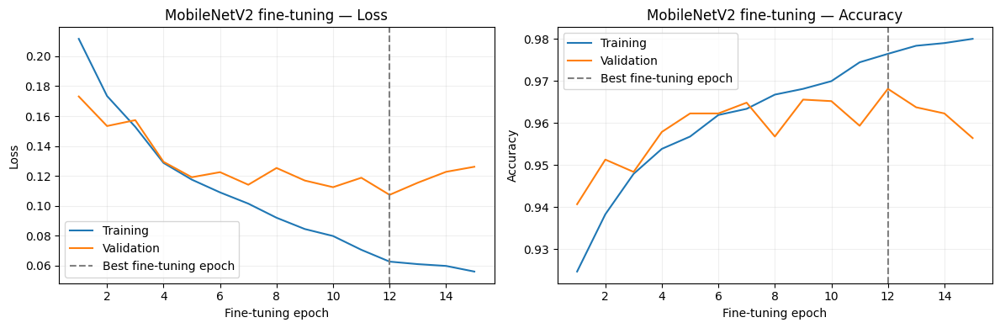

Fine-tuning improved validation loss.
Frozen-base checkpoint: /kaggle/working/transfer_learning/best_mobilenetv2_head.keras
Fine-tuned checkpoint: /kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras
The test set has not been used.


In [41]:
# Fine-tune the later MobileNetV2 layers while preserving the frozen-base model.
from pathlib import Path
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

transfer_dir = Path("/kaggle/working/transfer_learning")
head_checkpoint = transfer_dir / "best_mobilenetv2_head.keras"
fine_checkpoint = transfer_dir / "best_mobilenetv2_finetuned.keras"

if not head_checkpoint.is_file():
    raise FileNotFoundError(
        f"The trained classification-head checkpoint is missing: "
        f"{head_checkpoint}"
    )

# Start from the best completed frozen-base model.
fine_model = tf.keras.models.load_model(
    str(head_checkpoint),
    compile=False,
)

# Find the feature extractor inside the restored model.
base_candidates = [
    layer for layer in fine_model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
]

if len(base_candidates) != 1:
    raise ValueError("Could not uniquely identify the MobileNetV2 base.")

fine_base = base_candidates[0]

# Adapt blocks 13 onward while keeping earlier features unchanged.
start_layer = "block_13_expand"
base_layer_names = [layer.name for layer in fine_base.layers]

if start_layer not in base_layer_names:
    raise ValueError(f"Fine-tuning start layer not found: {start_layer}")

fine_base.trainable = True
unfreeze = False

for layer in fine_base.layers:
    if layer.name == start_layer:
        unfreeze = True

    layer.trainable = (
        unfreeze
        and not isinstance(layer, tf.keras.layers.BatchNormalization)
    )

# Recompile after changing which weights can be trained.
# The restored model retains the base call with training=False,
# keeping batch-normalization statistics in inference mode.
fine_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

trainable_parameters = sum(
    int(np.prod(weight.shape))
    for weight in fine_model.trainable_weights
)

print("Fine-tuning from:", start_layer)
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Learning rate: 0.00001")

print("\nMeasuring validation performance before fine-tuning...")
before_finetuning = fine_model.evaluate(
    cnn_validation_ds,
    return_dict=True,
    verbose=1,
)

fine_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(fine_checkpoint),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(transfer_dir / "finetuning_log.csv")
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

print("\nStarting fine-tuning on all training batches...", flush=True)
start_time = perf_counter()

fine_history = fine_model.fit(
    cnn_train_ds,
    validation_data=cnn_validation_ds,
    epochs=15,
    callbacks=fine_callbacks,
    verbose=1,
)

finetuning_seconds = perf_counter() - start_time

# Save the history of this additional training stage.
fine_history_df = pd.DataFrame(fine_history.history)
fine_history_df.insert(
    0, "epoch", range(1, len(fine_history_df) + 1)
)
fine_history_df.to_csv(
    transfer_dir / "finetuning_history.csv",
    index=False,
)

if not np.isfinite(fine_history_df["val_loss"]).any():
    raise RuntimeError(
        "Fine-tuning produced no finite validation loss. "
        "The original frozen-base checkpoint is still available."
    )

# Restore the best checkpoint from the fine-tuning stage.
fine_model = tf.keras.models.load_model(
    str(fine_checkpoint)
)

best_fine_row = fine_history_df.loc[
    fine_history_df["val_loss"].idxmin()
]
best_fine_epoch = int(best_fine_row["epoch"])

print(f"\nFine-tuning time: {finetuning_seconds / 60:.1f} minutes")
print("Best fine-tuning epoch:", best_fine_epoch)

comparison = pd.DataFrame([
    {
        "Stage": "Before fine-tuning",
        "Validation accuracy": before_finetuning["accuracy"],
        "Validation loss": before_finetuning["loss"],
    },
    {
        "Stage": "Best fine-tuning epoch",
        "Validation accuracy": best_fine_row["val_accuracy"],
        "Validation loss": best_fine_row["val_loss"],
    },
])

print("\nStage comparison:")
print(comparison.round(4).to_string(index=False))
comparison.to_csv(
    transfer_dir / "finetuning_stage_comparison.csv",
    index=False,
)

# Record timing and settings for later comparison and reproducibility.
metadata = {
    "unfreeze_from": start_layer,
    "learning_rate": 1e-5,
    "maximum_epochs": 15,
    "completed_epochs": len(fine_history_df),
    "best_epoch": best_fine_epoch,
    "trainable_parameters": trainable_parameters,
    "finetuning_seconds": finetuning_seconds,
}

if "transfer_training_seconds" in globals():
    metadata["head_training_seconds"] = float(
        transfer_training_seconds
    )
    metadata["total_training_seconds"] = (
        float(transfer_training_seconds) + finetuning_seconds
    )

(transfer_dir / "finetuning_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

# Plot only the additional fine-tuning epochs.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title, ylabel in [
    (axes[0], "loss", "MobileNetV2 fine-tuning — Loss", "Loss"),
    (axes[1], "accuracy", "MobileNetV2 fine-tuning — Accuracy", "Accuracy"),
]:
    ax.plot(
        fine_history_df["epoch"],
        fine_history_df[metric],
        label="Training",
    )
    ax.plot(
        fine_history_df["epoch"],
        fine_history_df[f"val_{metric}"],
        label="Validation",
    )
    ax.axvline(
        best_fine_epoch,
        color="gray",
        linestyle="--",
        label="Best fine-tuning epoch",
    )
    ax.set(title=title, xlabel="Fine-tuning epoch", ylabel=ylabel)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    transfer_dir / "finetuning_learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

if best_fine_row["val_loss"] < before_finetuning["loss"]:
    print("Fine-tuning improved validation loss.")
else:
    print(
        "Fine-tuning did not improve validation loss. "
        "Keep the frozen-base model as a candidate."
    )

print("Frozen-base checkpoint:", head_checkpoint)
print("Fine-tuned checkpoint:", fine_checkpoint)
print("The test set has not been used.")

Predicting training images...
342/342 ━━━━━━━━━━━━━━━━━━━━ 52s 149ms/step
Predicting validation images...
86/86 ━━━━━━━━━━━━━━━━━━━━ 13s 149ms/step

Fine-tuned MobileNetV2 metrics:


,Set,Accuracy,Macro precision,Macro recall,Macro F1
0,Training,0.9880,0.9874,0.9890,0.9882
1,Validation,0.9682,0.9667,0.9667,0.9667



Validation classification report:

              precision    recall  f1-score   support

    basophil     0.9643    0.9742    0.9692       194
  eosinophil     0.9920    0.9980    0.9950       498
erythroblast     0.9794    0.9597    0.9695       248
          ig     0.9330    0.9330    0.9330       463
  lymphocyte     0.9541    0.9639    0.9590       194
    monocyte     0.9511    0.9427    0.9469       227
  neutrophil     0.9679    0.9643    0.9661       532
    platelet     0.9921    0.9973    0.9947       376

    accuracy                         0.9682      2732
   macro avg     0.9667    0.9667    0.9667      2732
weighted avg     0.9681    0.9682    0.9681      2732



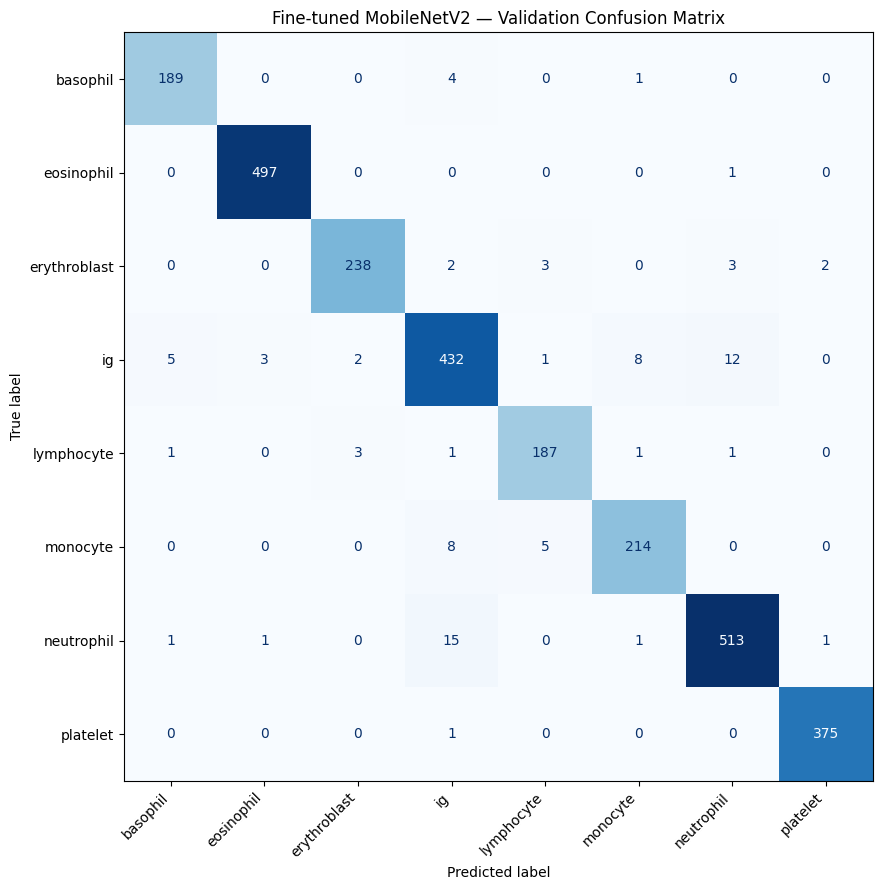

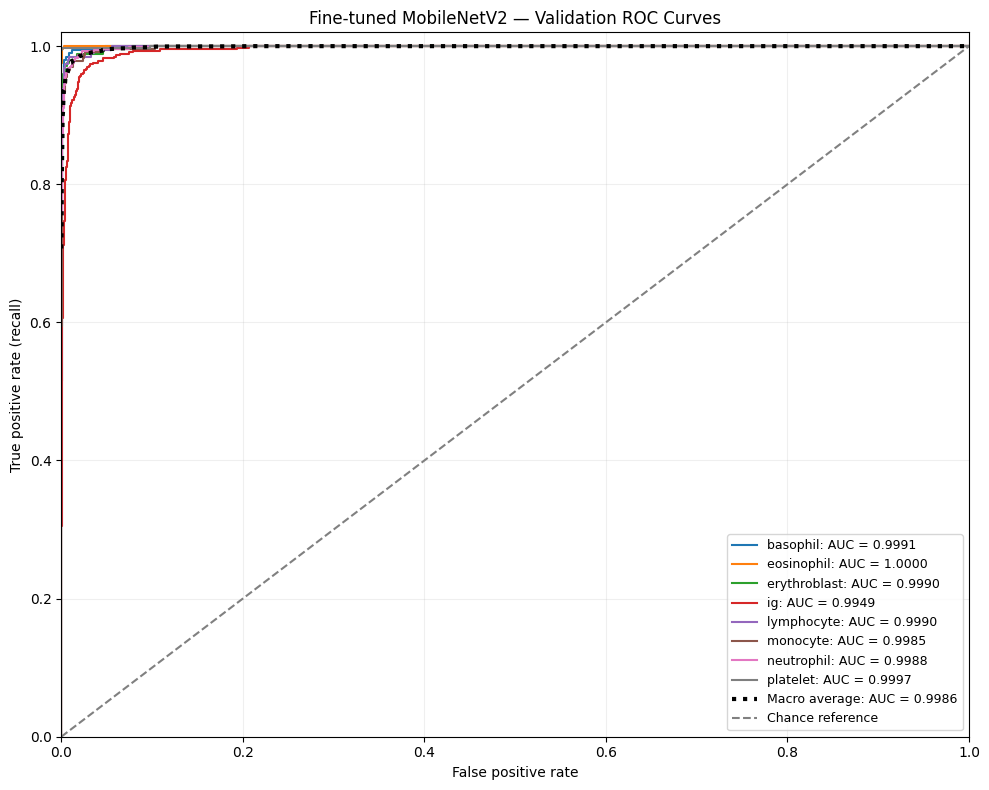


Updated comparison, ranked by validation macro F1:


,Model,Features,Validation accuracy,Validation macro precision,Validation macro recall,Validation macro F1,Validation macro AUC,Training seconds
0,MobileNetV2 — fine-tuned,128×128 RGB pixels,0.9682,0.9667,0.9667,0.9667,0.9986,3190.8532
1,XGBoost,300,0.9480,0.9501,0.9397,0.9445,0.9969,19.7198
2,Small 2D CNN,128×128 RGB pixels,0.9458,0.9483,0.9388,0.9432,0.9970,1808.8622
3,MobileNetV2 — frozen base,128×128 RGB pixels,0.9396,0.9375,0.9329,0.9351,0.9967,1760.4727
4,SVM — Polynomial degree 3,300,0.9250,0.9232,0.9139,0.9181,0.9857,2.9412
5,Bagging — Decision Trees,300,0.9206,0.9155,0.9079,0.9111,0.9930,192.1230
6,SVM — RBF,300,0.9140,0.9107,0.9004,0.9051,0.9837,3.9808
7,Random Forest,300,0.9081,0.9149,0.8907,0.9001,0.9925,13.2109
8,"MLP — 128, 64",300,0.9063,0.9063,0.8912,0.8978,0.9918,4.3353
9,SVM — Linear,300,0.9030,0.8975,0.8939,0.8954,0.9845,6.6816



Correct validation predictions: 2645/2732
Validation accuracy: 96.82%
Validation macro F1: 0.9667
Validation macro AUC: 0.9986
Results saved to: /kaggle/working/transfer_learning
The test set has not been used.


In [42]:
# Evaluate the fine-tuned MobileNetV2 checkpoint and save its comparison results.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
)

transfer_dir = Path("/kaggle/working/transfer_learning")
fine_checkpoint = transfer_dir / "best_mobilenetv2_finetuned.keras"

if not fine_checkpoint.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {fine_checkpoint}")

fine_model = tf.keras.models.load_model(
    str(fine_checkpoint),
    compile=False,
)

classes = np.asarray(cnn_class_names)

if fine_model.output_shape[-1] != len(classes):
    raise ValueError("Model outputs do not match the category mapping.")

# Keep predictions aligned with the original dataframe row order.
train_eval_ds = make_cnn_dataset(train_df, training=False)
val_eval_ds = make_cnn_dataset(validation_df, training=False)

print("Predicting training images...", flush=True)
fine_train_probs = fine_model.predict(train_eval_ds, verbose=1)

print("Predicting validation images...", flush=True)
fine_val_probs = fine_model.predict(val_eval_ds, verbose=1)

train_true = train_df["label"].to_numpy()
val_true = validation_df["label"].to_numpy()

for name, probabilities, labels in [
    ("Training", fine_train_probs, train_true),
    ("Validation", fine_val_probs, val_true),
]:
    if probabilities.shape != (len(labels), len(classes)):
        raise ValueError(f"{name} prediction dimensions are incorrect.")
    if not np.isfinite(probabilities).all():
        raise ValueError(f"{name} predictions contain non-finite values.")
    if not np.isin(labels, classes).all():
        raise ValueError(f"{name} contains an unknown category.")

fine_train_pred = classes[np.argmax(fine_train_probs, axis=1)]
fine_val_pred = classes[np.argmax(fine_val_probs, axis=1)]

# Measure the saved model under inference conditions.
metric_rows = []

for name, true, predicted in [
    ("Training", train_true, fine_train_pred),
    ("Validation", val_true, fine_val_pred),
]:
    metric_rows.append({
        "Set": name,
        "Accuracy": accuracy_score(true, predicted),
        "Macro precision": precision_score(
            true, predicted, labels=classes,
            average="macro", zero_division=0,
        ),
        "Macro recall": recall_score(
            true, predicted, labels=classes,
            average="macro", zero_division=0,
        ),
        "Macro F1": f1_score(
            true, predicted, labels=classes,
            average="macro", zero_division=0,
        ),
    })

fine_metrics = pd.DataFrame(metric_rows)
print("\nFine-tuned MobileNetV2 metrics:")
display(fine_metrics.round(4))

fine_metrics.to_csv(
    transfer_dir / "finetuned_training_validation_metrics.csv",
    index=False,
)

# Print and save the per-category report.
report = classification_report(
    val_true,
    fine_val_pred,
    labels=classes,
    target_names=classes.tolist(),
    digits=4,
    zero_division=0,
)

print("\nValidation classification report:\n")
print(report)

(transfer_dir / "finetuned_classification_report.txt").write_text(
    report,
    encoding="utf-8",
)

# Save the confusion matrix as both a table and a figure.
cm = confusion_matrix(val_true, fine_val_pred, labels=classes)

pd.DataFrame(
    cm,
    index=pd.Index(classes, name="True label"),
    columns=pd.Index(classes, name="Predicted label"),
).to_csv(transfer_dir / "finetuned_confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("Fine-tuned MobileNetV2 — Validation Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    transfer_dir / "finetuned_validation_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Calculate one-versus-rest ROC curves and category AUC values.
roc_data = {}
auc_rows = []

for index, category in enumerate(classes):
    binary_true = (val_true == category).astype(int)

    if np.unique(binary_true).size != 2:
        raise ValueError(
            f"ROC needs positive and negative examples for {category}."
        )

    fpr, tpr, _ = roc_curve(binary_true, fine_val_probs[:, index])
    category_auc = auc(fpr, tpr)

    roc_data[category] = (fpr, tpr)
    auc_rows.append({
        "Category": category,
        "AUC": category_auc,
    })

fine_auc_table = pd.DataFrame(auc_rows)
fine_macro_auc = float(fine_auc_table["AUC"].mean())

fine_auc_table.to_csv(
    transfer_dir / "finetuned_validation_auc.csv",
    index=False,
)

shared_fpr = np.unique(np.concatenate([
    fpr for fpr, _ in roc_data.values()
]))
macro_tpr = np.mean([
    np.interp(shared_fpr, fpr, tpr)
    for fpr, tpr in roc_data.values()
], axis=0)

fig, ax = plt.subplots(figsize=(10, 8))

for row in auc_rows:
    fpr, tpr = roc_data[row["Category"]]
    ax.plot(
        fpr, tpr,
        label=f"{row['Category']}: AUC = {row['AUC']:.4f}",
    )

ax.plot(
    shared_fpr,
    macro_tpr,
    color="black",
    linestyle=":",
    linewidth=3,
    label=f"Macro average: AUC = {fine_macro_auc:.4f}",
)
ax.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    label="Chance reference",
)
ax.set(
    title="Fine-tuned MobileNetV2 — Validation ROC Curves",
    xlabel="False positive rate",
    ylabel="True positive rate (recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    transfer_dir / "finetuned_validation_roc.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Save predictions and an error-only table for later image inspection.
predictions = validation_df[["filepath", "label"]].copy()
predictions = predictions.rename(columns={"label": "True label"})
predictions["Predicted label"] = fine_val_pred
predictions["Correct"] = val_true == fine_val_pred
predictions["Highest predicted probability"] = fine_val_probs.max(axis=1)

for index, category in enumerate(classes):
    predictions[f"Probability {category}"] = fine_val_probs[:, index]

predictions.to_csv(
    transfer_dir / "finetuned_validation_predictions.csv",
    index=False,
)
predictions.loc[~predictions["Correct"]].to_csv(
    transfer_dir / "finetuned_validation_errors.csv",
    index=False,
)

# Include both training stages in the fine-tuned model's training time.
metadata_path = transfer_dir / "finetuning_metadata.json"
metadata = (
    json.loads(metadata_path.read_text(encoding="utf-8"))
    if metadata_path.is_file() else {}
)

total_seconds = metadata.get("total_training_seconds", np.nan)

if pd.isna(total_seconds):
    head_seconds = metadata.get(
        "head_training_seconds",
        globals().get("transfer_training_seconds", np.nan),
    )
    fine_seconds = metadata.get(
        "finetuning_seconds",
        globals().get("finetuning_seconds", np.nan),
    )
    if pd.notna(head_seconds) and pd.notna(fine_seconds):
        total_seconds = float(head_seconds) + float(fine_seconds)

validation_metrics = fine_metrics.set_index("Set").loc["Validation"]

fine_result = {
    "Model": "MobileNetV2 — fine-tuned",
    "Features": "128×128 RGB pixels",
    "Validation accuracy": validation_metrics["Accuracy"],
    "Validation macro precision": validation_metrics["Macro precision"],
    "Validation macro recall": validation_metrics["Macro recall"],
    "Validation macro F1": validation_metrics["Macro F1"],
    "Validation macro AUC": fine_macro_auc,
    "Training seconds": total_seconds,
}

pd.DataFrame([fine_result]).to_csv(
    transfer_dir / "finetuned_model_summary.csv",
    index=False,
)

# Recover the previous comparison if it is not currently in memory.
previous_comparison = (
    transfer_dir / "model_comparison_with_mobilenetv2.csv"
)

if (
    "baseline_comparison" not in globals()
    and previous_comparison.is_file()
):
    baseline_comparison = pd.read_csv(previous_comparison)

if "baseline_comparison" in globals():
    baseline_comparison = baseline_comparison.loc[
        baseline_comparison["Model"] != fine_result["Model"]
    ].copy()

    baseline_comparison = pd.concat(
        [baseline_comparison, pd.DataFrame([fine_result])],
        ignore_index=True,
    ).sort_values(
        "Validation macro F1",
        ascending=False,
    ).reset_index(drop=True)

    print("\nUpdated comparison, ranked by validation macro F1:")
    display(baseline_comparison.round(4))

    baseline_comparison.to_csv(
        transfer_dir / "model_comparison_with_finetuning.csv",
        index=False,
    )

correct = int(np.trace(cm))
print(f"\nCorrect validation predictions: {correct}/{len(val_true)}")
print(f"Validation accuracy: {validation_metrics['Accuracy']:.2%}")
print(f"Validation macro F1: {validation_metrics['Macro F1']:.4f}")
print(f"Validation macro AUC: {fine_macro_auc:.4f}")
print("Results saved to:", transfer_dir)
print("The test set has not been used.")

Raw training features: (10927, 1828)
Total model fits: 40
Validation and test sets are not used.

[1/40] XGBoost | features=100 | fold=1/5
  Accuracy=0.9396 | Macro F1=0.9370 | Fit=6.4s
[2/40] XGBoost | features=100 | fold=2/5
  Accuracy=0.9364 | Macro F1=0.9306 | Fit=6.4s
[3/40] XGBoost | features=100 | fold=3/5
  Accuracy=0.9423 | Macro F1=0.9376 | Fit=6.3s
[4/40] XGBoost | features=100 | fold=4/5
  Accuracy=0.9291 | Macro F1=0.9253 | Fit=6.4s
[5/40] XGBoost | features=100 | fold=5/5
  Accuracy=0.9341 | Macro F1=0.9290 | Fit=6.3s
[6/40] XGBoost | features=300 | fold=1/5
  Accuracy=0.9355 | Macro F1=0.9337 | Fit=18.3s
[7/40] XGBoost | features=300 | fold=2/5
  Accuracy=0.9414 | Macro F1=0.9373 | Fit=18.5s
[8/40] XGBoost | features=300 | fold=3/5
  Accuracy=0.9497 | Macro F1=0.9468 | Fit=18.6s
[9/40] XGBoost | features=300 | fold=4/5
  Accuracy=0.9387 | Macro F1=0.9365 | Fit=18.6s
[10/40] XGBoost | features=300 | fold=5/5
  Accuracy=0.9419 | Macro F1=0.9384 | Fit=18.5s
[11/40] XGBoost 

,Model,Feature setting,Mean_accuracy,SD_accuracy,Mean_macro_precision,Mean_macro_recall,Mean_macro_F1,SD_macro_F1,Mean_fit_seconds
2,XGBoost,600,0.9467,0.0071,0.9496,0.9409,0.9450,0.0067,35.5598
3,XGBoost,all,0.9447,0.0048,0.9479,0.9387,0.9430,0.0044,136.4044
1,XGBoost,300,0.9414,0.0053,0.9431,0.9347,0.9385,0.0049,18.4975
0,XGBoost,100,0.9363,0.0051,0.9372,0.9274,0.9319,0.0053,6.3578
5,Polynomial SVM,300,0.9200,0.0016,0.9171,0.9105,0.9134,0.0012,2.5192
4,Polynomial SVM,100,0.9214,0.0051,0.9168,0.9104,0.9132,0.0072,1.1539
6,Polynomial SVM,600,0.9176,0.0018,0.9140,0.9070,0.9102,0.0025,5.5880
7,Polynomial SVM,all,0.8754,0.0021,0.8716,0.8537,0.8615,0.0035,58.8167



Highest mean CV macro F1 for each model:


,Model,Feature setting,Mean_accuracy,SD_accuracy,Mean_macro_precision,Mean_macro_recall,Mean_macro_F1,SD_macro_F1,Mean_fit_seconds
0,XGBoost,600,0.9467,0.0071,0.9496,0.9409,0.9450,0.0067,35.5598
1,Polynomial SVM,300,0.9200,0.0016,0.9171,0.9105,0.9134,0.0012,2.5192


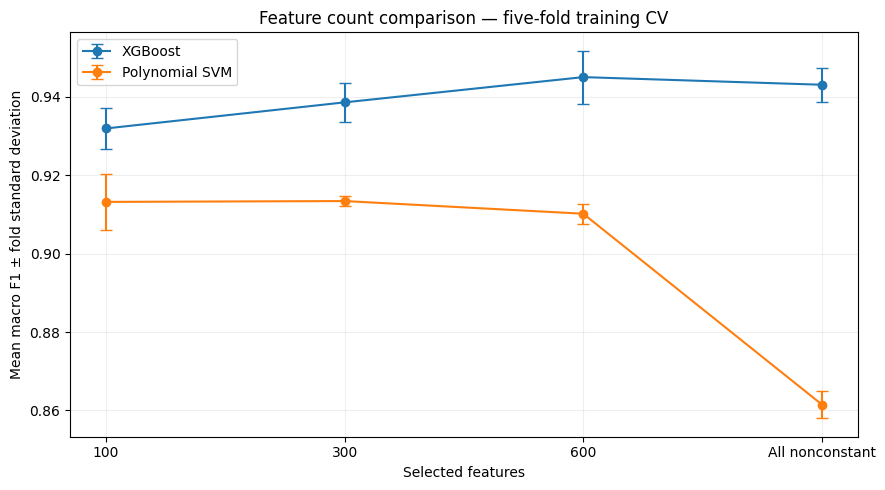


Experiment time: 23.4 minutes
Results saved to: /kaggle/working/cross_validation


In [43]:
# Compare feature counts with training-only five-fold cross-validation.
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.svm import SVC
from xgboost import XGBClassifier

cv_dir = Path("/kaggle/working/cross_validation")
cv_dir.mkdir(parents=True, exist_ok=True)

# Use raw extracted features, not X_train_scaled or X_train_selected.
X_feature_cv = np.asarray(X_train, dtype=np.float64)
y_feature_text = np.asarray(y_train)

if X_feature_cv.ndim != 2:
    raise ValueError("X_train must be a two-dimensional feature table.")

if X_feature_cv.shape[1] != len(feature_names):
    raise ValueError(
        "X_train does not match the original feature list. "
        "Use the raw feature table from feature extraction."
    )

if len(X_feature_cv) != len(y_feature_text):
    raise ValueError("Feature rows and training labels do not match.")

if not np.isfinite(X_feature_cv).all():
    raise ValueError("The feature table contains missing or infinite values.")

# Confirm that labels remain aligned with the training inventory.
if not np.array_equal(
    y_feature_text,
    train_df["label"].to_numpy(),
):
    raise ValueError("Training labels are not aligned with train_df.")

# XGBoost requires numeric category IDs.
feature_cv_encoder = LabelEncoder()
y_feature_cv = feature_cv_encoder.fit_transform(y_feature_text)

pd.DataFrame({
    "Label ID": np.arange(len(feature_cv_encoder.classes_)),
    "Category": feature_cv_encoder.classes_,
}).to_csv(cv_dir / "category_mapping.csv", index=False)

# Keep baseline settings fixed so this experiment varies feature count.
feature_cv_models = {
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=len(feature_cv_encoder.classes_),
        n_estimators=200,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        tree_method="hist",
        eval_metric="mlogloss",
        n_jobs=2,
        random_state=SEED,
    ),
    "Polynomial SVM": SVC(
        kernel="poly",
        degree=3,
        C=1,
        gamma="scale",
        coef0=1,
        probability=False,
        decision_function_shape="ovr",
        random_state=SEED,
    ),
}

feature_counts = [100, 300, 600, "all"]

# Reuse exactly the same folds for every candidate.
splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)
feature_cv_splits = list(
    splitter.split(X_feature_cv, y_feature_cv)
)

fold_assignment = np.zeros(len(y_feature_cv), dtype=int)
for fold_number, (_, heldout_indices) in enumerate(
    feature_cv_splits, start=1
):
    fold_assignment[heldout_indices] = fold_number

fold_inventory = train_df[["filepath", "label"]].copy()
fold_inventory["CV fold"] = fold_assignment
fold_inventory.to_csv(
    cv_dir / "training_fold_assignments.csv",
    index=False,
)

fold_results = []
oof_tables = []
total_fits = len(feature_cv_models) * len(feature_counts) * 5
completed = 0
experiment_start = perf_counter()

print("Raw training features:", X_feature_cv.shape)
print("Total model fits:", total_fits)
print("Validation and test sets are not used.\n", flush=True)

for model_name, estimator in feature_cv_models.items():
    for feature_count in feature_counts:
        feature_label = str(feature_count)
        oof_predictions = np.full(
            len(y_feature_cv), -1, dtype=int
        )

        for fold_number, (fit_indices, heldout_indices) in enumerate(
            feature_cv_splits, start=1
        ):
            print(
                f"[{completed + 1}/{total_fits}] "
                f"{model_name} | features={feature_label} "
                f"| fold={fold_number}/5",
                flush=True,
            )

            # Every preprocessing step is fitted only on this fold's
            # training portion.
            pipeline = Pipeline([
                ("scale", StandardScaler()),
                ("remove_constant", VarianceThreshold(0)),
                ("select", SelectKBest(
                    score_func=f_classif,
                    k=feature_count,
                )),
                ("model", clone(estimator)),
            ])

            start = perf_counter()
            pipeline.fit(
                X_feature_cv[fit_indices],
                y_feature_cv[fit_indices],
            )
            fit_seconds = perf_counter() - start

            start = perf_counter()
            predicted = pipeline.predict(
                X_feature_cv[heldout_indices]
            ).astype(int)
            predict_seconds = perf_counter() - start

            true = y_feature_cv[heldout_indices]
            oof_predictions[heldout_indices] = predicted

            row = {
                "Model": model_name,
                "Feature setting": feature_label,
                "Fold": fold_number,
                "Features used": int(
                    pipeline.named_steps["select"]
                    .get_support().sum()
                ),
                "Accuracy": accuracy_score(true, predicted),
                "Macro precision": precision_score(
                    true, predicted,
                    average="macro", zero_division=0,
                ),
                "Macro recall": recall_score(
                    true, predicted,
                    average="macro", zero_division=0,
                ),
                "Macro F1": f1_score(
                    true, predicted,
                    average="macro", zero_division=0,
                ),
                "Fit seconds": fit_seconds,
                "Predict seconds": predict_seconds,
            }
            fold_results.append(row)
            completed += 1

            # Save after every fold so completed measurements are retained.
            pd.DataFrame(fold_results).to_csv(
                cv_dir / "feature_count_fold_results.csv",
                index=False,
            )

            print(
                f"  Accuracy={row['Accuracy']:.4f} | "
                f"Macro F1={row['Macro F1']:.4f} | "
                f"Fit={fit_seconds:.1f}s",
                flush=True,
            )

        # Each image receives a prediction from a model that did not
        # train on that image.
        if (oof_predictions < 0).any():
            raise RuntimeError("Some out-of-fold predictions are missing.")

        candidate_oof = train_df[["filepath", "label"]].copy()
        candidate_oof["Model"] = model_name
        candidate_oof["Feature setting"] = feature_label
        candidate_oof["CV fold"] = fold_assignment
        candidate_oof["Predicted label"] = (
            feature_cv_encoder.inverse_transform(oof_predictions)
        )
        oof_tables.append(candidate_oof)

        pd.concat(oof_tables, ignore_index=True).to_csv(
            cv_dir / "feature_count_oof_predictions.csv",
            index=False,
        )

feature_cv_fold_results = pd.DataFrame(fold_results)

feature_cv_summary = (
    feature_cv_fold_results
    .groupby(["Model", "Feature setting"], sort=False)
    .agg(
        Mean_accuracy=("Accuracy", "mean"),
        SD_accuracy=("Accuracy", "std"),
        Mean_macro_precision=("Macro precision", "mean"),
        Mean_macro_recall=("Macro recall", "mean"),
        Mean_macro_F1=("Macro F1", "mean"),
        SD_macro_F1=("Macro F1", "std"),
        Mean_fit_seconds=("Fit seconds", "mean"),
    )
    .reset_index()
    .sort_values("Mean_macro_F1", ascending=False)
)

feature_cv_summary.to_csv(
    cv_dir / "feature_count_summary.csv",
    index=False,
)

print("\nFeature-count comparison:")
display(feature_cv_summary.round(4))

best_feature_counts = (
    feature_cv_summary
    .drop_duplicates("Model")
    .reset_index(drop=True)
)
best_feature_counts.to_csv(
    cv_dir / "best_feature_count_per_model.csv",
    index=False,
)

print("\nHighest mean CV macro F1 for each model:")
display(best_feature_counts.round(4))

# Error bars show variability across folds, not confidence intervals.
fig, ax = plt.subplots(figsize=(9, 5))
feature_order = ["100", "300", "600", "all"]
positions = np.arange(len(feature_order))

for model_name in feature_cv_models:
    subset = (
        feature_cv_summary[
            feature_cv_summary["Model"] == model_name
        ]
        .set_index("Feature setting")
        .loc[feature_order]
    )

    ax.errorbar(
        positions,
        subset["Mean_macro_F1"],
        yerr=subset["SD_macro_F1"],
        marker="o",
        capsize=4,?
        label=model_name,
    )

ax.set_xticks(positions)
ax.set_xticklabels(["100", "300", "600", "All nonconstant"])
ax.set(
    title="Feature count comparison — five-fold training CV",
    xlabel="Selected features",
    ylabel="Mean macro F1 ± fold standard deviation",
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    cv_dir / "feature_count_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print(
    f"\nExperiment time: "
    f"{(perf_counter() - experiment_start) / 60:.1f} minutes"
)
print("Results saved to:", cv_dir)

In [45]:
# Bundle the current project files into one backup without retraining.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

working_dir = Path("/kaggle/working")
backup_path = working_dir / "blood_cell_project_backup.zip"

folders = [
    "data_checks",
    "splits",
    "features",
    "results",
    "models",
    "cnn",
    "transfer_learning",
    "cross_validation",
    "hyperparameter_tuning",
]

with ZipFile(backup_path, "w", compression=ZIP_DEFLATED) as backup:
    for folder_name in folders:
        folder = working_dir / folder_name
        if not folder.is_dir():
            print(f"Not present: {folder_name}", flush=True)
            continue

        count = 0
        for filepath in folder.rglob("*"):
            if filepath.is_file():
                backup.write(
                    filepath,
                    arcname=str(filepath.relative_to(working_dir)),
                )
                count += 1

        print(f"Included {folder_name}: {count} files", flush=True)

print(f"\nBackup created: {backup_path}")
print(f"Size: {backup_path.stat().st_size / 1024**2:.1f} MB")

Included data_checks: 8 files
Included splits: 5 files
Included features: 4 files
Included results: 54 files
Included models: 13 files
Included cnn: 3 files
Included transfer_learning: 28 files
Included cross_validation: 7 files
Not present: hyperparameter_tuning

Backup created: /kaggle/working/blood_cell_project_backup.zip
Size: 199.7 MB


Predicting 3,415 held-out test images...
107/107 ━━━━━━━━━━━━━━━━━━━━ 16s 144ms/step

Final held-out test results:


,Model,Set,Images,Correct,Accuracy,Macro precision,Macro recall,Macro F1,Macro AUC
0,MobileNetV2 fine-tuned,Test,3415,3275,0.959,0.9579,0.9565,0.9572,0.9982



Test classification report:

              precision    recall  f1-score   support

    basophil     0.9588    0.9628    0.9608       242
  eosinophil     0.9873    0.9968    0.9920       622
erythroblast     0.9603    0.9355    0.9477       310
          ig     0.9014    0.9170    0.9091       578
  lymphocyte     0.9673    0.9753    0.9713       243
    monocyte     0.9250    0.9120    0.9184       284
  neutrophil     0.9697    0.9595    0.9645       666
    platelet     0.9936    0.9936    0.9936       470

    accuracy                         0.9590      3415
   macro avg     0.9579    0.9565    0.9572      3415
weighted avg     0.9591    0.9590    0.9590      3415



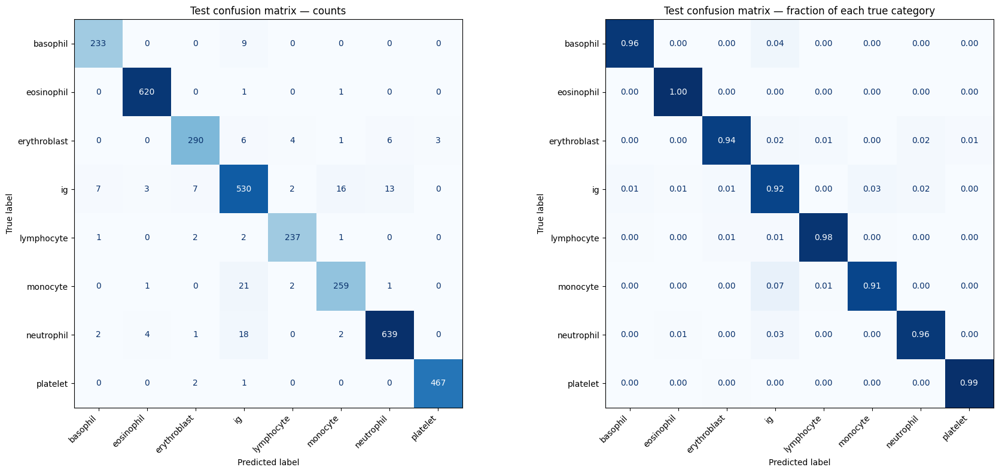

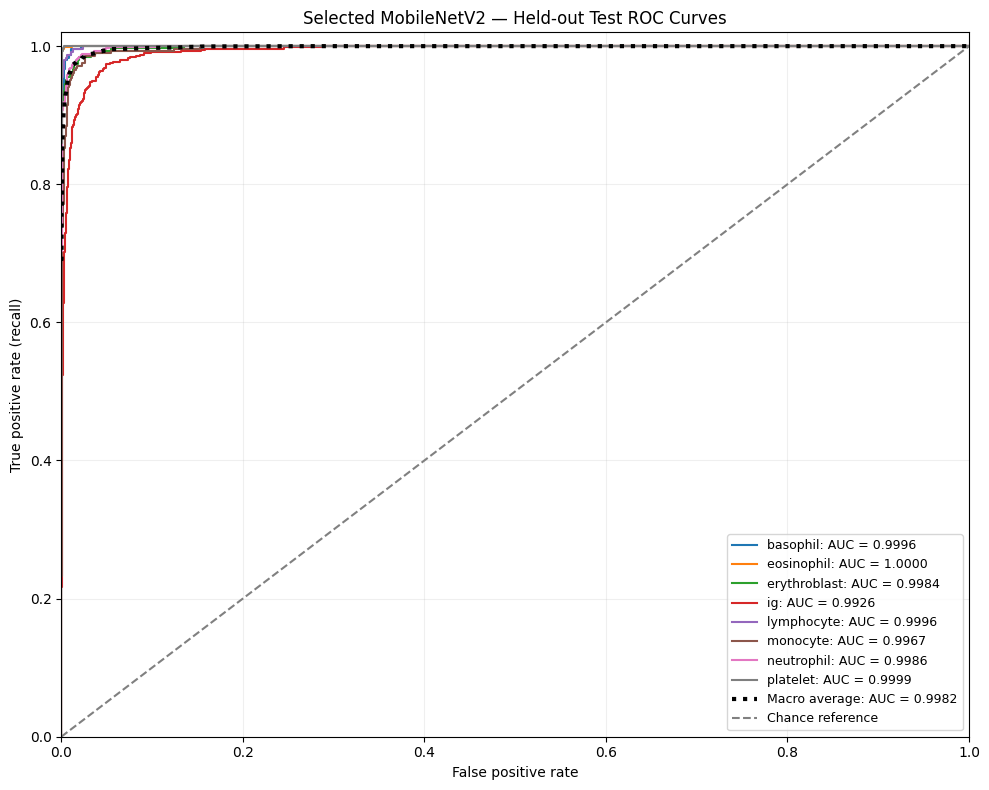

Final test evaluation completed.
Results saved to: /kaggle/working/final_evaluation
Keep model settings fixed after reviewing these test results.


In [46]:
# Evaluate the selected fine-tuned MobileNetV2 on the held-out test set.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
)

final_dir = Path("/kaggle/working/final_evaluation")
final_dir.mkdir(parents=True, exist_ok=True)

checkpoint = Path(
    "/kaggle/working/transfer_learning/"
    "best_mobilenetv2_finetuned.keras"
)
metrics_path = final_dir / "test_metrics.csv"
completed_path = final_dir / "evaluation_complete.json"

if completed_path.is_file():
    print("Final test evaluation was already completed.")
    print("Displaying saved results without running predictions again.")
    display(pd.read_csv(metrics_path).round(4))
    print(
        (final_dir / "test_classification_report.txt")
        .read_text(encoding="utf-8")
    )

else:
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Model checkpoint missing: {checkpoint}")

    required = [
        "test_df", "train_df", "validation_df",
        "cnn_class_names", "make_cnn_dataset",
    ]
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError(
            "Restore the dataset setup before running this cell. "
            f"Missing variables: {missing}. No retraining is required."
        )

    # Check the split boundaries before evaluating.
    for column in ["filepath", "pixel_hash"]:
        if all(
            column in table.columns
            for table in [test_df, train_df, validation_df]
        ):
            test_values = set(test_df[column])
            development_values = (
                set(train_df[column]) | set(validation_df[column])
            )
            if test_values & development_values:
                raise ValueError(
                    f"Test/development overlap detected in {column}."
                )

    classes = np.asarray(cnn_class_names)
    test_true = test_df["label"].to_numpy()

    if not np.isin(test_true, classes).all():
        raise ValueError("The test set contains an unknown category.")

    if not test_df["filepath"].is_unique:
        raise ValueError("The test inventory contains duplicate paths.")

    # Record the model choice before inspecting test predictions.
    checkpoint_hash = hashlib.sha256()
    with checkpoint.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            checkpoint_hash.update(chunk)

    selection = {
        "model": "MobileNetV2 fine-tuned",
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": checkpoint_hash.hexdigest(),
        "selection_basis": "Highest observed validation macro F1",
        "validation_accuracy": 0.9645,
        "validation_macro_f1": 0.9620,
        "classes": classes.tolist(),
        "test_images": len(test_df),
        "retrained_on_full_development_set": False,
    }
    (final_dir / "model_selection.json").write_text(
        json.dumps(selection, indent=2),
        encoding="utf-8",
    )

    final_model = tf.keras.models.load_model(
        str(checkpoint),
        compile=False,
    )

    if final_model.output_shape[-1] != len(classes):
        raise ValueError("Model outputs do not match the category mapping.")

    # Preserve dataframe order so labels and predictions stay aligned.
    test_ds = make_cnn_dataset(test_df, training=False)

    print(f"Predicting {len(test_df):,} held-out test images...", flush=True)
    test_probs = final_model.predict(test_ds, verbose=1)

    if test_probs.shape != (len(test_df), len(classes)):
        raise ValueError("Unexpected prediction dimensions.")
    if not np.isfinite(test_probs).all():
        raise ValueError("Predictions contain non-finite values.")

    test_pred = classes[np.argmax(test_probs, axis=1)]

    # Calculate one-versus-rest ROC curves for all categories.
    roc_data = {}
    auc_rows = []

    for index, category in enumerate(classes):
        binary_true = (test_true == category).astype(int)
        if np.unique(binary_true).size != 2:
            raise ValueError(f"Cannot calculate ROC for {category}.")

        fpr, tpr, _ = roc_curve(binary_true, test_probs[:, index])
        category_auc = auc(fpr, tpr)
        roc_data[category] = (fpr, tpr)
        auc_rows.append({
            "Category": category,
            "AUC": category_auc,
        })

    auc_table = pd.DataFrame(auc_rows)
    macro_auc = float(auc_table["AUC"].mean())

    test_metrics = pd.DataFrame([{
        "Model": "MobileNetV2 fine-tuned",
        "Set": "Test",
        "Images": len(test_true),
        "Correct": int((test_true == test_pred).sum()),
        "Accuracy": accuracy_score(test_true, test_pred),
        "Macro precision": precision_score(
            test_true, test_pred, labels=classes,
            average="macro", zero_division=0,
        ),
        "Macro recall": recall_score(
            test_true, test_pred, labels=classes,
            average="macro", zero_division=0,
        ),
        "Macro F1": f1_score(
            test_true, test_pred, labels=classes,
            average="macro", zero_division=0,
        ),
        "Macro AUC": macro_auc,
    }])

    test_metrics.to_csv(metrics_path, index=False)
    auc_table.to_csv(final_dir / "test_auc.csv", index=False)

    print("\nFinal held-out test results:")
    display(test_metrics.round(4))

    report = classification_report(
        test_true,
        test_pred,
        labels=classes,
        target_names=classes.tolist(),
        digits=4,
        zero_division=0,
    )
    print("\nTest classification report:\n")
    print(report)

    (final_dir / "test_classification_report.txt").write_text(
        report,
        encoding="utf-8",
    )

    # Save predictions for later error analysis.
    predictions = test_df[["filepath", "label"]].copy()
    predictions = predictions.rename(columns={"label": "True label"})
    predictions["Predicted label"] = test_pred
    predictions["Correct"] = test_true == test_pred
    predictions["Highest predicted probability"] = test_probs.max(axis=1)

    for index, category in enumerate(classes):
        predictions[f"Probability {category}"] = test_probs[:, index]

    predictions.to_csv(
        final_dir / "test_predictions.csv",
        index=False,
    )
    predictions.loc[~predictions["Correct"]].to_csv(
        final_dir / "test_errors.csv",
        index=False,
    )

    # Show raw counts and recall-normalized confusion matrices.
    cm = confusion_matrix(test_true, test_pred, labels=classes)
    pd.DataFrame(
        cm,
        index=pd.Index(classes, name="True label"),
        columns=pd.Index(classes, name="Predicted label"),
    ).to_csv(final_dir / "test_confusion_matrix.csv")

    normalized_cm = cm / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    for ax, matrix, title, number_format in [
        (axes[0], cm, "Test confusion matrix — counts", "d"),
        (
            axes[1], normalized_cm,
            "Test confusion matrix — fraction of each true category",
            ".2f",
        ),
    ]:
        ConfusionMatrixDisplay(
            confusion_matrix=matrix,
            display_labels=classes,
        ).plot(
            ax=ax,
            cmap="Blues",
            values_format=number_format,
            colorbar=False,
        )
        ax.set_title(title)
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    plt.tight_layout()
    plt.savefig(
        final_dir / "test_confusion_matrices.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    # Plot category ROC curves and their interpolated macro average.
    shared_fpr = np.unique(np.concatenate([
        fpr for fpr, _ in roc_data.values()
    ]))
    macro_tpr = np.mean([
        np.interp(shared_fpr, fpr, tpr)
        for fpr, tpr in roc_data.values()
    ], axis=0)

    fig, ax = plt.subplots(figsize=(10, 8))
    for row in auc_rows:
        fpr, tpr = roc_data[row["Category"]]
        ax.plot(
            fpr, tpr,
            label=f"{row['Category']}: AUC = {row['AUC']:.4f}",
        )

    ax.plot(
        shared_fpr, macro_tpr,
        color="black", linestyle=":", linewidth=3,
        label=f"Macro average: AUC = {macro_auc:.4f}",
    )
    ax.plot(
        [0, 1], [0, 1],
        color="gray", linestyle="--",
        label="Chance reference",
    )
    ax.set(
        title="Selected MobileNetV2 — Held-out Test ROC Curves",
        xlabel="False positive rate",
        ylabel="True positive rate (recall)",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(
        final_dir / "test_roc.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    completed_path.write_text(
        json.dumps(selection, indent=2),
        encoding="utf-8",
    )

    print("Final test evaluation completed.")
    print("Results saved to:", final_dir)
    print("Keep model settings fixed after reviewing these test results.")
    

Test images: 3,415 | Mistakes: 140

Most frequent confusions:


,True label,Predicted label,Mistakes
0,monocyte,ig,21
1,neutrophil,ig,18
2,ig,monocyte,16
3,ig,neutrophil,13
4,basophil,ig,9
5,ig,erythroblast,7
6,ig,basophil,7
7,erythroblast,neutrophil,6
8,erythroblast,ig,6
9,neutrophil,eosinophil,4



By true category:


,Test images,Mistakes,Recall (%)
True label,,,
basophil,242,9,96.28
eosinophil,622,2,99.68
erythroblast,310,20,93.55
ig,578,48,91.70
lymphocyte,243,6,97.53
monocyte,284,25,91.20
neutrophil,666,27,95.95
platelet,470,3,99.36


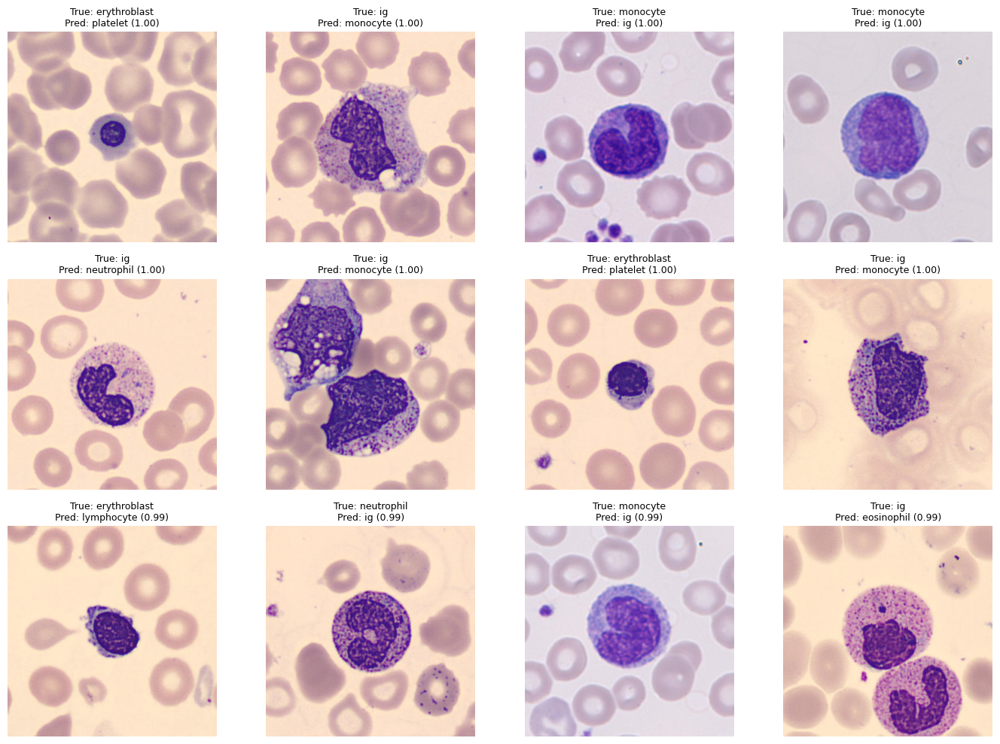

In [47]:
# Error counts by category + the most confident test mistakes. No model is run.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

final_dir = Path("/kaggle/working/final_evaluation")
pred_file = final_dir / "test_predictions.csv"
if not pred_file.is_file():
    raise FileNotFoundError("Run cell 37 (or restore the backup) first.")

pred = pd.read_csv(pred_file)
errors = pred[~pred["Correct"]].copy()

by_class = pred.groupby("True label").size().rename("Test images").to_frame()
by_class["Mistakes"] = errors.groupby("True label").size().reindex(
    by_class.index, fill_value=0)
by_class["Recall (%)"] = (
    100 * (1 - by_class["Mistakes"] / by_class["Test images"])).round(2)

pairs = (errors.groupby(["True label", "Predicted label"]).size()
         .reset_index(name="Mistakes")
         .sort_values("Mistakes", ascending=False).reset_index(drop=True))

by_class.to_csv(final_dir / "test_errors_by_class.csv")
pairs.to_csv(final_dir / "test_error_pairs.csv", index=False)

print(f"Test images: {len(pred):,} | Mistakes: {len(errors):,}")
print("\nMost frequent confusions:"); display(pairs.head(10))
print("\nBy true category:"); display(by_class)

top = errors.sort_values("Highest predicted probability",
                         ascending=False).head(12)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
    ax.imshow(Image.open(r["filepath"]).convert("RGB"))
    ax.set_title(f"True: {r['True label']}\nPred: {r['Predicted label']} "
                 f"({r['Highest predicted probability']:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(final_dir / "top_test_mistakes.png", dpi=150, bbox_inches="tight")
plt.show()

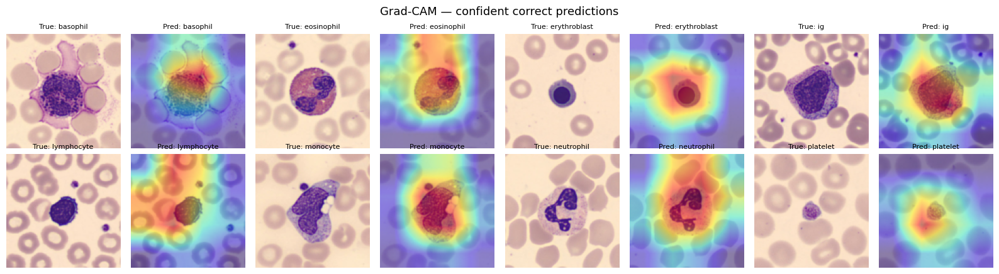

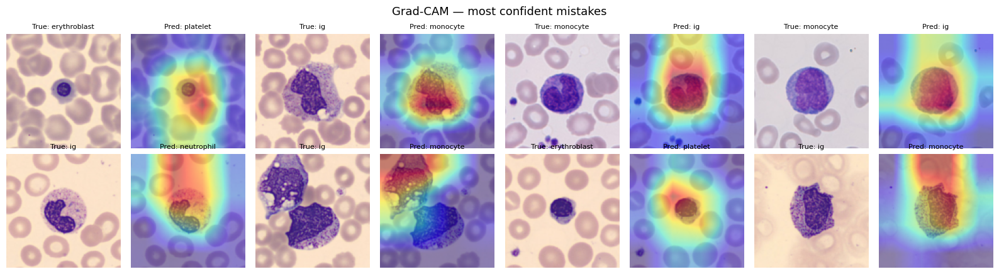

In [48]:
# Grad-CAM for the fine-tuned MobileNetV2 on saved test predictions.
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

final_dir = Path("/kaggle/working/final_evaluation")
ckpt = Path("/kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras")
if not ckpt.is_file():
    raise FileNotFoundError(f"Missing model: {ckpt}")

model = tf.keras.models.load_model(str(ckpt), compile=False)
classes = pd.read_csv(final_dir / "test_auc.csv")["Category"].tolist()

# Split the model into: layers before the MobileNetV2 base, the base, the head.
base_idx = next(i for i, l in enumerate(model.layers)
                if isinstance(l, tf.keras.Model))
pre, base, head = (model.layers[1:base_idx], model.layers[base_idx],
                   model.layers[base_idx + 1:])

def load_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3,
                             expand_animations=False)
    return tf.image.resize(img, (128, 128), antialias=True)

def gradcam(img):
    x = img[None]
    for l in pre:
        x = l(x, training=False)
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        y = conv
        for l in head:
            y = l(y, training=False)
        cls = int(tf.argmax(y[0]))
        score = y[:, cls]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    cam = tf.image.resize(cam[..., None], (128, 128)).numpy()[..., 0]
    return cam, cls

def show(rows, title, fname, ncols=4):
    nrows = int(np.ceil(len(rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols * 2, figsize=(ncols * 4, nrows * 2.2))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for k, (_, r) in enumerate(rows.iterrows()):
        img = load_img(r["filepath"])
        cam, cls = gradcam(img)
        a, b = axes[k // ncols, 2 * (k % ncols)], axes[k // ncols, 2 * (k % ncols) + 1]
        a.imshow(img.numpy().astype("uint8"))
        b.imshow(img.numpy().astype("uint8")); b.imshow(cam, cmap="jet", alpha=0.45)
        a.set_title(f"True: {r['True label']}", fontsize=8)
        b.set_title(f"Pred: {classes[cls]}", fontsize=8)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.savefig(final_dir / fname, dpi=150, bbox_inches="tight")
    plt.show()

pred = pd.read_csv(final_dir / "test_predictions.csv")
correct = (pred[pred["Correct"]].sort_values("Highest predicted probability",
           ascending=False).groupby("True label").head(1).sort_values("True label"))
wrong = pred[~pred["Correct"]].sort_values("Highest predicted probability",
        ascending=False).head(8)

show(correct, "Grad-CAM — confident correct predictions", "gradcam_correct.png")
show(wrong, "Grad-CAM — most confident mistakes", "gradcam_mistakes.png")


Predicting: Small CNN
Predicting: MobileNetV2 — frozen
Predicting: MobileNetV2 — fine-tuned
                   Model  Macro AUC
MobileNetV2 — fine-tuned     0.9986
               Small CNN     0.9970
                 XGBoost     0.9969
    MobileNetV2 — frozen     0.9967
                 Bagging     0.9930
           Random Forest     0.9925
                     MLP     0.9918
     Logistic Regression     0.9904
             Extra Trees     0.9892
        SVM — Polynomial     0.9857
            SVM — Linear     0.9845
               SVM — RBF     0.9837
                AdaBoost     0.9791
                     KNN     0.9313
           Decision Tree     0.9112


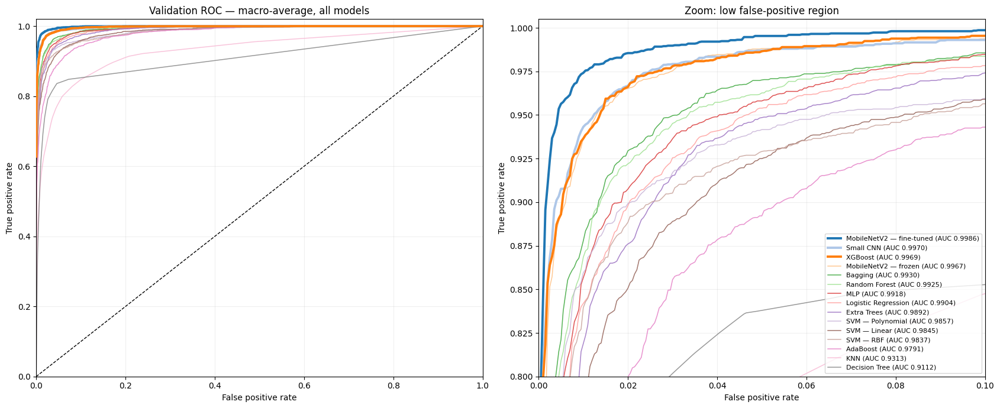

Saved to: /kaggle/working/results


In [50]:
# Combined validation ROC (macro-average, one-vs-rest) for all 15 models.
# Uses validation data only; the test set is not touched.
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

out_dir = Path("/kaggle/working/results")
out_dir.mkdir(parents=True, exist_ok=True)

classes = list(CLASS_NAMES)
y_val = validation_df["label"].to_numpy()
assert np.array_equal(y_val, np.asarray(y_validation)), "Row order mismatch"

# Scores from each model, columns reordered to match `classes`.
scores = {}

def reorder(raw, model_classes):
    names = [str(c) for c in model_classes]
    return raw[:, [names.index(c) for c in classes]]

sk_models = {
    "Logistic Regression": "logistic_regression",
    "SVM — RBF": "svm_rbf",
    "SVM — Polynomial": "svm_polynomial",
    "SVM — Linear": "svm_linear",
    "Random Forest": "random_forest",
    "XGBoost": "xgboost",
    "KNN": "knn",
    "Decision Tree": "decision_tree",
    "Bagging": "bagging",
    "Extra Trees": "extra_trees",
    "AdaBoost": "adaboost",
    "MLP": "mlp",
}
for label, fname in sk_models.items():
    m = joblib.load(f"/kaggle/working/models/{fname}.joblib")
    raw = (m.predict_proba(X_validation_selected)
           if hasattr(m, "predict_proba")
           else m.decision_function(X_validation_selected))
    if fname == "xgboost":
        model_classes = xgb_label_encoder.inverse_transform(m.classes_)
    else:
        model_classes = m.classes_
    scores[label] = reorder(raw, model_classes)

# Image models (same validation order as validation_df).
val_ds = make_cnn_dataset(validation_df, training=False)
for label, path in {
    "Small CNN": "/kaggle/working/cnn/best_small_cnn.keras",
    "MobileNetV2 — frozen": "/kaggle/working/transfer_learning/best_mobilenetv2_head.keras",
    "MobileNetV2 — fine-tuned": "/kaggle/working/transfer_learning/best_mobilenetv2_finetuned.keras",
}.items():
    print("Predicting:", label, flush=True)
    net = tf.keras.models.load_model(path, compile=False)
    scores[label] = net.predict(val_ds, verbose=0)  # columns follow CLASS_NAMES

# Macro-average ROC for each model.
grid = np.linspace(0, 1, 2001)
curves, rows = {}, []
for label, s in scores.items():
    assert s.shape == (len(y_val), len(classes)), label
    tprs, aucs = [], []
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve((y_val == c).astype(int), s[:, k])
        tprs.append(np.interp(grid, fpr, tpr))
        aucs.append(auc(fpr, tpr))
    curves[label] = np.mean(tprs, axis=0)
    rows.append({"Model": label, "Macro AUC": float(np.mean(aucs))})

auc_table = (pd.DataFrame(rows).sort_values("Macro AUC", ascending=False)
             .reset_index(drop=True))
auc_table.to_csv(out_dir / "combined_roc_validation_auc.csv", index=False)
print(auc_table.round(4).to_string(index=False))

# Plot: full view and zoom on the low false-positive corner.
top3 = set(auc_table["Model"].head(3))
cmap = plt.get_cmap("tab20")
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for i, row in auc_table.iterrows():
    lab = row["Model"]
    kw = dict(lw=2.8, zorder=3) if lab in top3 else dict(lw=1.1, alpha=0.8)
    for ax in axes:
        ax.plot(grid, curves[lab], color=cmap(i % 20),
                label=f"{lab} (AUC {row['Macro AUC']:.4f})", **kw)

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="Validation ROC — macro-average, all models",
            xlabel="False positive rate", ylabel="True positive rate",
            xlim=(0, 1), ylim=(0, 1.02))
axes[1].set(title="Zoom: low false-positive region",
            xlabel="False positive rate", ylabel="True positive rate",
            xlim=(0, 0.1), ylim=(0.8, 1.005))
for ax in axes:
    ax.grid(alpha=0.2)
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(out_dir / "combined_roc_validation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to:", out_dir)

In [51]:
# Final backup. Fails loudly if the fine-tuned model is missing.
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib, json

root = Path("/kaggle/working")
model_file = root / "transfer_learning" / "best_mobilenetv2_finetuned.keras"
if not model_file.is_file():
    raise FileNotFoundError(
        "Fine-tuned model is missing. Restore it (attach the earlier zip or "
        "rerun cell 33) before backing up.")

h = hashlib.sha256(model_file.read_bytes()).hexdigest()
sel = json.loads((root / "final_evaluation/model_selection.json").read_text())
print("Model size (MB):", round(model_file.stat().st_size / 1024**2, 1))
print("SHA-256 matches selection record:", h == sel["checkpoint_sha256"])

out = root / "blood_cell_project_final.zip"
folders = ["data_checks", "splits", "features", "results", "models", "cnn",
           "transfer_learning", "cross_validation", "final_evaluation"]
with ZipFile(out, "w", ZIP_DEFLATED) as z:
    for name in folders:
        d = root / name
        n = 0
        if d.is_dir():
            for f in d.rglob("*"):
                if f.is_file():
                    z.write(f, f.relative_to(root)); n += 1
        print(f"{name}: {n} files")
with ZipFile(out) as z:
    assert "transfer_learning/best_mobilenetv2_finetuned.keras" in z.namelist()
print(f"\n{out.name}: {out.stat().st_size / 1024**2:.1f} MB — model included.")

Model size (MB): 22.0
SHA-256 matches selection record: True
data_checks: 8 files
splits: 5 files
features: 4 files
results: 56 files
models: 13 files
cnn: 3 files
transfer_learning: 28 files
cross_validation: 7 files
final_evaluation: 15 files

blood_cell_project_final.zip: 205.0 MB — model included.
